<img src = "https://drive.google.com/uc?export=view&id=1FpwoiW7eC_aEKJ53NReEyrW8qAR3RFs0" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento del Negocio y Carga de Datos**
---

Este notebook se construye para la primera etapa del proyecto que consiste en definir el entendimiento del negocio y carga de datos de un problema de Machine Learning.

**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008 (UCI Machine Learning Repository)

**Contenido**

Marco de proyecto: trasfondo del negocio, alcance y objetivos
Datos: origen y carga o adquisición de datos

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. **DIANA CELIA ZAMBRANO PINTO**
2. **JUAN DAVID TULANDE GUTIERREZ**
3. **JESUS ESCOBAR DIZZ**

## **1. Marco de Proyecto**
---
Como marco del proyecto para mostrar los resultados del entendimiento del negocio, se da respuesta a los siguientes elementos:

### **1.1. Trasfondo del Negocio**
---

- ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?
- ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

##¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?

**Dominio:** salud (medicina), en particular **gestión hospitalaria y calidad de la atención** de pacientes con diabetes.

**Cliente (supuesto del ejercicio):** el área de calidad o de gestión del egreso hospitalario de una institución de salud. Es el equipo que decide a qué pacientes se les ofrece seguimiento después del alta. Los datos reales provienen de 130 hospitales de Estados Unidos y redes de prestación de servicios integrados de EE. UU., pero el proyecto es un ejercicio académico y el cliente es hipotético.

| Beneficiario | Cómo se beneficia |
|---|---|
| **Pacientes con diabetes** | Reciben seguimiento oportuno y evitan una nueva hospitalización y sus riesgos (infecciones, complicaciones). |
| **Equipo clínico y de enfermería de seguimiento** | Obtiene una lista priorizada para organizar sus llamadas y controles con tiempo limitado. |
| **Equipo directivo de la institución** | Mejora un indicador de calidad (readmisión a 30 días) y libera camas y recursos. |
| **Aseguradores / sistema de salud** | Reduce un gasto evitable. |

##¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

1. **Readmisiones tempranas.** Una *readmisión* es una nueva hospitalización después de un alta. Cuando ocurre dentro de los **30 días**, suele indicar que la transición del hospital a la casa falló:
   alta prematura, tratamiento mal ajustado, poca educación sobre los medicamentos o falta de un control médico oportuno.
2. **Recursos de seguimiento limitados.** Llamadas, citas de control y visitas domiciliarias no alcanzan para todos los pacientes, por lo que hay que **decidir a quiénes priorizar**.
3. **Priorización poco sistemática.** Hoy la decisión depende del criterio individual o de reglas generales (por ejemplo, "todos los mayores de 65 años") que no aprovechan de forma completa la información disponible al momento del alta.

**Pregunta de negocio:** *al momento del alta, ¿qué pacientes con diabetes tienen mayor probabilidad de ser readmitidos en menos de 30 días?*

### **1.2. Alcance**
---

- ¿Qué  solución se desea implementar?
- ¿Cuáles son los límites y fronteras del proyecto de *machine learning*? ¿Qué aspectos específicos del negocio se incluirán y cuáles se excluyen en el alcance del proyecto?
- ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

### ¿Qué solución se desea implementar?

Un **modelo de machine learning** que, con la información de cada hospitalización disponible al momento del alta, estime la **probabilidad de readmisión en menos de 30 días**
y con ella genere un **listado de pacientes ordenado por riesgo**.

| Elemento | Definición |
|---|---|
| **Unidad de análisis** | Una hospitalización (una fila del dataset). |
| **Variable objetivo** | `readmitido_30d`: **1** si en `readmitted` aparece `<30`; **0** si aparece `>30` o `NO`. |
| **Momento de la predicción** | Al alta del paciente; solo se usan datos conocidos en ese momento. |
| **Producto** | Un modelo validado y un análisis de sus resultados, desarrollado en Python. |

### ¿Cuáles son los límites y fronteras del proyecto? ¿Qué aspectos se incluyen y cuáles se excluyen?

| Se incluye | Se excluye |
|---|---|
| Hospitalizaciones de pacientes con diabetes del dataset *Diabetes 130-US* (1999-2008). | Datos de otras enfermedades, otros países o fechas posteriores a 2008. |
| Predicción de **un solo desenlace**: readmisión en menos de 30 días (sí/no). | Predecir mortalidad, costos, duración de la estancia u otros desenlaces. |
| Uso exclusivo de variables que se conocen **hasta el alta**. | Información posterior al alta (evita la *fuga de datos*). |
| Todo el ciclo de ML: entendimiento, preparación, modelamiento, validación y evaluación. | Puesta en producción, integración con la historia clínica electrónica e interfaz de usuario. |
| Comparación de varios modelos de clasificación frente a una línea base. | Explicar **causas** de la readmisión: el modelo detecta asociaciones, no demuestra que algo cause algo. |
| Revisión de los riesgos del dataset: desbalance de clases, pacientes repetidos, fallecidos. | Diseñar o evaluar el programa de seguimiento (qué intervención hacer y su efecto). |
| Reporte de limitaciones y supuestos. | Readmisiones en instituciones que no están en la base. |

### ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

Si el modelo se implementara en una institución, el flujo de uso previsto sería el siguiente:

1. **Al alta**, el sistema calcula la probabilidad de readmisión a 30 días de cada paciente con los datos de su hospitalización.
2. El equipo de seguimiento recibe la **lista ordenada de mayor a menor riesgo**.
3. Según su capacidad (por ejemplo, 20 pacientes por semana), el equipo contacta primero a los de **mayor riesgo**: llamada en los primeros días, cita de control temprana, repaso de los medicamentos.
4. La **decisión clínica final siempre es del profesional de salud**; el modelo es solo una herramienta de apoyo para priorizar.

## **Objetivos y criterios de éxito**
---

**Objetivo de negocio:** reducir las readmisiones a 30 días en pacientes con diabetes, dirigiendo el seguimiento a quienes tienen mayor riesgo.

**Objetivo de machine learning:** Construir y validar un classificador binario que partiendo de toda la información presente en alta, sea capaz de predecir la probabilidad de readmision de un paciente con diabetes en un plazo menor a 30 días. Se considera la variable objetivo la variable readmitido30d=1 si la readmision se produce en menos de 30 días, y 0 si no.Las readmisiones que suceden a partir de los 30 días se consideran casos negativos.
**Criterios de éxito:**

- Capacidad discriminativa: El área bajo la curva ROC (ROC-AUC) en el conjunto de prueba debe ser superior a 0,5 (valor correspondiente a un modelo de predicción aleatoria).
- El área bajo la curva de precisión-exhaustividad (PR-AUC) en el conjunto de prueba debe ser mayor que la tasa de reingreso de la muestra, la cual sirve como referencia (baseline) para un modelo basado en el azar.
- Superioridad frente a un modelo lineal simple: El ROC-AUC del modelo final debe ser igual o superior al obtenido mediante una regresión logística, utilizada como referencia de complejidad mínima. Un modelo más complejo no se justifica si no supera esta métrica.
- **Sobreajuste (overfitting)**: La diferencia entre el ROC-AUC en el conjunto de entrenamiento y el ROC-AUC en el conjunto de validación debe ser inferior a 0,05, a fin de descartar modelos que memorizan los datos en lugar de generalizarlos.
- Al seleccionar el 10 % de las altas con mayor probabilidad de reingreso según el modelo, la proporción de individuos que efectivamente reingresan debe ser superior a la tasa global de reingreso.


### **1.3. Plan**
---

Puede agregar una lista de actividades con tiempos estimados, un diagrama de Gantt o integrar alguna herramienta de gestión de proyectos para mostrar la planeación del proyecto como

Durante el proycto se va a utilizar Jira como herramienta de gestión para el proyecto:[*Jira*](https://juantulande04.atlassian.net/jira/core/projects/MLU/timeline?rangeMode=WEEKS&atlOrigin=eyJpIjoiMjQ4YjNiNzcwZmRkNGJmMmJiMGIwNTUzZTMzZmExMWMiLCJwIjoiaiJ9)

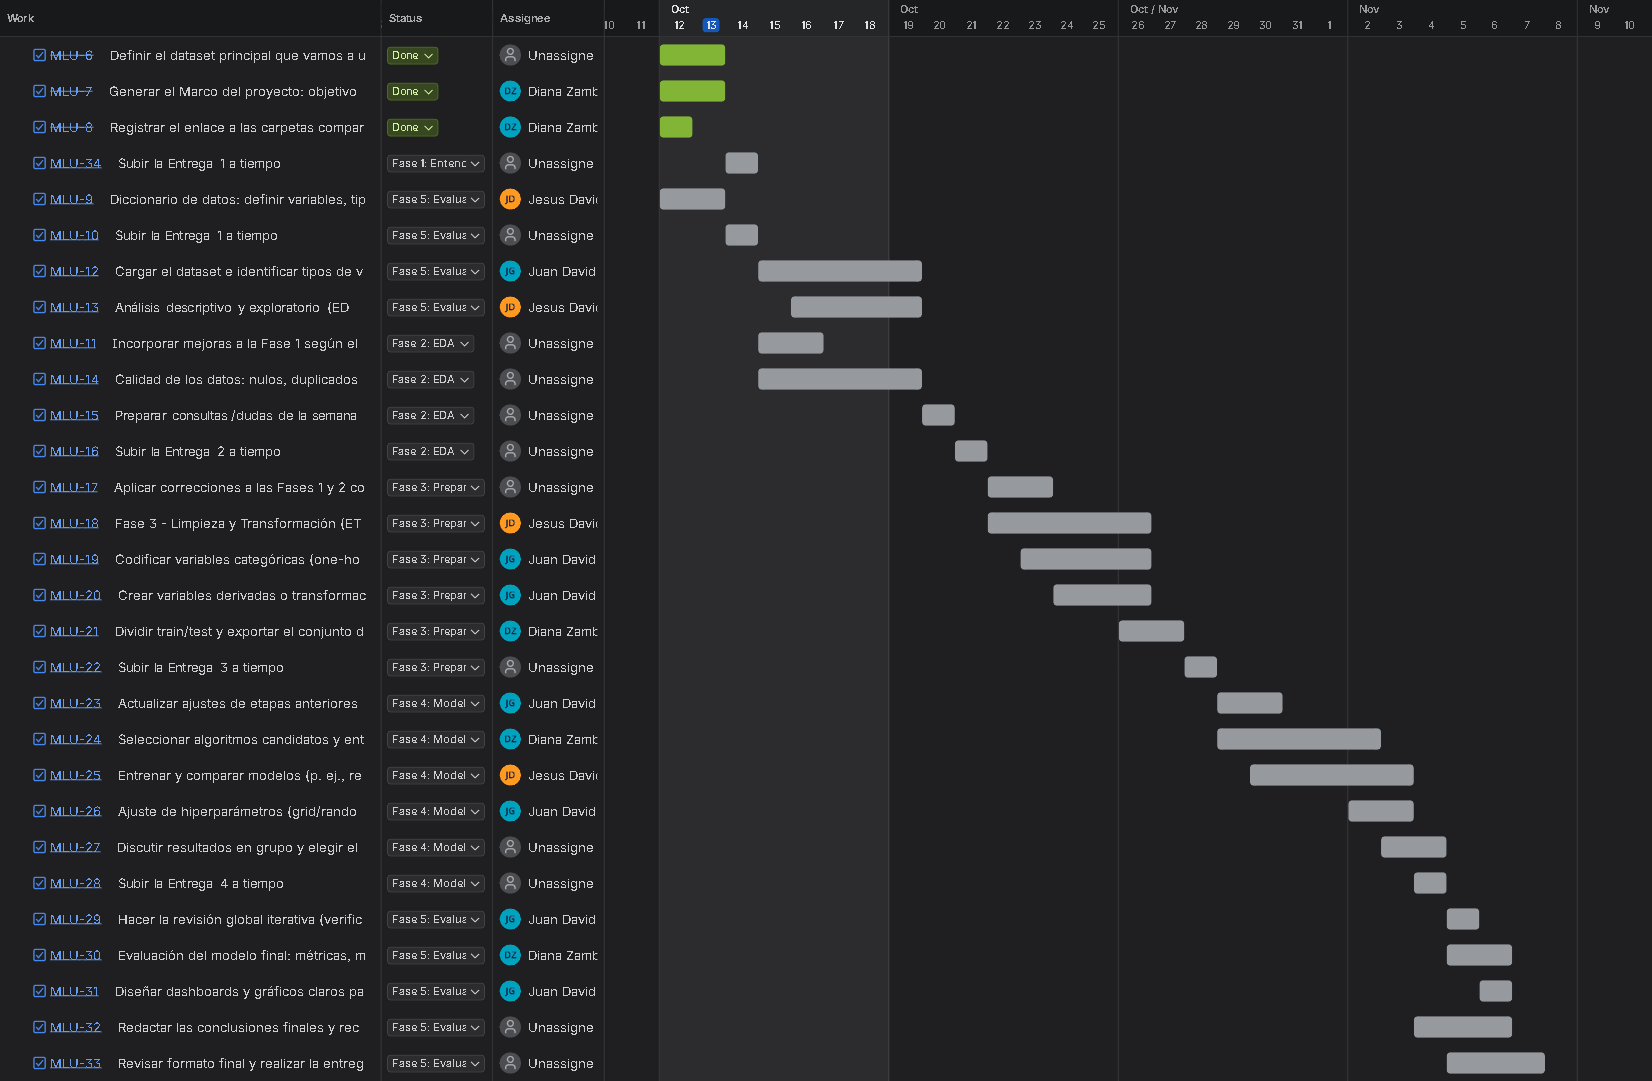


## **2. Datos**
---

En esta sección se adjunta una descripción de los datos y el código que permite su tratamiento.

### **2.1. Origen**
---

- ¿De dónde vienen los datos?
- ¿Se usa alguna herramienta o proceso para la descarga de la información?
- ¿Qué tipo de datos estamos manejando?

### ¿De dónde vienen los datos?

Del **UCI Machine Learning Repository**, dataset *Diabetes 130-US Hospitals for Years 1999-2008*. Provienen de una base clínica de **130 hospitales Y redes de prestación de servicios integrados de Estados Unidos** durante **1999-2008**.
Fueron publicados con el estudio:

> Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J. y Clore, J. N. (2014).
> *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International.

Ese estudio analizó si medir la hemoglobina glicosilada (HbA1c, examen que resume el control de la glucosa en los últimos meses) durante la hospitalización se relaciona con menos readmisiones.
Aquí se reutilizan los datos con otro propósito: **construir un modelo predictivo**.

### ¿Qué tipo de datos estamos manejando?

Datos **estructurados, en formato tabular** (archivo CSV), **transversales** (cada fila es una hospitalización) y **etiquetados** (traen la variable a predecir), por lo que es un problema de aprendizaje supervisado.
Aproximadamente **101.766 hospitalizaciones × 50 variables**; la verificación de la sección 2.2 lo confirma al ejecutar el código.

| Tipo de dato | Variables (ejemplos) | Observación |
|---|---|---|
| **Identificadores** | `encounter_id`, `patient_nbr` | Solo identifican; no se usan para predecir. Un paciente puede tener varias hospitalizaciones. |
| **Categóricas nominales** | `race`, `gender`, `medical_specialty`, `payer_code` | Categorías sin orden natural. |
| **Categórica ordinal por rangos** | `age` (por ejemplo `[70-80)`) | Rangos de edad de 10 años, con orden. |
| **Numéricas (conteos y medidas)** | `time_in_hospital`, `num_lab_procedures`, `num_medications`, `number_inpatient` | Días de estancia, exámenes, medicamentos y hospitalizaciones previas. |
| **Códigos numéricos que representan categorías** | `admission_type_id`, `discharge_disposition_id`, `admission_source_id` | No son cantidades; su significado está en `IDs_mapping.csv`. |
| **Códigos de diagnóstico (CIE-9)** | `diag_1`, `diag_2`, `diag_3` | Texto con muchos valores distintos; habrá que agruparlos. |
| **Resultados de exámenes (categóricos)** | `A1Cresult`, `max_glu_serum` | Incluyen el valor `None` = "el examen no se realizó". |
| **Medicamentos (~23 columnas)** | `metformin`, `insulin`, `glipizide`, … | Cuatro categorías: `No`, `Steady` (dosis estable), `Up` (aumentó), `Down` (disminuyó). |
| **Variable objetivo** | `readmitted` → `readmitido_30d` | `<30`, `>30`, `NO`; el modelo usa 1 = `<30` y 0 = el resto. |

###¿Se usa alguna herramienta o proceso para la descarga de la información?
El conjunto de datos se alojará en un repositorio de GitHub. El proceso de acceso y descarga consistirá en obtener la URL del archivo almacenado en el repositorio y utilizarla para cargar la información directamente desde el entorno de trabajo, Collab en nuestro caso. De esta manera, se podrá acceder a los datos y cargarlos para su posterior limpieza, transformación y análisis, sin necesidad de realizar una descarga manual en el equipo local.

### **2.2. Carga o Adquisición de Datos**
---

Agregue el código necesario en _Python_ para obtener o cargar los datos.

In [ ]:
#IMPORTAR LOS DATOS DESDE GITHUB

import pandas as pd
#Link con la data
url = 'https://raw.githubusercontent.com/jdizz0414/Data/refs/heads/main/diabetic_data.csv'

# Cargamos los datos utilizando pandas
df = pd.read_csv(url)

# Mostramos las primeras filas del DataFrame para verificar la carga
df.head(20)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# Información general del conjunto de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

# LINK CON INFORMACION SOBRE EL DATASET EN GENERAL

https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*

<img src="https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt="Encabezado MLDS" width="100%">

# Entendimiento y Preparación de los Datos
---

Este notebook se construye para la segunda etapa del proyecto que consiste en definir el entendimiento de los datos


**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008 (UCI Machine Learning Repository)

**Contenido**
Resumen General
Análisis Exploratorio de datos
Resumen de Calidad de datos
Tipos de Variables



## 0. Integrantes del equipo de trabajo
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. **DIANA CELIA ZAMBRANO PINTO**
2. **JUAN DAVID TULANDE GUTIERREZ**
3. **JESUS ESCOBAR DIZZ**

## 1. Análisis Exploratorio de los Datos
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

### 1.1. Resumen General
---

- ¿Cuántos documentos/registros tiene el dataset?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

In [ ]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import io
import urllib.request
from pathlib import Path

In [ ]:
# Configuración de estilo para visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Importación del conjunto de datos desde GitHub
RUTA = "https://raw.githubusercontent.com/jdizz0414/Data/refs/heads/main/diabetic_data.csv"


def leer_bytes(ruta):
    """Lee el archivo completo, sea una dirección web o un archivo local."""
    if str(ruta).startswith("http"):
        peticion = urllib.request.Request(ruta, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(peticion, timeout=60) as respuesta:
            return respuesta.read()
    return Path(ruta).read_bytes()

contenido = leer_bytes(RUTA)

# na_values=["?"]        -> '?' es dato faltante
# keep_default_na=False  -> 'None' NO es faltante (significa "examen no realizado")
df = pd.read_csv(io.BytesIO(contenido), na_values=["?"], keep_default_na=False)

# Estandarización de nombres de columnas
df.columns = [col.lower().replace(" ", "_") for col in df.columns]

# Variable objetivo binaria: 1 = readmitido en menos de 30 días; 0 = cualquier otro caso
df["readmitido_30d"] = (df["readmitted"] == "<30").astype("int8")

# Lista de las columnas de medicamentos (están entre 'a1cresult' y 'change')
inicio, fin = df.columns.get_loc("metformin"), df.columns.get_loc("change")
medicamentos = list(df.columns[inicio:fin])

formato_miles = lambda x: f"{x:,.0f}".replace(",", ".")
print(f"Datos cargados: {formato_miles(len(df))} filas x {df.shape[1]} columnas "
      f"(incluye 'readmitido_30d', creada aquí). Columnas de medicamentos: {len(medicamentos)}")

/tmp/ipykernel_993/3922523373.py:21: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(io.BytesIO(contenido), na_values=["?"], keep_default_na=False)


Datos cargados: 101.766 filas x 51 columnas (incluye 'readmitido_30d', creada aquí). Columnas de medicamentos: 23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 51 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
#VISTA PREVIA DE LOS DATOS
df.head(20)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,readmitted,readmitido_30d
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,0
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,None,None,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30,0
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0


In [ ]:
tam_archivo_mb = len(contenido) / 1e6
tam_memoria_mb = df.memory_usage(deep=True).sum() / 1e6   # deep=True mide también el texto

print(f"Registros (hospitalizaciones): {formato_miles(len(df))}")
print(f"Columnas: {df.shape[1] - 1} originales (+1 creada: readmitido_30d)")
print("Formato del archivo: CSV (valores separados por comas), tabla de filas y columnas")
print(f"Tamaño del archivo en disco: {tam_archivo_mb:.1f} MB")
print(f"Tamaño en memoria (pandas):  {tam_memoria_mb:.1f} MB")

print("\nTipos de datos por columna:")
print(df.dtypes.astype(str).value_counts().rename("n.º de columnas").to_string())

Registros (hospitalizaciones): 101.766
Columnas: 50 originales (+1 creada: readmitido_30d)
Formato del archivo: CSV (valores separados por comas), tabla de filas y columnas
Tamaño del archivo en disco: 19.2 MB
Tamaño en memoria (pandas):  202.7 MB

Tipos de datos por columna:
object    37
int64     13
int8       1


**Respuestas:**

- **¿Cuántos registros contiene el dataset?**  
  Al obtener la información del dataset por medio de `.info()`, el número de registros del conjunto de datos es de **101,766** registros; cada uno es una hospitalización de un paciente con diabetes. Tiene 50 columnas originales.

- **¿En qué formato están guardados los datos?**
  Como se observa en la línea de codigo que trae la informacion desde el repositorio, el formato de los datos es .csv  
  

- **¿Qué tamaño en MB tiene el conjunto de datos?**  
  Tamaño del archivo en disco: 19.2 MB. Tamaño en memoria (pandas):  202.7 MB

### 1.2. Resumen de la Calidad de los datos
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

In [ ]:
# Evaluación de duplicados exactos
duplicados = df.duplicated().sum()
print(f"Total de filas duplicadas exactas: {duplicados}")

# Evaluación de porcentaje de datos faltantes por columna
porcentaje_nulos = (df.isna().sum() / len(df)) * 100
df_nulos = pd.DataFrame({"Registros Nulos": df.isna().sum(), "Porcentaje (%)": porcentaje_nulos.round(2)})
df_nulos = df_nulos[df_nulos["Registros Nulos"] > 0].sort_values(by="Porcentaje (%)", ascending=False)

print("\nVARIABLES CON DATOS FALTANTES")
display(df_nulos.head(10))

Total de filas duplicadas exactas: 0

VARIABLES CON DATOS FALTANTES


,Registros Nulos,Porcentaje (%)
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


Respuestas:

- **¿Se detecta la ausencia de datos...?**
Sí, hay una cantidad enorme de datos perdidos en la variable weight. Casi el 97% de los registros están vacíos. También pasa algo similar con medical_specialty, que tiene cerca del 49% de faltantes, y payer_code, cerca del 40%; race el 2,2 %; diag_1, diag_2 y diag_3 entre 0,02 % y 1,4 %. Habrá que ver si se eliminan o se hace algún tipo de imputación cuando nos pongamos con la preparación.

a1cresult y max_glu_serum NO tienen datos faltantes: el valor None indica que el examen no se realizó. La HbA1c se midió en 17.018 hospitalizaciones (16,7 %) y la glucosa en 5.346 (5,3 %). Esto es información útil: que se haya medido o no es una característica de la atención

- **¿Se identifican registros con datos ilegibles o con dificultades de codificación?**
No se ven problemas graves en ese sentido. Lo único es que los campos vacíos venían marcados con un signo de interrogación, Por lo cual se cambió a NaN para que pandas los reconozca bien al trabajar.

- **¿Se observa una diversidad de formatos...?**

En general la estructura está bien. A continuación lo observado:

age viene como texto en rangos (por ejemplo [70-80)), no como número.

Los diagnósticos diag_1, diag_2 y diag_3 mezclan códigos numéricos y alfanuméricos (que empiezan con V o E).

admission_type_id, discharge_disposition_id y admission_source_id son números que representan categorías, no cantidades.

Las variables de medicamentos como insulin o metformin como por mencionar, son categorías ordinales, con valores tipo No, Steady, Up o Down, así que en la fase de preparación se deberán que codificar para poder trabajarlas en los modelos.

- **¿Se identificaron y abordaron posibles problemas...?**
- **Duplicados**: El conjunto no presenta duplicados exactos (0 filas), lo cual es coherente con su diseño de registros únicos (`encounter_id`). Pero un mismo paciente (patient_nbr) sí aparece en varias hospitalizaciones. Esto obliga a dividir los datos por paciente más adelante, para que el modelo no vea al mismo paciente en el entrenamiento y en la prueba.

- **Valores atípicos**: En variables numéricas como `num_medications` (máx. 81) o `time_in_hospital` (máx. 14), los valores máximos son clínicamente posibles. No se consideran errores, sino pacientes de alta complejidad.

- **Datos faltantes**: Como se mencionó, `weight` tiene una tasa de ausencia crítica (>95%), por lo que su utilidad predictiva es cuestionable y se evaluará su eliminación en fases posteriores.



In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

vars_plot = ["time_in_hospital", "num_medications", "number_diagnoses"]

for ax, v in zip(axes, vars_plot):
    sns.boxplot(data=df, x="readmitted", y=v, ax=ax)
    ax.set_title(v, weight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

### 1.3. Tipos de variables
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

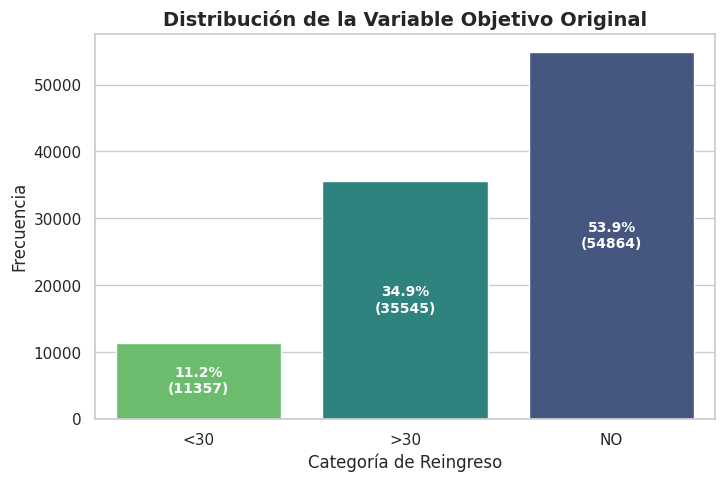


 ESTADÍSTICAS DESCRIPTIVAS


,time_in_hospital,num_lab_procedures,num_medications,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00
mean,4.40,43.10,16.02,7.42
std,2.99,19.67,8.13,1.93
min,1.00,1.00,1.00,1.00
25%,2.00,31.00,10.00,6.00
50%,4.00,44.00,15.00,8.00
75%,6.00,57.00,20.00,9.00
max,14.00,132.00,81.00,16.00


In [ ]:
# Visualización de la distribución de la variable objetivo
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='readmitted', order=['<30', '>30', 'NO'], hue='readmitted', legend=False, palette='viridis')

plt.title('Distribución de la Variable Objetivo Original', fontsize=14, fontweight='bold')
plt.xlabel('Categoría de Reingreso', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# Añadir etiquetas de porcentaje y conteo sobre las barras
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%\n({int(height)})'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.show()

# Estadísticas descriptivas rápidas de variables numéricas clave
print("\n ESTADÍSTICAS DESCRIPTIVAS")
display(df[['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_diagnoses']].describe().round(2))

Respuestas:

- **¿El conjunto de datos tiene una variable objetivo a estimar...?**

Efectivamente, los datos presentan una variable objetivo definida: readmitted (Reingreso). Se trata de una variable de tipo categórica nominal que agrupa tres categorías: <30 (reingreso inferior a 30 días), >30 (reingreso posterior a 30 días) y NO (ausencia de reingreso).
Esta variable es importante debido a que los reingresos tempranos son penalizados bajo leyes norteamericanas. Debido a que pudieron haber posibles fallas en la atención médica, por lo que determinar quienes son más propensos a estar en alta significa un dato importante a nivel hospitalario.

- **Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.**

Y se puede ver que hay un gran desbalance en la variable que queremos analizar. La clase más grande, que es NO, abarca el 53,9% de los casos. Por otro lado, los casos de reingreso se dividen entre aquellos que vuelven a aparecer más tarde, que son el 35%, y los que tienen un mayor riesgo de reingreso, que son el 11%. Este es un punto muy importante. Si se usa un modelo básico, podría parecer que funciona bien, ya que simplemente adivina la opción NO la mayoría de las veces.

- **¿El conjunto de datos cuenta con otras variables adicionales...?**

Así es. Se integrarán atributos demográficos (age, gender, race), parámetros relativos al uso de servicios médicos (time_in_hospital, num_medications, number_diagnoses) y métricas clínicas vinculadas al control glucémico (max_glu_serum, a1cresult). Por otro lado, las variables de carácter identificativo (encounter_id, patient_nbr) se descartarán en la fase de modelado con el fin de prevenir problemas de sobreajuste. La estancia hospitalaria media es de 4 días y la media de fármacos administrados asciende a 16, indicadores que dan cuenta de una población con un perfil clínico de elevada complejidad.



/tmp/ipykernel_993/1343110145.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_copy, x='readmitted', order=['SI', 'NO'], palette='viridis')


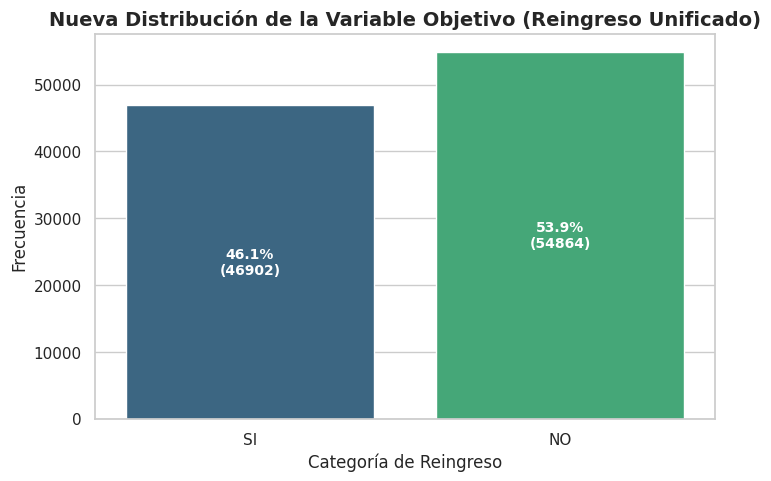

In [ ]:
# 1. Crear una copia del DataFrame
df_copy = df.copy()

# 2. Unificar las clases '<30' y '>30' en 'YES'
df_copy['readmitted'] = df_copy['readmitted'].replace({'<30': 'SI', '>30': 'SI'})

# 3. Graficar la nueva distribución de la variable objetivo
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_copy, x='readmitted', order=['SI', 'NO'], palette='viridis')

plt.title('Nueva Distribución de la Variable Objetivo (Reingreso Unificado)', fontsize=14, fontweight='bold')
plt.xlabel('Categoría de Reingreso', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# Añadir etiquetas de porcentaje y conteo sobre las barras
total = len(df_copy)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n({int(p.get_height())})'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.show()

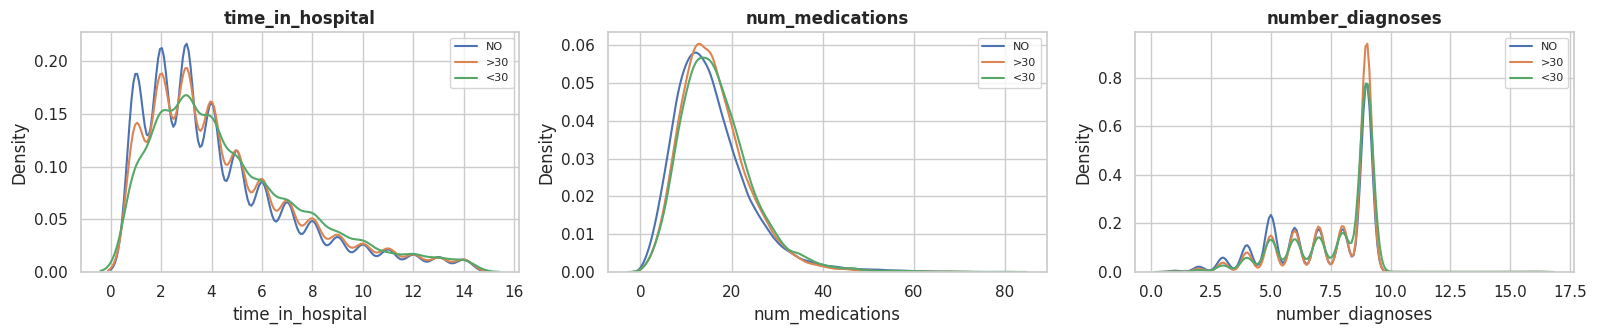

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))

for ax, v in zip(axes, vars_plot):
    for c in ["NO", ">30", "<30"]:
        mask = df["readmitted"] == c
        sns.kdeplot(data=df.loc[mask, v], label=c, ax=ax)
    ax.set_title(v, weight="bold")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Con esta unificación de las categorias de la variable objetivo de los pacientes que reinciden, se puede observar una distribucion de los datos mucho más homogénea  que la que se tenia al principio.

### 1.4. Relación Entre Variables
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

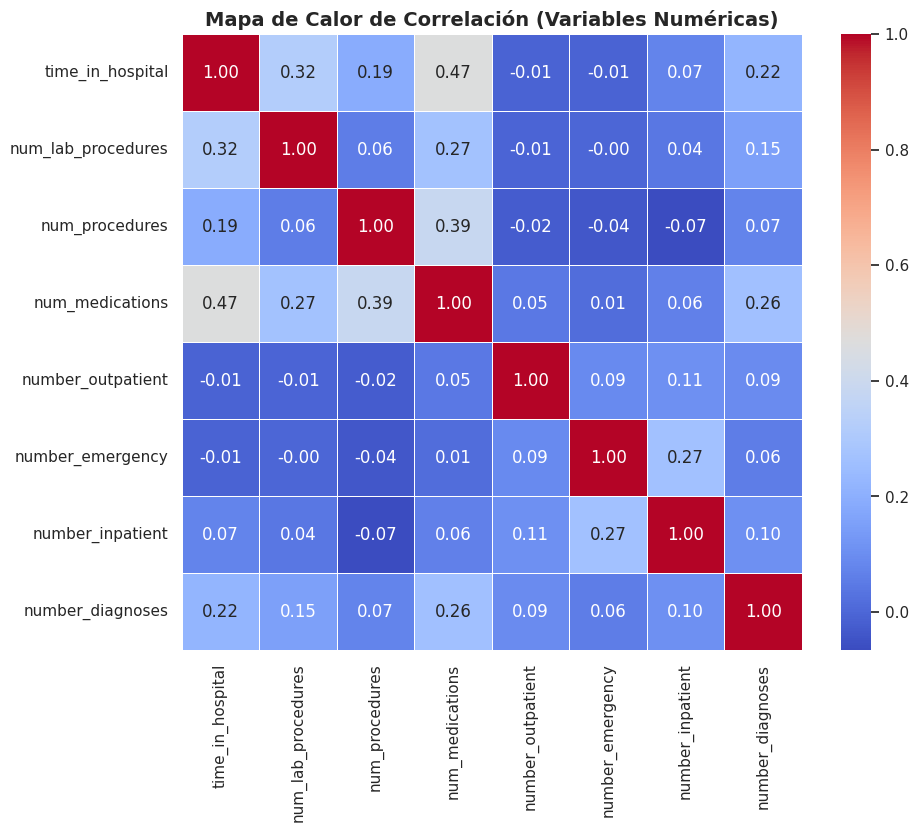

In [ ]:
# Selección de variables numéricas para la matriz de correlación
vars_numericas = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
                  'num_medications', 'number_outpatient', 'number_emergency',
                  'number_inpatient', 'number_diagnoses']

# Cálculo de la matriz de correlación
correlation_matrix = df[vars_numericas].corr()
correlation_matrix

#Visualización del mapa de calor
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Mapa de Calor de Correlación (Variables Numéricas)', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """ Calcula el coeficiente V de Cramer para dos variables categóricas. """
    # Eliminar valores nulos de forma emparejada para el cálculo de la asociación
    mask = x.notna() & y.notna()
    if mask.sum() == 0:
        return 0.0

    confusion_matrix = pd.crosstab(x[mask], y[mask])
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape

    # Corrección de sesgo de Bias para Cramer's V
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    if min((k_corr - 1), (r_corr - 1)) == 0:
        return np.sqrt(phi2_corr) # Caso límite sin corregir división por cero

    return np.sqrt(phi2_corr / min((k_corr - 1), (r_corr - 1)))

# Variables categóricas seleccionadas
variables_categoricas = ['race', 'gender', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']

# Calcular Cramer's V con respecto a 'readmitted' original (usando 'df')
resultados_original = []
for var in variables_categoricas:
    coef = cramers_v(df[var], df['readmitted'])
    resultados_original.append({'Variable': var, "Cramer's V (Original)": round(coef, 4)})

# Calcular Cramer's V con respecto a 'readmitted' unificado (usando 'df_copy')
resultados_unificado = []
for var in variables_categoricas:
    coef = cramers_v(df_copy[var], df_copy['readmitted'])
    resultados_unificado.append({'Variable': var, "Cramer's V (Unificado)": round(coef, 4)})

# Combinar y mostrar resultados en un DataFrame
df_original = pd.DataFrame(resultados_original)
df_unificado = pd.DataFrame(resultados_unificado)

df_cramers = pd.merge(df_original, df_unificado, on='Variable')
display(df_cramers.sort_values(by="Cramer's V (Unificado)", ascending=False))

,Variable,Cramer's V (Original),Cramer's V (Unificado)
4,diag_1,0.1318,0.1675
5,diag_2,0.1105,0.1484
6,diag_3,0.1048,0.1386
3,medical_specialty,0.1019,0.1340
2,payer_code,0.0622,0.0865
0,race,0.0208,0.0296
1,gender,0.0128,0.0182


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["age", "payer_code"]):
    # Normalizamos por fila para que sumen 100% y comparamos proporciones
    t = pd.crosstab(df[col].fillna("sin_dato"), df["readmitted"], normalize="index")
    t.plot(kind="barh", stacked=True, ax=ax, legend=True, edgecolor="white")
    ax.set_xlim(0, 1)
    ax.set_title(f"% readmitted por {col}", weight="bold", loc="left")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

Respuestas:

**Análisis de correlación:**

Al revisar las variables numéricas en el mapa de calor, se ve una correlación positiva moderada entre num_medications, number_diagnoses y num_lab_procedures. Tiene sentido desde el lado clínico, ya que un paciente con más diagnósticos normalmente va a tener más medicamentos y necesita más pruebas de laboratorio.Sin embargo no se observan correlaciones lineales especialmente altas entre las variables. La mayor es de aproximadamente \(0.47\), por lo que esta matriz no sugiere un problema grave de colinealidad por pares. Al analizar el resultado obtenido por el método de Cramér no se encuentran asociaciones fuertes entre las variables seleccionadas con respecto a la de respuesta tanto para el dataset original como con el que tienen la categoria de la reincidencia unificada

**Redundancia y selección:**

Esta relación apunta a una posible multicolinealidad. Por eso, durante la preparación de los datos, vamos a ver si conviene usar técnicas de reducción de dimensionalidad, como PCA, o selección de características. La idea es evitar que el modelo le dé demasiado peso a información que se repite.

Por otro lado, el dataset tiene varias columnas binarias u ordinales sobre medicamentos específicos, como metformin, insulin o glyburide. Muchas son casi iguales porque casi no tienen cambios. Lo mejor sería agruparlas o  resumir la información en variables como n_medicamentos_activos y n_medicamentos_cambiados, en vez de mantener las 23 columnas. Ya en la etapa de modelamiento, usar algún método de selección basado en importancia, como por ejemplo Random Forest, para reducir el ruido y la dimensionalidad antes de empezar a modelar.

## Créditos
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente:**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
  * [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).
    
Universidad Nacional de Colombia - Facultad de Ingeniería

**Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). Diabetes 130-US Hospitals for Years 1999-2008 [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J.**

<img src = "https://drive.google.com/uc?export=view&id=1lrzkRlmABf8ZwwCzsSvo0b2lW_IhZXkv" alt = "Encabezado MLDS" width = "100%">  </img>


# **Preparación de los datos**
---

Este notebook es una plantilla que le puede servir como guía para el tercer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**JESUS DAVID ESCOBAR DIZZ**---
2. ---**JUAN DAVID TULANDE GUTIERREZ**---
3. ---**DIANA CELIA ZAMBRANO PINTO**---

## **1. Limpieza de los Datos**
---

La elección de las técnicas de preprocesamiento puede diferir en cada conjunto de datos. Recuerde que es posible aplicar, según sea necesario (no necesariamente todas), las técnicas generales que se han explorado en el curso. La elección dependerá del tipo de datos con el que esté trabajando.

A lo largo de esta entrega, busque responder las siguientes preguntas:

- ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?
- ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?

A continuación encontrará los puntos a tratar a medida que va realizando la preparación de los datos. En cada punto defina el estado en que se encontraba el dataset, ademas de explicar y justificar las acciones y decisiones que se tomaron.

In [ ]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import urllib.request
from pathlib import Path
import matplotlib.pyplot as plt
import math

#librerías de scikit-learn que usa la sección 2
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

assert tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 2), \
    f"Actualiza scikit-learn (pip install -U scikit-learn). Versión actual: {sklearn.__version__}"

In [ ]:
# Configuración de estilo para visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Importación del conjunto de datos desde GitHub
RUTA = "https://raw.githubusercontent.com/jdizz0414/Data/refs/heads/main/diabetic_data.csv"


def leer_bytes(ruta):
    """Lee el archivo completo, sea una dirección web o un archivo local."""
    if str(ruta).startswith("http"):
        peticion = urllib.request.Request(ruta, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(peticion, timeout=60) as respuesta:
            return respuesta.read()
    return Path(ruta).read_bytes()

contenido = leer_bytes(RUTA)

# na_values=["?"]        -> '?' es dato faltante
# keep_default_na=False  -> 'None' NO es faltante (significa "examen no realizado")
df = pd.read_csv(io.BytesIO(contenido), na_values=["?"], keep_default_na=False)

# Estandarización de nombres de columnas
df.columns = [col.lower().replace(" ", "_") for col in df.columns]

# variable objetivo (1 = readmitido en menos de 30 días; 0 = cualquier otro caso)
df["readmitido_30d"] = (df["readmitted"] == "<30").astype("int8")

# Se crea una bitácora para registrar cuántas filas y columnas quedan después de cada paso
bitacora = []
def registrar(paso, datos, detalle=""):
    bitacora.append({"paso": paso, "filas": len(datos), "columnas": datos.shape[1], "detalle": detalle})


# Lista de las columnas de medicamentos (están entre 'a1cresult' y 'change')
inicio, fin = df.columns.get_loc("metformin"), df.columns.get_loc("change")
medicamentos = list(df.columns[inicio:fin])

formato_miles = lambda x: f"{x:,.0f}".replace(",", ".")
print(f"Datos cargados: {formato_miles(len(df))} filas x {df.shape[1]} columnas "
      f"(incluye 'readmitido_30d', creada aquí). Columnas de medicamentos: {len(medicamentos)}")

# Lista de variables categóricas codificadas numéricamente
variables_categoricas = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

# Convertir las variables a tipo category
df[variables_categoricas] = df[variables_categoricas].astype("category")

# Verificar los tipos de datos
print(df[variables_categoricas].dtypes)

registrar("Datos originales", df, "Archivo leído (+ columna objetivo creada)")

Datos cargados: 101.766 filas x 51 columnas (incluye 'readmitido_30d', creada aquí). Columnas de medicamentos: 23
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
dtype: object


/tmp/ipykernel_804/2965232809.py:21: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(io.BytesIO(contenido), na_values=["?"], keep_default_na=False)


In [ ]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Número de filas: 101766
Número de columnas: 51


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 51 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      99493 non-null   object  
 3   gender                    101766 non-null  object  
 4   age                       101766 non-null  object  
 5   weight                    3197 non-null    object  
 6   admission_type_id         101766 non-null  category
 7   discharge_disposition_id  101766 non-null  category
 8   admission_source_id       101766 non-null  category
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                61510 non-null   object  
 11  medical_specialty         51817 non-null   object  
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures            101

In [ ]:
#VISTA PREVIA DE LOS DATOS
df.head(20)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,readmitted,readmitido_30d
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,0
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,None,None,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30,0
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0


In [ ]:
# Valores ausentes reconocidos por pandas
print("Valores NaN:", df.isna().sum().sum())

# Cadenas vacías o compuestas únicamente por espacios
vacios = df.apply(
    lambda columna: columna.astype(str).str.strip().eq("").sum()
)

print("\nColumnas con cadenas vacías:")
print(vacios[vacios > 0])

Valores NaN: 192849

Columnas con cadenas vacías:
Series([], dtype: int64)


### **1.1. Valores faltantes**
---


In [ ]:
faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
})

faltantes = faltantes[
    faltantes["cantidad"] > 0
].sort_values(
    by="porcentaje",
    ascending=False
)

faltantes["porcentaje"] = faltantes["porcentaje"].round(2)

display(faltantes)

,cantidad,porcentaje
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [ ]:
#ANALISIS DE LA VARIABLE WEIGHT

#Identificar si el peso está ausente
df["weight_ausente"] = df["weight"].isna()

# Proporción de ausencia de peso según la readmisión
resultado = (
    df.groupby("readmitted")["weight_ausente"]
      .mean()
      .mul(100)
      .round(2)
)

print("Porcentaje de peso ausente según readmisión:")
print(resultado)

Porcentaje de peso ausente según readmisión:
readmitted
<30    96.86
>30    95.75
NO     97.58
Name: weight_ausente, dtype: float64


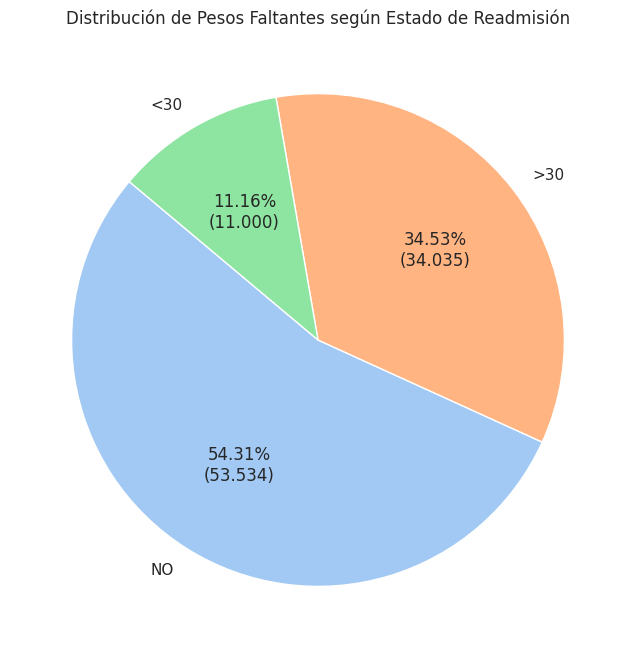

In [ ]:
# Filtrar los registros donde el peso es faltante
pesos_faltantes = df[df["weight"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos = pesos_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos,
    labels=distribucion_readmitidos.index,
    autopct=lambda pct: formatear_etiqueta(pct, distribucion_readmitidos),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Pesos Faltantes según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE MEDICAL ESPECIALTY

#Identificar registros sin especialidad médica
df["specialty_ausente"] = df["medical_specialty"].isna()

# Porcentaje de ausencia según la readmisión
resultado_specialty = (
    df.groupby("readmitted")["specialty_ausente"]
      .mean()
      .mul(100)
      .round(2)
)

print("Porcentaje de especialidad médica ausente según readmisión:")
print(resultado_specialty)

Porcentaje de especialidad médica ausente según readmisión:
readmitted
<30    50.90
>30    51.25
NO     47.30
Name: specialty_ausente, dtype: float64


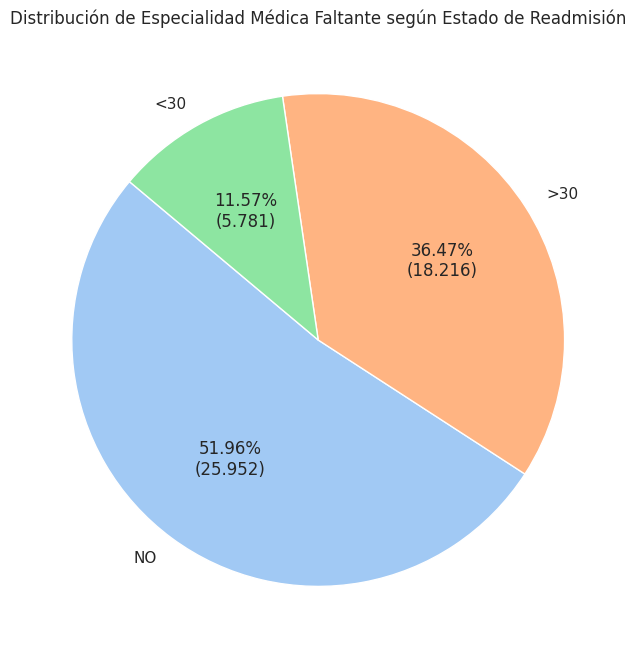

In [ ]:
# Filtrar los registros donde la especialidad médica es faltante
especialidades_faltantes = df[df["medical_specialty"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_esp = especialidades_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_esp(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_esp,
    labels=distribucion_readmitidos_esp.index,
    autopct=lambda pct: formatear_etiqueta_esp(pct, distribucion_readmitidos_esp),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Especialidad Médica Faltante según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE PAYER CODE

# Identificar registros sin código del pagador
df["payer_ausente"] = df["payer_code"].isna()

# Porcentaje de ausencia según readmisión
resultado_payer = (
    df.groupby("readmitted")["payer_ausente"]
      .mean()
      .mul(100)
      .round(2)
)

print("Porcentaje de payer_code ausente según readmisión:")
print(resultado_payer)

Porcentaje de payer_code ausente según readmisión:
readmitted
<30    40.74
>30    38.90
NO     39.74
Name: payer_ausente, dtype: float64


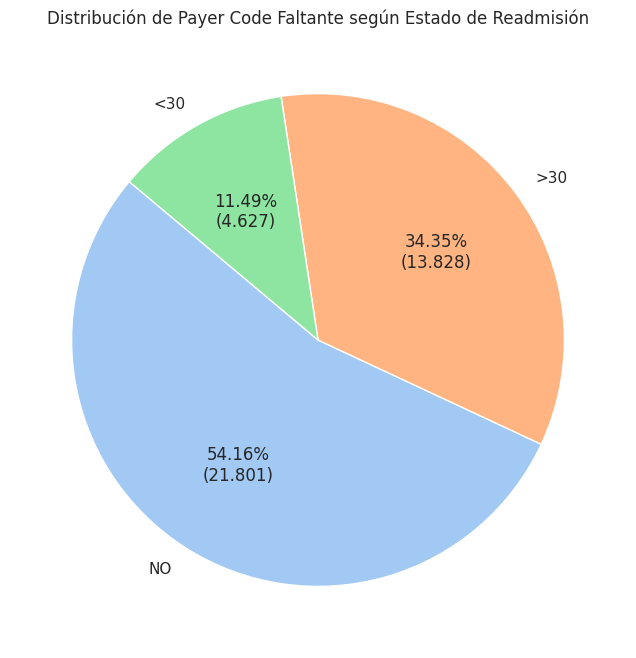

In [ ]:
# Filtrar los registros donde el código del pagador es faltante
payer_faltantes = df[df["payer_code"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_payer = payer_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_payer(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_payer,
    labels=distribucion_readmitidos_payer.index,
    autopct=lambda pct: formatear_etiqueta_payer(pct, distribucion_readmitidos_payer),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Payer Code Faltante según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE RACE

# Identificar registros sin información de raza
df["race_ausente"] = df["race"].isna()

# Porcentaje de ausencia según readmisión
resultado_race = (
    df.groupby("readmitted")["race_ausente"]
      .mean()
      .mul(100)
      .round(2)
)

print("Porcentaje de race ausente según readmisión:")
print(resultado_race)

Porcentaje de race ausente según readmisión:
readmitted
<30    1.66
>30    1.51
NO     2.82
Name: race_ausente, dtype: float64


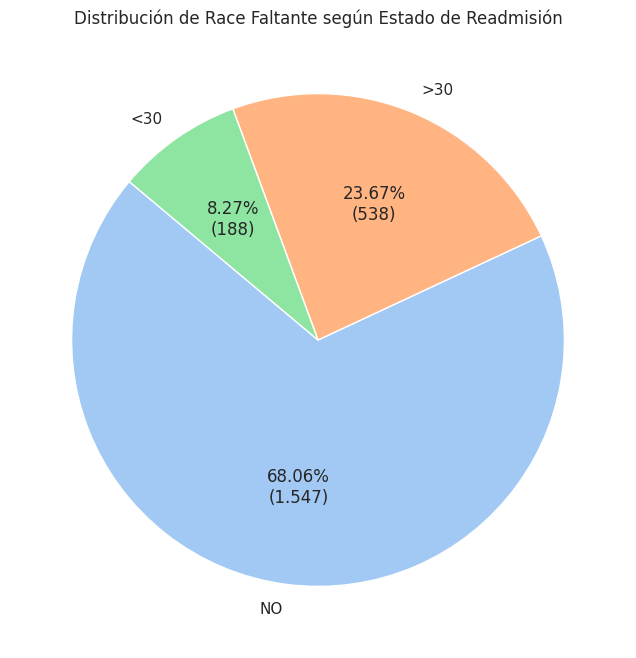

In [ ]:
# Filtrar los registros donde la raza es faltante
race_faltantes = df[df["race"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_race = race_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_race(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_race,
    labels=distribucion_readmitidos_race.index,
    autopct=lambda pct: formatear_etiqueta_race(pct, distribucion_readmitidos_race),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Race Faltante según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE DIAG_1

# Identificar diagnósticos principales ausentes
df["diag1_ausente"] = df["diag_1"].isna()

# Porcentaje de ausencia según readmisión
resultado_diag1 = (
    df.groupby("readmitted")["diag1_ausente"]
      .mean()
      .mul(100)
      .round(4)
)

print("Porcentaje de diag_1 ausente según readmisión:")
print(resultado_diag1)

Porcentaje de diag_1 ausente según readmisión:
readmitted
<30    0.0440
>30    0.0113
NO     0.0219
Name: diag1_ausente, dtype: float64


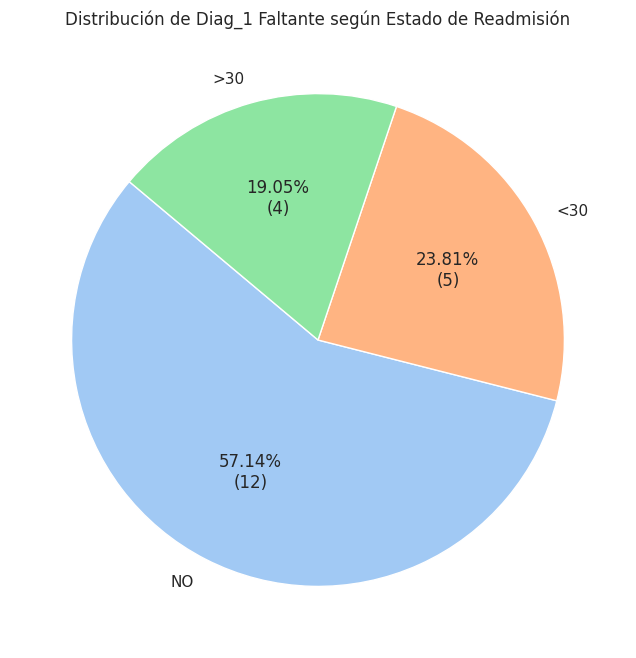

In [ ]:
# Filtrar los registros donde diag_1 es faltante
diag1_faltantes = df[df["diag_1"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_diag1 = diag1_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_diag1(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_diag1,
    labels=distribucion_readmitidos_diag1.index,
    autopct=lambda pct: formatear_etiqueta_diag1(pct, distribucion_readmitidos_diag1),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Diag_1 Faltante según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE DIAG_2

# Identificar diagnósticos principales ausentes
df["diag2_ausente"] = df["diag_2"].isna()

# Porcentaje de ausencia según readmisión
resultado_diag2 = (
    df.groupby("readmitted")["diag2_ausente"]
      .mean()
      .mul(100)
      .round(4)
)

print("Porcentaje de diag_2 ausente según readmisión:")
print(resultado_diag2)

Porcentaje de diag_2 ausente según readmisión:
readmitted
<30    0.2553
>30    0.2082
NO     0.4648
Name: diag2_ausente, dtype: float64


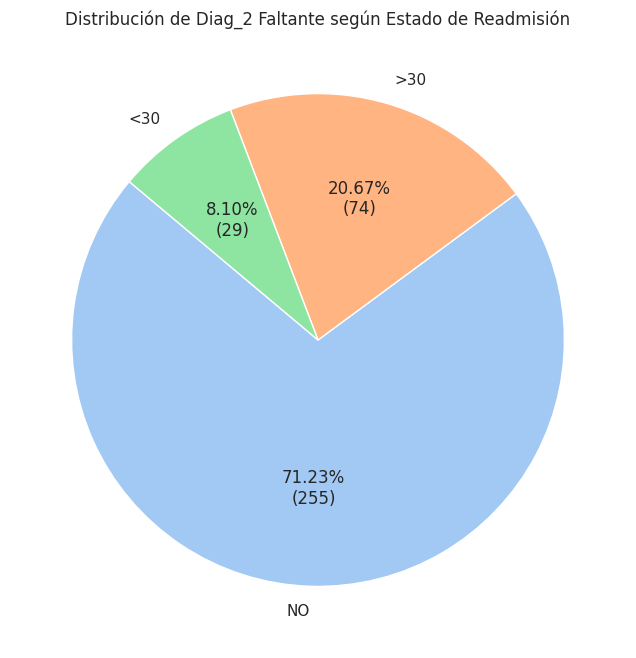

In [ ]:
# Filtrar los registros donde diag_2 es faltante
diag2_faltantes = df[df["diag_2"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_diag2 = diag2_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_diag2(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_diag2,
    labels=distribucion_readmitidos_diag2.index,
    autopct=lambda pct: formatear_etiqueta_diag2(pct, distribucion_readmitidos_diag2),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Diag_2 Faltante según Estado de Readmisión")
plt.show()

In [ ]:
#ANALISIS DE LA VARIABLE DIAG_2

# Identificar diagnósticos principales ausentes
df["diag3_ausente"] = df["diag_3"].isna()

# Porcentaje de ausencia según readmisión
resultado_diag3 = (
    df.groupby("readmitted")["diag3_ausente"]
      .mean()
      .mul(100)
      .round(4)
)

print("Porcentaje de diag_3 ausente según readmisión:")
print(resultado_diag3)

Porcentaje de diag_3 ausente según readmisión:
readmitted
<30    0.8013
>30    0.9509
NO     1.8118
Name: diag3_ausente, dtype: float64


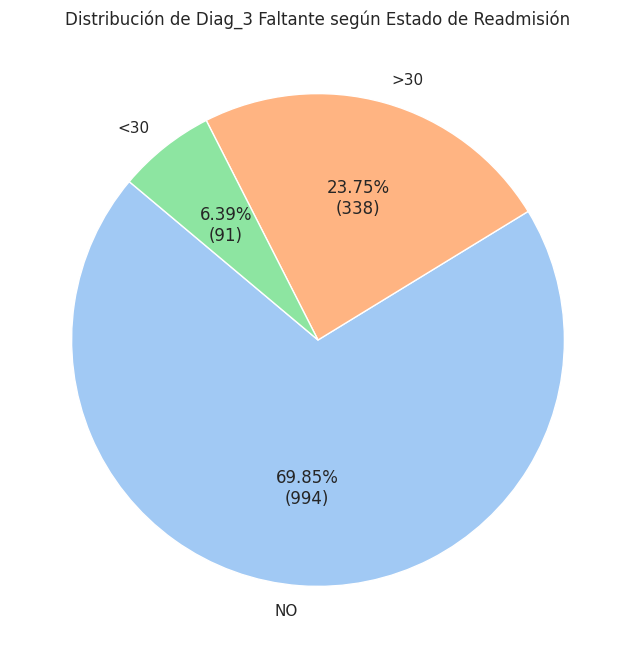

In [ ]:
# Filtrar los registros donde diag_3 es faltante
diag3_faltantes = df[df["diag_3"].isna()]

# Agrupar por la variable de readmisión y contar
distribucion_readmitidos_diag3 = diag3_faltantes["readmitted"].value_counts()

# Función para mostrar la cantidad absoluta y el porcentaje
def formatear_etiqueta_diag3(pct, todos_valores):
    absoluto = int(round(pct * sum(todos_valores) / 100.0))
    return f"{pct:.2f}%\n({absoluto:,})".replace(",", ".")

# Crear el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    distribucion_readmitidos_diag3,
    labels=distribucion_readmitidos_diag3.index,
    autopct=lambda pct: formatear_etiqueta_diag3(pct, distribucion_readmitidos_diag3),
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Distribución de Diag_3 Faltante según Estado de Readmisión")
plt.show()

In [ ]:
# aplicación de las decisiones sobre faltantes

# 0) Se quitan las columnas auxiliares *_ausente creadas arriba para los gráficos; no son variables del problema
df = df.drop(columns=[c for c in df.columns if c.endswith("_ausente")])

# 1) race, medical_specialty y payer_code: el faltante pasa a ser una categoría propia
for col in ["race", "medical_specialty", "payer_code"]:
    df[col] = df[col].fillna("Desconocido")

# 2) diag_2 y diag_3 vacíos = el paciente no tuvo otro diagnóstico
for col in ["diag_2", "diag_3"]:
    df[col] = df[col].fillna("Sin diagnóstico")

# 3) diag_1 vacío: son muy pocas filas y es el diagnóstico principal -> se eliminan
filas_antes = len(df)
df = df.dropna(subset=["diag_1"]).copy()
print(f"Filas eliminadas por diag_1 vacío: {filas_antes - len(df)} ({(filas_antes - len(df)) / filas_antes * 100:.3f} %)")

# 4) weight (96,9 % faltante) se elimina en la sección 1.6, junto con las demás columnas descartadas
registrar("1.1 Faltantes", df, "race, medical_specialty, payer_code -> 'Desconocido'; diag_2/diag_3 -> 'Sin diagnóstico'; se eliminan filas sin diag_1")
print("Faltantes que quedan fuera de weight:", int(df.drop(columns="weight").isna().sum().sum()))

Filas eliminadas por diag_1 vacío: 0 (0.000 %)
Faltantes que quedan fuera de weight: 0


Al encontrarnos con valores faltantes en el conjunto de datos, es crucial preguntarse:
* **¿Cómo afectan estos valores a la integridad y representatividad de la información?**

Los valores faltantes en la variable weight afectan la integridad y representatividad de la información, debido a que aproximadamente el 96,86 % de los registros no contiene un peso registrado. Esto significa que solo el 3,14 % de los pacientes dispone de esta información, lo que limita considerablemente su utilidad para el análisis estadístico.La ausencia de tantos datos reduce la cantidad de información disponible para estudiar la relación entre el peso de los pacientes y la readmisión hospitalaria. Además, completar estos valores mediante imputación podría introducir sesgos o distorsionar los resultados si las estimaciones no representan adecuadamente los pesos reales.

La variable medical_specialty identifica la especialidad médica del profesional que atendió al paciente. Presenta 49.949 valores faltantes, equivalentes al 49,08 % de los registros.La ausencia de aproximadamente la mitad de los registros limita la integridad de la información, ya que dificulta identificar qué especialidades médicas están asociadas con una mayor frecuencia de readmisión hospitalaria.

La variable payer_code identifica el código del pagador o entidad responsable de cubrir los gastos de atención médica. Presenta 40.256 valores faltantes, equivalentes al 39,56 % de los registros. La ausencia de estos datos dificulta analizar la relación entre el tipo de pagador y la readmisión hospitalaria. También limita la posibilidad de identificar diferencias en la readmisión según la cobertura o el mecanismo de financiación de la atención médica.

`race` (2,23 %) y los diagnósticos (`diag_3` 1,40 %, `diag_2` 0,35 %, `diag_1` 0,02 %) tienen pocos faltantes, pero eliminar sus filas podría cambiar la mezcla de pacientes.


* **¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

Se identificaron a través del análisis de faltantes y su porcentaje en el conjunto de datos (`isna()` por columna, después de convertir el signo `?` en faltante al leer el archivo). El texto `None` de `A1Cresult` y `max_glu_serum` **no se tomó como faltante** porque significa "examen no realizado". Este procedimiento permitió determinar la magnitud y distribución de los valores faltantes, proporcionando una base objetiva para decidir cómo tratarlos.

* **¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso que aplique, ¿qué método de relleno se utilizó y por qué se consideró apropiado?**

| Variable | % faltante | Decisión | Justificación |
|---|---|---|---|
| `weight` | 96,86 % | Eliminar la columna (sección 1.6) | Casi no hay datos; rellenarlos sería inventar información para el 97 % de los pacientes. |
| `medical_specialty` | 49,08 % | Conservar con la categoría "Desconocido" | La ausencia no es igual entre grupos (47,3 % en `NO` frente a 50,9 % en `<30`). En la fase 2 mostró más asociación con el reingreso que `payer_code`, `race` y `gender`. Eliminar la columna perdería esa señal y eliminar las filas perdería la mitad de los datos. |
| `payer_code` | 39,56 % | Conservar con "Desconocido" | Mismo criterio; su aporte se evaluará en el modelamiento. |
| `race` | 2,23 % | Conservar con "Desconocido" | Falta más en `NO` (2,82 %) que en `<30` (1,66 %) y `>30` (1,51 %): borrar las filas quitaría más pacientes no readmitidos que readmitidos. |
| `diag_2`, `diag_3` | 0,35 % y 1,40 % | Categoría "Sin diagnóstico" | Un diagnóstico secundario vacío suele significar que el paciente no tuvo otro. Además `diag_3` falta en 1,81 % de los `NO` frente a 0,80 % de los `<30`: borrar esas filas sesgaría la muestra. |
| `diag_1` | 0,02 % (21 filas) | Eliminar las filas | Es el diagnóstico principal; son muy pocas filas y el efecto es despreciable. |

El método fue **rellenar con una categoría explícita**, no con la moda ni con el promedio, porque son variables de texto y porque así el modelo puede aprender si "faltar" tiene relación con el reingreso.

* **¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? Por ejemplo, si hay valores faltantes en una variable crítica, ¿cómo podría afectar la interpretación de los resultados?**

Si, como se observa a nivel de codigo y a nivel visual todas las variables con faltantes se contrastaron con respecto a la variable objetivo que es el estado de readmision, lo que permitio tomar medidas sobre su tratamiento.

**Cómo podría afectar la interpretación**, con ejemplos de este dataset:
- **`race`:** si se borraran sus filas habría proporcionalmente menos pacientes no readmitidos y la tasa de reingreso parecería algo mayor de lo real.
- **`diag_3`:** falta en 1,81 % de los `NO` frente a 0,80 % de los `<30`; borrar esas filas también inclinaría la muestra.
- **`A1Cresult` y `max_glu_serum`:** si `None` se hubiera tomado como faltante (lectura por defecto de pandas), parecería que se perdió el 83 % y el 95 % de los datos, cuando en realidad "no se midió" es información sobre la atención.
- **`medical_specialty` y `payer_code`:** con 49 % y 40 % de ausencia, cualquier conclusión describe solo a quienes tienen el dato; por eso "Desconocido" se interpreta como un grupo más.


### **1.2. Valores duplicados**
----
Ante la presencia de valores duplicados, es esencial reflexionar sobre su impacto en los resultados.

* ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?
* ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?
* ¿Pueden estos duplicados sesgar el análisis, y en qué medida?
* ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?
* ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?

La identificación y eliminación de duplicados busca asegurar que cada registro aporte información única y valiosa.

In [ ]:
#  Verificación general de filas idénticas

df_paso1 = df.copy()

# 1. Filas idénticas en todas las columnas
dup_filas = int(df_paso1.duplicated().sum())
print(f"Filas duplicadas exactas (todas las columnas):  {dup_filas}")

# 2. Verificación específica por identificadores (excluyendo variables clínicas)
duplicados_id = df_paso1.duplicated(subset=['encounter_id','patient_nbr']).sum()
dup_encuentros = int(df_paso1['encounter_id'].duplicated().sum())
print(f"Total de registros duplicados (encounter_id + patient_nbr): {duplicados_id}")
print(f"Hospitalizaciones (encounter_id) repetidas:      {dup_encuentros}")

# 3. Pacientes repetidos: no son duplicados, pero las filas de un mismo paciente no son independientes
por_paciente = df_paso1.groupby("patient_nbr").size()
repetidos = por_paciente[por_paciente > 1]
pct_filas_repetidas = df_paso1["patient_nbr"].map(por_paciente).gt(1).mean() * 100
print(f"Pacientes distintos:                             {formato_miles(len(por_paciente))}")
print(f"Pacientes con más de una hospitalización:        {formato_miles(len(repetidos))}")
print(f"% de las hospitalizaciones de un paciente repetido: {pct_filas_repetidas:.1f} %")
print(f"Máximo de hospitalizaciones de un mismo paciente: {por_paciente.max()}")

df_paso1_2 = df_paso1.copy()
registrar("1.2 Duplicados", df_paso1, "No hay duplicados que eliminar; el paciente repetido se trata en la partición")

Filas duplicadas exactas (todas las columnas):  0
Total de registros duplicados (encounter_id + patient_nbr): 0
Hospitalizaciones (encounter_id) repetidas:      0
Pacientes distintos:                             71.509
Pacientes con más de una hospitalización:        16.767
% de las hospitalizaciones de un paciente repetido: 46.2 %
Máximo de hospitalizaciones de un mismo paciente: 40


# 1.2. Valores duplicados

----

* **¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

Se utilizó el método.duplicated() de la librería Pandas con el objetivo de comprobar si en cada una de las columnas había filas con coincidencias exactas. Después del procedimiento, no se pudo constatar ningún registro duplicado. Por lo tanto, no fue necesario eliminar ninguna información de los conjuntos de datos.

Además de las filas idénticas, se revisaron los pacientes repetidos (patient_nbr). Un mismo paciente puede tener varias hospitalizaciones. Esas filas no son duplicados, porque cada una es un evento real con su propio encounter_id, así que no se eliminaron. El código cuenta cuántos pacientes se repiten y qué porcentaje de las hospitalizaciones representan, porque esto es lo que obliga a dividir los datos por paciente (sección 2.3).

* **¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

Sí. Revisar `encounter_id` junto con `patient_nbr` no aporta, porque `encounter_id` ya es único (cada línea es un evento separado). Lo importante es `patient_nbr`: un mismo paciente puede aparecer en varias hospitalizaciones, y esas filas **no son duplicados** (son eventos reales) pero tampoco son independientes entre sí. El código de arriba cuenta cuántos pacientes y cuántas hospitalizaciones están en esa situación.

* **¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

Los duplicados exactos no existen, así que no inflan los conteos. Los **pacientes repetidos** sí pueden sesgar la *evaluación* del modelo: si algunas hospitalizaciones de un paciente quedan en entrenamiento y otras en prueba, el modelo "reconoce" al paciente y el resultado parece mejor de lo que sería con pacientes nuevos (como poner la misma pregunta en el examen de práctica y en el final). La **magnitud** depende del porcentaje de hospitalizaciones que pertenecen a pacientes repetidos (se imprime en la celda anterior); para medirla se puede comparar el desempeño con una división por filas frente a una por paciente: la primera suele salir más optimista.

* **¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?**

El descarte de duplicados es una etapa imprescindible para asegurar la integridad de los análisis. Sin embargo, una vez se comprobó que en el conjunto de datos original no se repetían filas, la unicidad de los datos se mantuvo desde un principio. Tampoco se eliminan las hospitalizaciones repetidas de un mismo paciente: cada una es un evento real y descartarlas quitaría información. La decisión fue **conservarlas y dividir los datos por paciente** (sección 2.3).

* **¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?**

El resultado final, tras contar los duplicados fue de cero, por lo que no se eliminó ninguna fila. Así, la cantidad y representatividad de la muestra quedó intacta, sin que fuera necesario eliminar ninguna fila de la base de datos.



### **1.3. Valores atípicos**
---
Al abordar valores atípicos, es relevante cuestionarse sobre la naturaleza de estos puntos extremos.
* ¿Son errores de medición o representan información válida pero excepcional?
* ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?
* ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?
* ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?

La elección entre eliminar o transformar estos valores debe basarse en su influencia en la distribución y la interpretación de los resultados, asegurando que el análisis refleje de manera precisa la realidad del conjunto de datos.

In [ ]:
# Identificar las columnas numéricas
columnas_numericas = df_paso1.select_dtypes(
    include="number"
).columns.tolist()

# Excluir identificadores y la variable objetivo
# readmitido_30d (0/1) es la variable objetivo, no una variable numérica para buscar atípicos
identificadores = ["encounter_id", "patient_nbr", "readmitido_30d"]

columnas_numericas = [
    col for col in columnas_numericas
    if col not in identificadores
]

# Resumen estadístico
print("Variables numéricas:", len(columnas_numericas))

display(
    df[columnas_numericas].describe().T.round(2)
)


Variables numéricas: 8


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101745.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101745.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101745.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101745.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101745.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101745.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101745.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101745.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


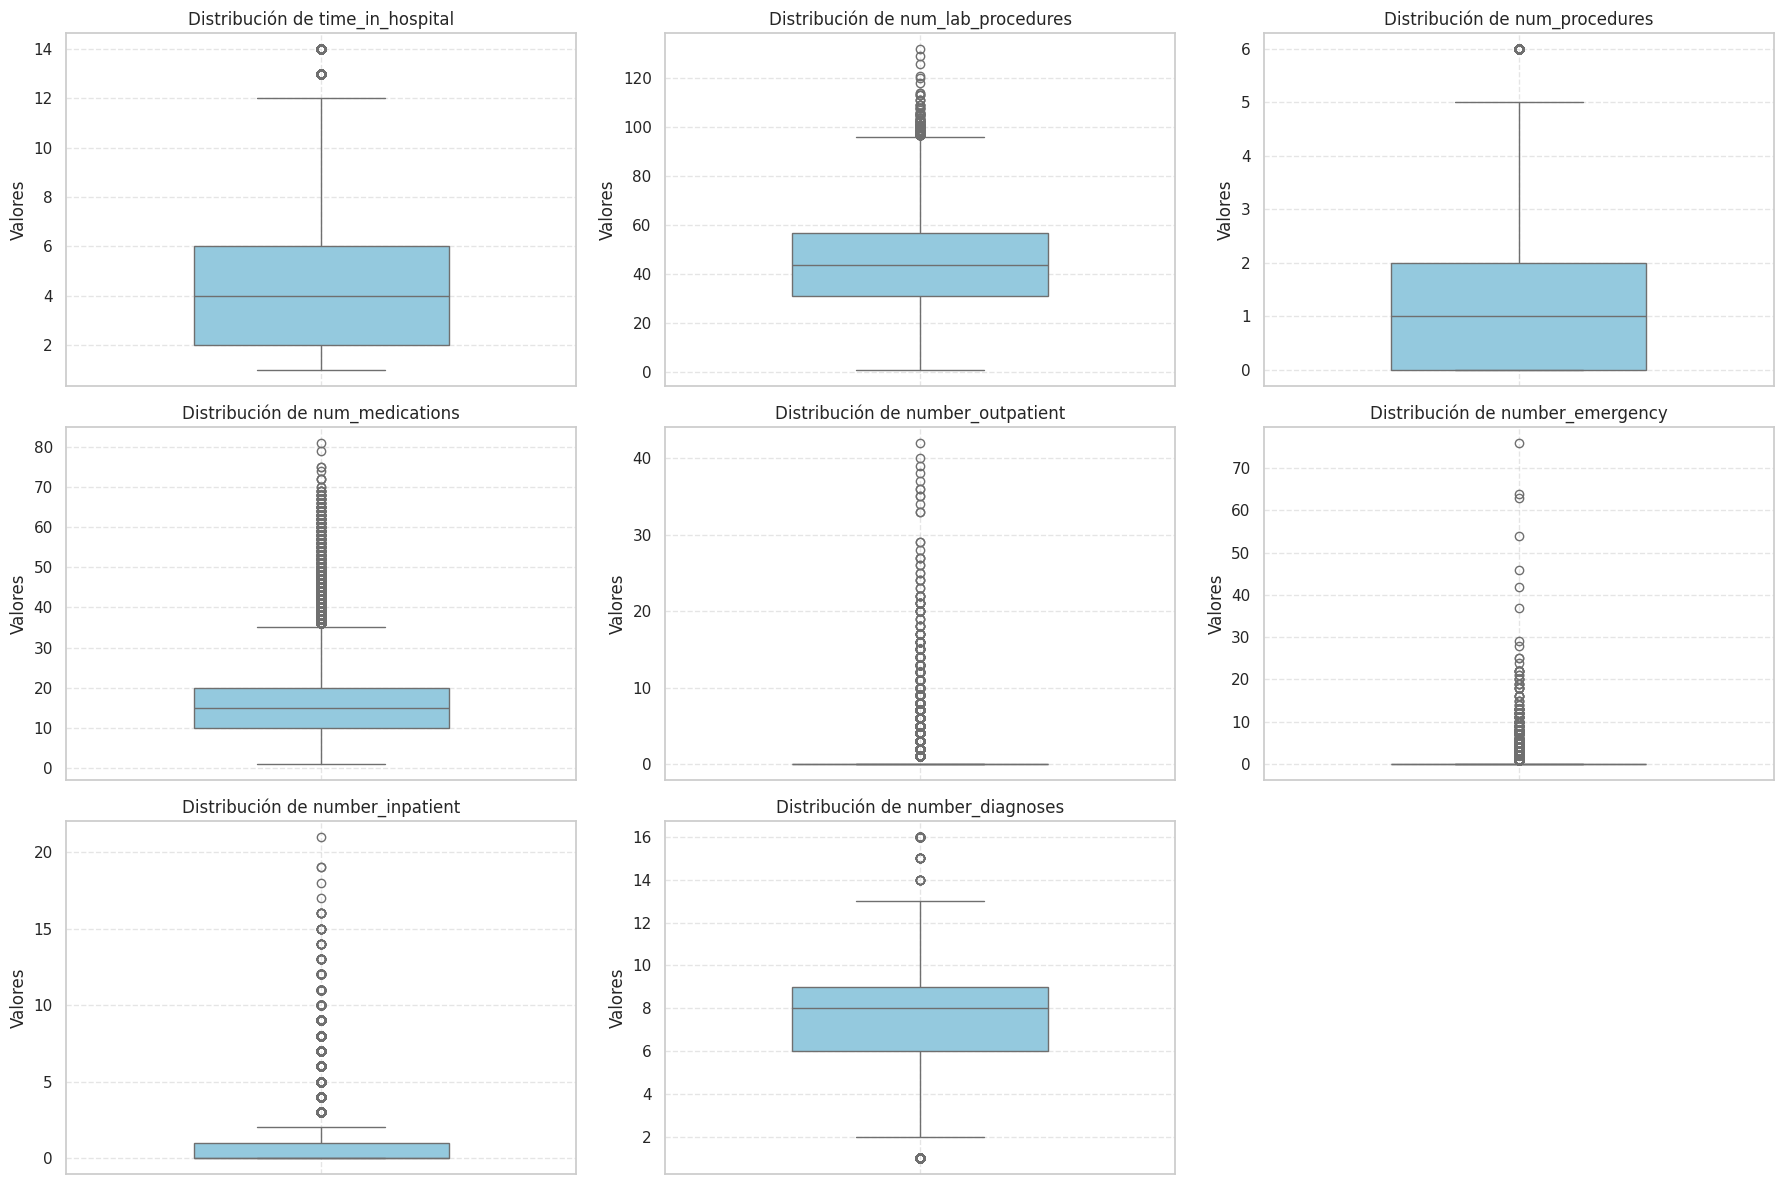

In [ ]:
# Determinar la cantidad de filas y columnas para los subplots de manera dinámica
num_vars = len(columnas_numericas)
cols = 3
rows = math.ceil(num_vars / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 4))
axes = axes.flatten()  # Aplanar la matriz de ejes para facilitar la iteración

# Generar un boxplot para cada variable numérica
for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue", width=0.5)
    axes[i].set_title(f"Distribución de {col}", fontsize=12)
    axes[i].set_ylabel("Valores")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar los subplots vacíos que sobren en la cuadrícula
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
# regla del IQR
def resumen_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera = int(((s < inferior) | (s > superior)).sum())
    return pd.Series({"mínimo": s.min(), "máximo": s.max(), "límite inferior": inferior, "límite superior": superior,
                      "n.º fuera de rango": fuera, "% fuera de rango": round(fuera / len(s) * 100, 1)})

display(df[columnas_numericas].apply(resumen_atipicos).T)
registrar("1.3 Atípicos", df, "No se eliminan; se comprimen con log1p y se escalan en la sección 2")

,mínimo,máximo,límite inferior,límite superior,n.º fuera de rango,% fuera de rango
time_in_hospital,1.0,14.0,-4.0,12.0,2252.0,2.2
num_lab_procedures,1.0,132.0,-8.0,96.0,143.0,0.1
num_procedures,0.0,6.0,-3.0,5.0,4954.0,4.9
num_medications,1.0,81.0,-5.0,35.0,2557.0,2.5
number_outpatient,0.0,42.0,0.0,0.0,16737.0,16.4
number_emergency,0.0,76.0,0.0,0.0,11379.0,11.2
number_inpatient,0.0,21.0,-1.5,2.5,7046.0,6.9
number_diagnoses,1.0,16.0,1.5,13.5,281.0,0.3


/tmp/ipykernel_804/1753920741.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_804/1753920741.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_804/1753920741.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_804/1753920741.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_804/1753920741.py:21: FutureWarning: 

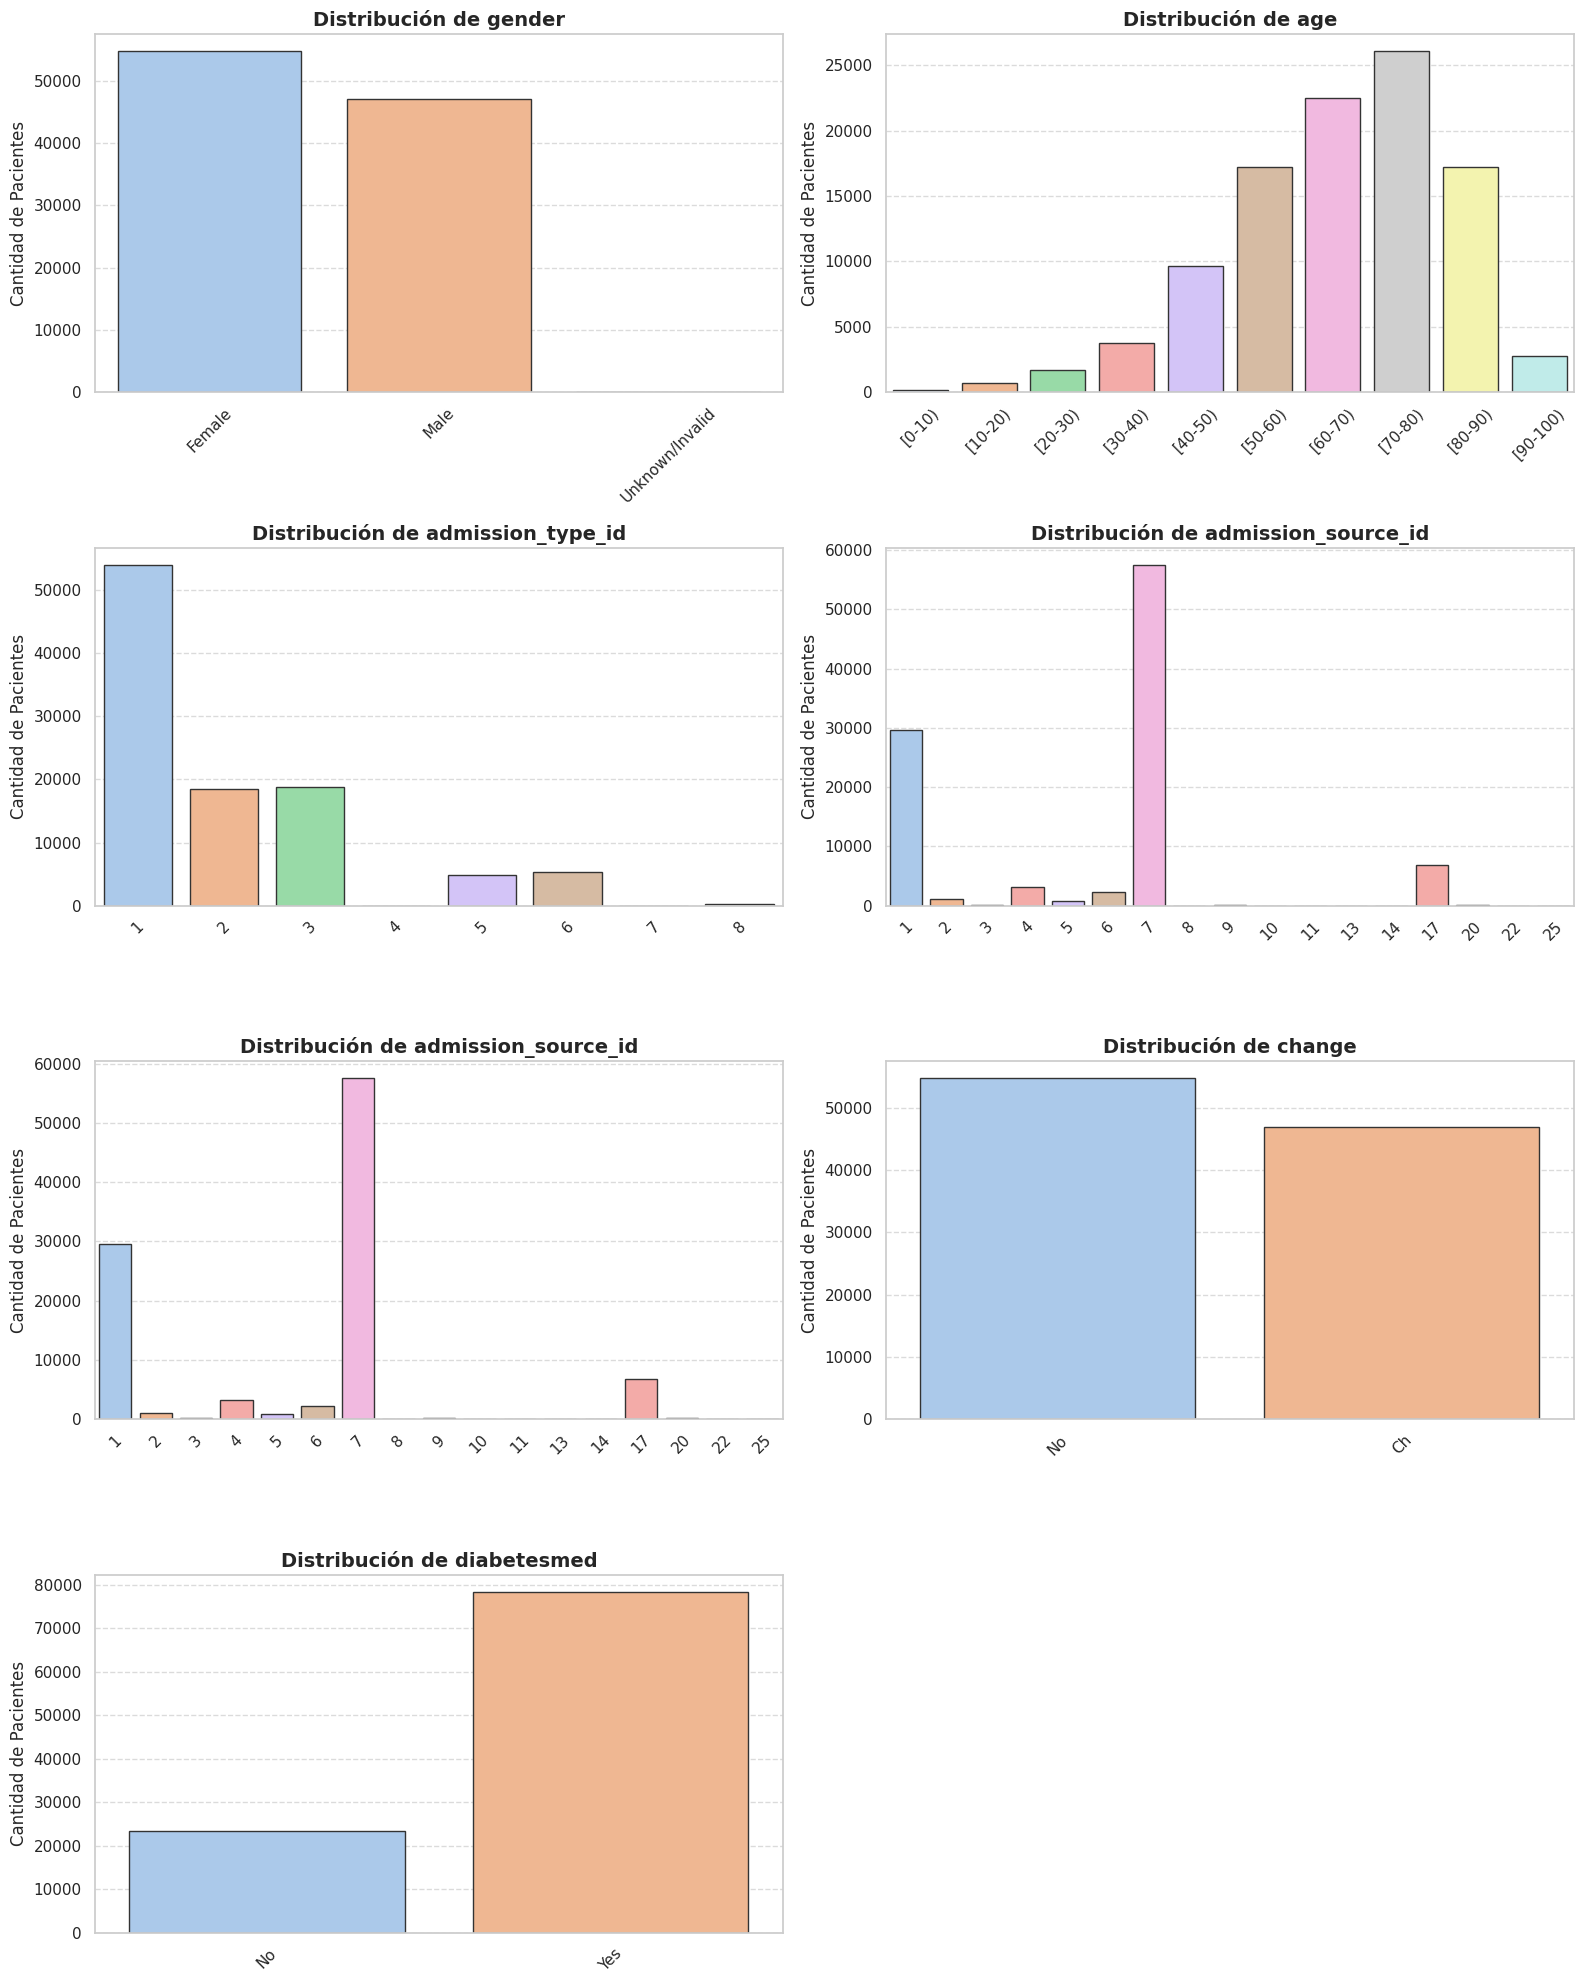

In [ ]:
# Seleccionar variables categóricas relevantes para el análisis visual
# Excluimos las que tienen demasiadas categorías únicas (como ID, diagnósticos o especialidades)
categoricas_visualizar = [
    "gender",
    "age",
    "admission_type_id",
    "admission_source_id",
    "admission_source_id",
    "change",
    "diabetesmed"
]

# Configurar la cuadrícula de gráficos
cols_cat = 2
rows_cat = math.ceil(len(categoricas_visualizar) / cols_cat)
fig_cat, axes_cat = plt.subplots(rows_cat, cols_cat, figsize=(16, rows_cat * 5))
axes_cat = axes_cat.flatten()

for i, col in enumerate(categoricas_visualizar):
    # Graficar las frecuencias utilizando un countplot
    sns.countplot(
        data=df,
        x=col,
        ax=axes_cat[i],
        palette="pastel",
        edgecolor="0.2"
    )
    axes_cat[i].set_title(f"Distribución de {col}", fontsize=14, fontweight="bold")
    axes_cat[i].set_xlabel("")
    axes_cat[i].set_ylabel("Cantidad de Pacientes")
    axes_cat[i].tick_params(axis='x', rotation=45)
    axes_cat[i].grid(axis="y", linestyle="--", alpha=0.7)

# Ocultar ejes vacíos si los hay
for j in range(i + 1, len(axes_cat)):
    fig_cat.delaxes(axes_cat[j])

plt.tight_layout()
plt.show()

* **¿Son errores de medición o representan información válida pero excepcional?**
Los valores atípicos que aparecen en este conjunto de datos se concentran sobre todo en las variables numéricas sobre la actividad en el hospital, como time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient y number_diagnoses. Si miramos el contexto clínico, llegamos a la conclusión de que no son outliers, sino situaciones reales que simplemente son extraordinarias: pacientes que se quedan ingresados muchos días , gente a la que le han dado una cantidad muy alta de medicamentos o personas con muchas visitas previas. Estos datos reflejan la variabilida sobre los datos clíninos  y nos dicen mucho sobre aquellos casos que se pueden agravar, así que hay que tratarlos como información válida y especial, no como errores.
* **¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?**
Se empleó el procedimiento del Rango Intercuartílico (IQR), el cual clasifica como valores atípicos a toda observación que se encuentre fuera del intervalo [Q1 - 1.5 IQR, Q3 + 1.5 IQR], considerando para ello el primer y tercer cuartil de cada variable. Asimismo, se generaron diagramas de caja para la totalidad de las variables numéricas, herramienta que resultó fundamental para constatar visualmente tanto la presencia como la magnitud de dichos valores extremos. En última instancia, esta metodología permite detectar los datos anómalos con un criterio más objetivo y replicable.
* **¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?**
Se aplicaron ambos métodos. El médtodo estadístico del IQR identificó los rangos extremos de todas las variables númericas dentro del conjunto de datos, mientras que los diagramas de cajas y el uso de la función describe, permitieron visualizar la dispercióm y detectar patrones que se pudieran haber pasado por alto.
* **¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?**
Mantuvimos los valores atípicos tal como están: añaden información valiosa porque a menudo muestran a pacientes complejos desde un punto de vista clínico (frecuentes reingresos, uso excesivo de medicamentos o largas estancias). Excluirlos tendría un impacto negativo en nuestro análisis. Los algoritmos basados en árboles (Random Forest, Gradient Boosting, XGBoost) no se ven afectados de forma significativa por valores atípicos. Para los modelos sensibles a la escala (como la regresión logística), en lugar de borrarlos se aplica en la sección 2 la transformación `log1p` a las tres variables de visitas previas (`number_outpatient`, `number_emergency`, `number_inpatient`), que **comprime los valores grandes sin eliminarlos** (0 queda en 0; 10 pasa a 2,4; 76 pasa a 4,3), y luego se estandarizan todas las numéricas.


### **1.4. Datos Inconsistentes**
---
Frente a inconsistencias en los datos, es importante analizar cómo estas discrepancias podrían afectar la comparabilidad y comprensión de la información.

* ¿Cómo se identificaron las inconsistencias en los datos?
* ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?
* ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?
* ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?
* ¿Se establecieron reglas de validación específicas para garantizar la consistencia?

In [ ]:
# Frecuencia y porcentaje de cada categoría de género
df_paso_2 = df_paso1.copy()

frecuencia_gender = df_paso_2["gender"].value_counts(dropna=False)

porcentaje_gender = (
    df_paso_2["gender"].value_counts(dropna=False, normalize=True) * 100
)

resumen_gender = pd.DataFrame({
    "Cantidad": frecuencia_gender,
    "Porcentaje": porcentaje_gender.round(4)
})

print(resumen_gender)


                 Cantidad  Porcentaje
gender                               
Female              54703     53.7648
Male                47039     46.2322
Unknown/Invalid         3      0.0029


In [ ]:
# un solo tratamiento para 'gender' y limpieza de espacios en todas las columnas de texto

# Manejar 'Unknown/Invalid' en la columna 'gender'
print("\nValores únicos en 'gender' antes:", df_paso_2['gender'].unique())
filas_antes = len(df_paso_2)
df_paso3 = df_paso_2[df_paso_2['gender'] != 'Unknown/Invalid'].copy()
filas_despues = len(df_paso3)
print(f"Se eliminaron {filas_antes - filas_despues} filas con género 'Unknown/Invalid'.")
print("Valores únicos en 'gender' después:", df_paso3['gender'].unique())

#  Convertir variables categóricas codificadas numéricamente al tipo category
variables_categoricas = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df_paso3[variables_categoricas] = df_paso3[variables_categoricas].astype('category')

# Quitar espacios sobrantes en TODAS las columnas de texto (antes solo se hacía en gender)
for col in df_paso3.select_dtypes(exclude=["number", "category"]).columns:
    df_paso3[col] = df_paso3[col].str.strip()

# convertir el género en mayúscula
df_paso3['gender'] = df_paso3['gender'].str.upper()

print("\nTipos de datos de variables categóricas codificadas:")
print(df_paso3[variables_categoricas].dtypes)
registrar("1.4 Inconsistencias (gender)", df_paso3, "Se eliminan las filas con gender = 'Unknown/Invalid'; se quitan espacios en el texto")


Valores únicos en 'gender' antes: ['Female' 'Male' 'Unknown/Invalid']
Se eliminaron 3 filas con género 'Unknown/Invalid'.
Valores únicos en 'gender' después: ['Female' 'Male']

Tipos de datos de variables categóricas codificadas:
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
dtype: object


In [ ]:
# regla de validación explícita
dominios = {
    "gender": {"Female", "Male"},
    "age": {f"[{a}-{a + 10})" for a in range(0, 100, 10)},
    "race": {"Caucasian", "AfricanAmerican", "Hispanic", "Asian", "Other", "Desconocido"},
    "change": {"Ch", "No"},
    "diabetesmed": {"Yes", "No"},
    "max_glu_serum": {"None", "Norm", ">200", ">300"},
    "a1cresult": {"None", "Norm", ">7", ">8"},
    "readmitted": {"<30", ">30", "NO"},
}
dominios.update({med: {"No", "Steady", "Up", "Down"} for med in medicamentos})

# La comparación no distingue mayúsculas (gender ya está en mayúscula)
inesperados = {}
for col, permitidos in dominios.items():
    presentes = set(df_paso3[col].dropna().astype(str).str.upper().unique())
    sobran = presentes - {v.upper() for v in permitidos}
    if sobran:
        inesperados[col] = sorted(sobran)
if inesperados:
    print("[AVISO] Valores fuera del dominio permitido:", inesperados)
else:
    print(f"[OK] Las {len(dominios)} variables revisadas solo contienen valores permitidos.")

# Columnas sin variación: no aportan información
constantes = [c for c in df_paso3.columns if df_paso3[c].nunique(dropna=False) == 1]
print("Columnas con un único valor:", constantes)

# Medicamentos casi sin uso (99 % o más de las hospitalizaciones con 'No')
pct_no = (df_paso3[medicamentos] == "No").mean() * 100
casi_constantes = pct_no[pct_no >= 99].sort_values(ascending=False)
print(f"Medicamentos con 99 % o más de 'No': {len(casi_constantes)} de {len(medicamentos)}")
display(casi_constantes.round(2).to_frame("% 'No'"))

[OK] Las 31 variables revisadas solo contienen valores permitidos.
Columnas con un único valor: ['examide', 'citoglipton']
Medicamentos con 99 % o más de 'No': 15 de 23


,% 'No'
examide,100.00
citoglipton,100.00
acetohexamide,100.00
glimepiride-pioglitazone,100.00
metformin-pioglitazone,100.00
metformin-rosiglitazone,100.00
troglitazone,100.00
glipizide-metformin,99.99
tolbutamide,99.98
miglitol,99.96


* **¿Cómo se identificaron las inconsistencias en los datos?**

Se realizó una inspección de las variables categóricas utilizando `.unique()` y `.value_counts()` para detectar valores que no siguieran el formato esperado o que estuvieran fuera del dominio de la variable. Se identificaron los siguientes casos:

1. **Valores inválidos en `gender`:** además de 'Male' y 'Female', aparece la categoría 'Unknown/Invalid', que no aporta información útil para el análisis y debe tratarse.
2. **Inconsistencias en `max_glu_serum` y `a1cresult`:** presentan el valor 'None', que aunque no es faltante, debe interpretarse como "examen no realizado". Se mantiene porque es información clínica significativa, pero se documenta para futuras decisiones.
3. **Columnas de medicamentos:** se verificó que todas contuvieran únicamente las categorías esperadas ('No', 'Up', 'Down', 'Steady'), sin valores corruptos ni formatos inconsistentes. Algunas tienen más del 99 % de 'No' y casi no aportan información.

* **¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?**

La inconsitencia en la columna  `gender`, el valor 'Unknown/Invalid' no aporta información analítica y podría confundir a un modelo predictivo. Por lo que, se debe intervenir en esta inconsistencia.


* **¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?**

En la columna `gender`, los registros con 'Unknown/Invalid' se eliminaron (son una fracción mínima del total) porque no representan información clínica útil y no se puede inferir el valor correcto.

Las variables numéricas ya están en unidades coherentes (días y conteos), por lo que no necesitan conversión. La edad llega como rango de texto (por ejemplo, [70-80)) y se convierte en un número, el punto medio del rango (75), en la sección 2.1. Los códigos de admisión y de alta (admission_type_id, discharge_disposition_id, admission_source_id) son números que funcionan como etiquetas, no como cantidades. Por eso se convierten al tipo category y luego se codifican en columnas de 0 y 1, para que el modelo no crea que el código 6 vale “más” que el 1.

* **¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?**

Se implementó un proceso en dos fases: (a) la estandarización mediante `.str.strip()` aplicada a **todas** las columnas de texto y `.str.upper()` en `gender`, y (b) la depuración dirigida de los valores inválidos: un **único** tratamiento para `gender` (eliminar las 3 filas con 'Unknown/Invalid'; la opción de reemplazar por la moda se descartó porque asignaría un sexo inventado). Adicionalmente, se convirtieron las variables categóricas codificadas numéricamente (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) al tipo `category` de Pandas.

* **¿Se establecieron reglas de validación específicas para garantizar la consistencia?**

Sí. Se definió un diccionario con los valores permitidos de cada variable (sexo, edad en rangos, raza, resultados de exámenes y los medicamentos) y una celda de código que compara cada columna contra su dominio e imprime `[OK]` o `[AVISO]`. Esta verificación actúa como una regla de validación explícita que confirma la consistencia final del conjunto de datos.




### **1.5. Datos corruptos**
---
En la detección de datos corruptos, pregunte si hay posibles errores de entrada o problemas de transferencia que podrían haber afectado la integridad de los datos.
* ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?

* ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?
* ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?

In [ ]:
# Se revisan los diagnósticos presentes y se agregan los rangos lógicos.

# 1. Filtrar todas las columnas de texto buscando el símbolo '?'
df_paso4 = df_paso3.copy()
cols_texto = df_paso4.select_dtypes(exclude=["number", "category"]).columns
filtro_texto = df_paso4[cols_texto].apply(lambda x: x.str.contains(r'\?', na=False)).any(axis=1)

# 2. Filtrar diagnósticos presentes que no tengan formato CIE-9: número (250.83), código V (V57) o código E (E909)
patron_cie9 = r"^(?:V\d+(?:\.\d+)?|E\d+(?:\.\d+)?|\d+(?:\.\d+)?)$"
filtro_diag = pd.Series(False, index=df_paso4.index)
for col in ["diag_1", "diag_2", "diag_3"]:
    presente = df_paso4[col].notna() & (df_paso4[col] != "Sin diagnóstico")
    filtro_diag |= presente & ~df_paso4[col].astype(str).str.match(patron_cie9)

# 3. Rangos lógicos de las variables numéricas
filtro_rango = (
    ~df_paso4["time_in_hospital"].between(1, 14)
    | (df_paso4[["num_lab_procedures", "num_procedures", "num_medications",
                 "number_outpatient", "number_emergency", "number_inpatient"]] < 0).any(axis=1)
    | (df_paso4["number_diagnoses"] < 1)
)

# 4. Unir los filtros y mostrar los registros corruptos
df_filtrado = df_paso4[filtro_texto | filtro_diag | filtro_rango]

print(f"Total de registros corruptos detectados: {len(df_filtrado)}")
df_filtrado.head()

Total de registros corruptos detectados: 0


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,readmitted,readmitido_30d


* **¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?**

Se revisó que las columnas dentro del conjunto de datos no tuvieran el símbolo ? y que en las columnas de diagnóstico los códigos estuvieran parametrizados tal y como es el CIE-9 (número, código V o código E), revisando solo los diagnósticos presentes. También se verificó que la estancia y los conteos respeten rangos lógicos.

* **¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?**

Si alguna revisión encuentra registros corruptos se eliminan. Actualmente, no se detectan registros corruptos, así que no se elimina ninguna fila en este paso. Los diagnósticos faltantes ya se trataron en la sección 1.1.

* **¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?**

No. Si en el futuro aparecieran códigos mal formados en `diag_1` se eliminarían esas filas por ser el diagnóstico principal; si aparecieran en `diag_2` o `diag_3` se pasarían a "Sin diagnóstico".

In [ ]:
# se agrega el registro en la bitácora
# Confirmar que se eliminan los registros corruptos del dataset
df_paso5 = df_paso4.drop(index=df_filtrado.index)

print(f"Filas antes: {len(df_paso4)}  ->  después de eliminar corruptos: {len(df_paso5)}")
registrar("1.5 Datos corruptos", df_paso5, "Sin filas eliminadas: se revisó formato CIE-9, rangos y símbolos '?'")

Filas antes: 101742  ->  después de eliminar corruptos: 101742


### **1.6. Selección de datos**
---
En la selección de datos, reflexione sobre las variables que son realmente relevantes para sus objetivos de análisis.
* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?


* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
Se evaluó la relevancia de cada una de las variables, teniendo en cuenta su relevancia clínica y estadística. Se excluyeron las variables de tipo id
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
No, no se aplicó ninguna técnica de muestreo para no perder información valiosa de las clases minoraitaruas. El filtrado se centró especialmente el la eliminación de columnas donde se tenían registros únicos y variables con más de 30% de valores faltantes

* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?
Estas variables son identificadores dentro del conjuento de datos, por lo que no poseen una caracterisitca como lo las demás variables tratadas. Dejar estas variables generaría un sobreajuste al modelo, ya que aprendería los IDS de los pacientes, y no patrones clínicos como lo que se busca encontrar dentro de este dataset

In [ ]:
# filas -> los pacientes que fallecieron o pasaron a cuidados paliativos no pueden ser readmitidos
# Códigos de discharge_disposition_id según el archivo IDs_mapping.csv del dataset
CODIGOS_SIN_REINGRESO = {11: "Expired", 13: "Hospice / home", 14: "Hospice / medical facility",
                         19: "Expired at home (hospice)", 20: "Expired in a medical facility (hospice)",
                         21: "Expired, place unknown (hospice)"}
sin_reingreso = df_paso5["discharge_disposition_id"].astype(int).isin(list(CODIGOS_SIN_REINGRESO))

resumen = (df_paso5[sin_reingreso]
           .assign(codigo=lambda d: d["discharge_disposition_id"].astype(int))
           .groupby("codigo")["readmitido_30d"].agg(["size", "mean"])
           .rename(columns={"size": "hospitalizaciones", "mean": "% readmitidos <30 días"}))
resumen["% readmitidos <30 días"] = (resumen["% readmitidos <30 días"] * 100).round(2)
resumen.insert(0, "significado", [CODIGOS_SIN_REINGRESO[c] for c in resumen.index])
display(resumen)
print(f"% readmitidos <30 días entre los demás pacientes: {df_paso5.loc[~sin_reingreso, 'readmitido_30d'].mean() * 100:.2f} %")

df_paso6 = df_paso5.loc[~sin_reingreso].copy()
registrar("1.6 Selección de filas", df_paso6, "Se excluyen fallecidos y pacientes en cuidados paliativos")
print(f"Filas eliminadas: {int(sin_reingreso.sum())}")

,significado,hospitalizaciones,% readmitidos <30 días
codigo,,,
11,Expired,1642,0.00
13,Hospice / home,398,4.77
14,Hospice / medical facility,372,6.45
19,Expired at home (hospice),8,0.00
20,Expired in a medical facility (hospice),2,0.00


% readmitidos <30 días entre los demás pacientes: 11.39 %
Filas eliminadas: 2422


In [ ]:
# patient_nbr se guarda aparte ANTES de eliminarlo (sirve para dividir por paciente en la sección 2.3)
# y medical_specialty / payer_code ya no se eliminan (se conservan como "Desconocido", ver 1.1)

# Eliminación de variables identificadoras y sin variación
grupos = df_paso6['patient_nbr'].copy()
constantes = [c for c in df_paso6.columns if df_paso6[c].nunique(dropna=False) == 1]
columns_drop = ['encounter_id', 'patient_nbr', 'weight'] + constantes
df_paso6 = df_paso6.drop(columns=columns_drop)
medicamentos = [m for m in medicamentos if m in df_paso6.columns]

print("Columnas eliminadas:", columns_drop)
registrar("1.6 Selección de columnas", df_paso6, f"Se eliminan {len(columns_drop)} columnas (identificadores, weight, sin variación)")

Columnas eliminadas: ['encounter_id', 'patient_nbr', 'weight', 'examide', 'citoglipton']


## **2. Preprocesamiento y transformación de los datos**
---

**En palabras simples:** los modelos de machine learning trabajan con números. Por eso hay que convertir el texto (por ejemplo, el rango de edad o la raza) en números y poner las variables en escalas comparables. Se hace en dos etapas:

1. **Transformaciones fijas** (2.1): se pueden aplicar a todos los datos porque no dependen de los demás pacientes. Por ejemplo, convertir `[70-80)` en 75.
2. **Transformaciones que aprenden de los datos** (2.2 y 2.3): por ejemplo, el promedio y la dispersión que se usan para escalar. Se calculan **solo con el grupo de entrenamiento** y luego se aplican igual al de prueba. Si se calcularan con todos los datos, el grupo de prueba "se filtraría" en el entrenamiento (fuga de datos).

### 2.1 Variables nuevas y simplificación

In [ ]:
# transformaciones fijas
df_modelo = df_paso6.copy()

# 1) Edad: el rango de texto "[70-80)" se convierte en el punto medio del rango (75)
extremos = df_modelo["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int)
df_modelo["age_medio"] = extremos.mean(axis=1)

# 2) Diagnósticos: cientos de códigos CIE-9 se agrupan en categorías clínicas generales
def agrupar_cie9(codigo):
    """Agrupa un código CIE-9 en una categoría clínica general."""
    if codigo == "Sin diagnóstico":
        return codigo
    if codigo.startswith(("V", "E")):
        return "Otros (códigos V/E)"
    try:
        n = float(codigo)
    except ValueError:
        return "Otros"
    if int(n) == 250:                      return "Diabetes"
    if 390 <= n < 460 or int(n) == 785:    return "Circulatorio"
    if 460 <= n < 520 or int(n) == 786:    return "Respiratorio"
    if 520 <= n < 580 or int(n) == 787:    return "Digestivo"
    if 580 <= n < 630 or int(n) == 788:    return "Genitourinario"
    if 710 <= n < 740:                     return "Musculoesquelético"
    if 800 <= n < 1000:                    return "Lesiones"
    if 140 <= n < 240:                     return "Neoplasias"
    return "Otros"

for col in ["diag_1", "diag_2", "diag_3"]:
    equivalencia = {cod: agrupar_cie9(cod) for cod in df_modelo[col].unique()}      # cada código distinto se agrupa una sola vez
    df_modelo[col + "_grupo"] = df_modelo[col].map(equivalencia)

# 3) Medicamentos: la información de todos se resume en dos números
df_modelo["n_med_activos"] = (df_modelo[medicamentos] != "No").sum(axis=1)                 # cuántos medicamentos se usaron
df_modelo["n_med_cambiados"] = df_modelo[medicamentos].isin(["Up", "Down"]).sum(axis=1)    # a cuántos se les subió o bajó la dosis

# ... y después se descartan los medicamentos casi sin uso (la información de todos ya quedó resumida arriba)
descartar_meds = [m for m in casi_constantes.index if m in df_modelo.columns]
df_modelo = df_modelo.drop(columns=["age", "diag_1", "diag_2", "diag_3"] + descartar_meds)
medicamentos = [m for m in medicamentos if m in df_modelo.columns]

# 4) Códigos de admisión y alta: son categorías, no cantidades
codigos = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
df_modelo[codigos] = df_modelo[codigos].astype(str)

registrar("2.1 Variables nuevas", df_modelo, f"age_medio, 3 grupos de diagnóstico, 2 resúmenes de medicamentos; se descartan {len(descartar_meds)} medicamentos casi sin uso")
print(f"Medicamentos que se conservan ({len(medicamentos)}): {medicamentos}")
display(df_modelo["diag_1_grupo"].value_counts().to_frame("hospitalizaciones"))

Medicamentos que se conservan (8): ['metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin']


,hospitalizaciones
diag_1_grupo,
Circulatorio,29680
Otros,16160
Respiratorio,13934
Digestivo,9333
Diabetes,8661
Lesiones,6851
Genitourinario,5002
Musculoesquelético,4935
Neoplasias,3131


### 2.2 Qué hace cada transformación y por qué

| Transformación | Variables | Para qué sirve | Ejemplo de salud |
|---|---|---|---|
| **Codificación *one-hot*** | Raza, especialidad, pagador, códigos de admisión y alta, exámenes, grupos de diagnóstico, medicamentos | Convierte cada categoría en una columna de 0 y 1. Evita que el modelo piense que unas categorías valen más que otras. | "Cardiología" pasa a ser una columna que vale 1 si el médico fue cardiólogo y 0 si no. |
| **Categorías poco frecuentes agrupadas** (`min_frequency = 1 %`) | Todas las categóricas | Las categorías con menos del 1 % de los casos se agrupan en una sola. Con muy pocos casos el modelo no puede aprender nada confiable. | Especialidades que atendieron a muy pocos pacientes quedan juntas en "poco frecuentes". |
| **Binarias a 0/1** | Sexo, cambio de medicación, uso de medicamento para diabetes | Solo tienen dos valores; una sola columna basta. | Sexo: 1 = hombre, 0 = mujer. |
| **Logaritmo (`log1p`)** | Visitas previas (consulta externa, urgencias, hospitalizaciones) | Comprime los valores muy grandes sin eliminarlos. | La diferencia entre 0 y 2 visitas importa más que entre 40 y 42. |
| **Estandarización** | Todas las numéricas | Pone las variables en una escala comparable (promedio 0). Sin esto, los días de estancia (1 a 14) y los exámenes de laboratorio (1 a 132) pesarían distinto solo por su tamaño. | Comparar una temperatura en °C con una presión en mmHg sin estandarizar. |

Todo esto se agrupa en un **pipeline** con la finalidad de aprender con el grupo de entrenamiento y se aplica de la misma manera al de prueba.

In [ ]:
objetivo = "readmitido_30d"
conteos_previos = ["number_outpatient", "number_emergency", "number_inpatient"]        # muy asimétricas -> log1p
numericas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
             "number_diagnoses", "age_medio", "n_med_activos", "n_med_cambiados"]
binarias = ["gender", "change", "diabetesmed"]
nominales = [c for c in df_modelo.columns
             if c not in numericas + conteos_previos + binarias + [objetivo, "readmitted"]]

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), numericas),
        ("conteos", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("escala", StandardScaler())]), conteos_previos),
        ("binarias", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), binarias),
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                                    sparse_output=False), nominales),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

print(f"Numéricas: {len(numericas)} | Visitas previas (log): {len(conteos_previos)} | "
      f"Binarias: {len(binarias)} | Categóricas: {len(nominales)}")
print("Categóricas:", nominales)

Numéricas: 8 | Visitas previas (log): 3 | Binarias: 3 | Categóricas: 19
Categóricas: ['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'max_glu_serum', 'a1cresult', 'metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'diag_1_grupo', 'diag_2_grupo', 'diag_3_grupo']


### 2.3 División entrenamiento / prueba por paciente

Se separa una parte de los pacientes (20 %) que el modelo no verá durante el entrenamiento. Sirve para saber si el modelo funciona con pacientes nuevos. Dos temas a tener en cuenta:

- **Por paciente:** todas las hospitalizaciones de una misma persona quedan en el mismo grupo.
- **Estratificada:** los dos grupos conservan la misma proporción de readmitidos (cerca del 11 %).

Después, el pipeline se **aprende solo con el grupo de entrenamiento** y se aplica a ambos.

In [ ]:
# usa los datos limpios, el objetivo binario y divide por paciente.

# Separación de variables predictoras (X) y variable objetivo (y)
X = df_modelo.drop(columns=[objetivo, 'readmitted'])      # 'readmitted' sale: de ahí viene el objetivo
y = df_modelo[objetivo]
grupos = grupos.loc[X.index]                              # paciente de cada fila

# Realización de la partición: una de 5 particiones (20 %), por paciente y estratificada por el objetivo
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_entrenamiento, idx_prueba = next(divisor.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_entrenamiento], X.iloc[idx_prueba]
y_train, y_test = y.iloc[idx_entrenamiento], y.iloc[idx_prueba]

# El pipeline aprende SOLO con entrenamiento y se aplica a entrenamiento y prueba
preprocesamiento.fit(X_train)
X_train_p = preprocesamiento.transform(X_train)
X_test_p = preprocesamiento.transform(X_test)

# --- Verificaciones ---
pacientes_comunes = set(grupos.iloc[idx_entrenamiento]) & set(grupos.iloc[idx_prueba])
print(f"[{'OK' if not pacientes_comunes else 'AVISO'}] Pacientes presentes en entrenamiento y prueba a la vez: {len(pacientes_comunes)}")
print(f"[{'OK' if X_train_p.isna().sum().sum() == 0 and X_test_p.isna().sum().sum() == 0 else 'AVISO'}] Valores faltantes tras el preprocesamiento: "
      f"{int(X_train_p.isna().sum().sum() + X_test_p.isna().sum().sum())}")
print(f"[{'OK' if 'readmitted' not in X_train_p.columns and objetivo not in X_train_p.columns else 'AVISO'}] El objetivo no está entre las variables predictoras")

resumen_particion = pd.DataFrame({
    "hospitalizaciones": [len(y_train), len(y_test)],
    "% del total": [round(len(y_train) / len(y) * 100, 1), round(len(y_test) / len(y) * 100, 1)],
    "% readmitidos <30 días": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    "pacientes distintos": [grupos.iloc[idx_entrenamiento].nunique(), grupos.iloc[idx_prueba].nunique()],
    "columnas tras el preprocesamiento": [X_train_p.shape[1], X_test_p.shape[1]],
}, index=["Entrenamiento", "Prueba"])
display(resumen_particion)

[OK] Pacientes presentes en entrenamiento y prueba a la vez: 0
[OK] Valores faltantes tras el preprocesamiento: 0
[OK] El objetivo no está entre las variables predictoras


,hospitalizaciones,% del total,% readmitidos <30 días,pacientes distintos,columnas tras el preprocesamiento
Entrenamiento,79641,80.2,11.45,56033,129
Prueba,19679,19.8,11.15,13946,129


**Sobre el desbalance de clases:** no se aplicó remuestreo (como SMOTE) en esta etapa. Esas técnicas deben hacerse **dentro de cada validación cruzada**, solo con los datos de entrenamiento; si se aplicaran antes de dividir, generarían pacientes "inventados" que se repartirían entre entrenamiento y prueba. En el modelamiento se usarán pesos por clase y métricas adecuadas (sensibilidad, AUC), junto con una validación cruzada que también separe por paciente (`StratifiedGroupKFold`).

## **3. Selección final del conjunto de datos para el análisis posterior**
---

**En palabras simples:** aquí se muestra cuál es, exactamente, el conjunto de datos con el que se continúa: cuántas filas, cuántas columnas, cuáles variables y qué se quitó en el camino.

### 3.1 Bitácora de cambios

In [ ]:
tabla_bitacora = pd.DataFrame(bitacora)
tabla_bitacora["filas eliminadas"] = (-tabla_bitacora["filas"].diff().fillna(0)).astype(int)
tabla_bitacora["columnas eliminadas (−) o agregadas (+)"] = tabla_bitacora["columnas"].diff().fillna(0).astype(int)
display(tabla_bitacora[["paso", "filas", "filas eliminadas", "columnas", "columnas eliminadas (−) o agregadas (+)", "detalle"]])

original_filas = tabla_bitacora["filas"].iloc[0]
print(f"\nSe conservan {formato_miles(len(df_modelo))} de {formato_miles(original_filas)} hospitalizaciones "
      f"({len(df_modelo) / original_filas * 100:.1f} %).")
print(f"División por paciente: {formato_miles(len(y_train))} para entrenamiento y {formato_miles(len(y_test))} para prueba "
      f"(el preprocesamiento no elimina filas).")

,paso,filas,filas eliminadas,columnas,columnas eliminadas (−) o agregadas (+),detalle
0,Datos originales,101766,0,51,0,Archivo leído (+ columna objetivo creada)
1,1.1 Faltantes,101745,21,51,0,"race, medical_specialty, payer_code -> 'Descon..."
2,1.2 Duplicados,101745,0,51,0,No hay duplicados que eliminar; el paciente re...
3,1.1 Faltantes,101745,0,51,0,"race, medical_specialty, payer_code -> 'Descon..."
4,1.2 Duplicados,101745,0,51,0,No hay duplicados que eliminar; el paciente re...
5,1.3 Atípicos,101745,0,51,0,No se eliminan; se comprimen con log1p y se es...
6,1.4 Inconsistencias (gender),101742,3,51,0,Se eliminan las filas con gender = 'Unknown/In...
7,1.5 Datos corruptos,101742,0,51,0,"Sin filas eliminadas: se revisó formato CIE-9,..."
8,1.6 Selección de filas,99320,2422,51,0,Se excluyen fallecidos y pacientes en cuidados...
9,1.6 Selección de columnas,99320,0,46,-5,"Se eliminan 5 columnas (identificadores, weigh..."



Se conservan 99.320 de 101.766 hospitalizaciones (97.6 %).
División por paciente: 79.641 para entrenamiento y 19.679 para prueba (el preprocesamiento no elimina filas).


### 3.2 Variables finales

In [ ]:
grupos_finales = {
    "Numéricas (estandarizadas)": numericas,
    "Visitas previas (log y estandarizadas)": conteos_previos,
    "Binarias (0/1)": binarias,
    "Categóricas (one-hot)": nominales,
}
filas_tabla = [{"tipo": tipo, "n.º de variables": len(cols), "variables": ", ".join(cols)} for tipo, cols in grupos_finales.items()]
display(pd.DataFrame(filas_tabla))
print(f"\nVariables de entrada antes de codificar: {X.shape[1]}  |  columnas tras la codificación: {X_train_p.shape[1]}")
print(f"Variable objetivo: '{objetivo}' (1 = readmitido en <30 días)")

,tipo,n.º de variables,variables
0,Numéricas (estandarizadas),8,"time_in_hospital, num_lab_procedures, num_proc..."
1,Visitas previas (log y estandarizadas),3,"number_outpatient, number_emergency, number_in..."
2,Binarias (0/1),3,"gender, change, diabetesmed"
3,Categóricas (one-hot),19,"race, admission_type_id, discharge_disposition..."



Variables de entrada antes de codificar: 33  |  columnas tras la codificación: 129
Variable objetivo: 'readmitido_30d' (1 = readmitido en <30 días)


### 3.3 Descripción y justificación de la selección final

- **Unidad de análisis:** una hospitalización de un paciente con diabetes que **pudo** ser readmitida (sin fallecidos ni cuidados paliativos).
- **Variable objetivo:** `readmitido_30d` (1 = readmitido en menos de 30 días; 0 = el resto). Se elige porque el interés del negocio es el reingreso **temprano**, que es el que indica fallas en la transición del hospital a la casa.
- **Variables predictoras:** edad, estancia, intensidad de la atención (exámenes, procedimientos, medicamentos, diagnósticos), historia previa (visitas), resultados de HbA1c y glucosa (con `None` = no realizado), tratamiento (medicamentos usados y cambios), grupos de diagnóstico, raza, sexo y datos administrativos (especialidad, pagador, códigos de admisión y alta).
- **Qué se excluyó y por qué:** identificadores (no describen al paciente), `weight` (96,9 % sin dato), columnas sin variación o casi sin uso, filas sin diagnóstico principal, filas con sexo inválido y pacientes que no podían ser readmitidos.
- **Qué se conservó pese a tener muchos faltantes:** `medical_specialty` y `payer_code`, como categoría "Desconocido", porque la ausencia misma puede ser informativa y porque descartarlas sin evidencia sería perder información.
- **Atípicos:** no se eliminaron; se comprimieron con `log1p` y se escalaron.
- **División:** 80 % entrenamiento y 20 % prueba, separada **por paciente** y estratificada por el objetivo, con semilla fija (42) para que los resultados se puedan repetir.
- **Desbalance:** se mantiene (cerca del 11 % de readmitidos) y se tratará en el modelamiento con pesos por clase y métricas adecuadas.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*

<img src = "https://drive.google.com/uc?export=view&id=1A9dhO0gYByNJf9ya0SZmeCzZIeepRhsO" alt = "Encabezado MLDS" width = "100%">  </img>

# **Modelamiento y Validación**
---

Este notebook es una plantilla que le puede servir como guía para el cuarto entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**JESUS DAVID ESCOBAR DIZZ**---
2. ---**DIANA CELIA ZAMBRANO PINTO**---
3. ---**JUAN DAVID TULANDE GUTIERREZ**---

## **Esta fase va dentro de cada modelo: preparación de los datos (viene de la fase 3)**
---

Cada bloque indica la sección de la fase 3 de donde viene. Al final se obtiene:

- `X_train`, `X_test`, `y_train`, `y_test`: la partición 80 % / 20 %, **separada por paciente** y estratificada.
- `grupos`: el paciente de cada fila (sirve para que la validación cruzada tampoco mezcle pacientes).
- `preprocesamiento`: esta fase va **dentro** de cada modelo, para que en la validación cruzada se aprenda solo con los datos de entrenamiento de cada pliegue.

In [ ]:
# --------------------------------------------------------------------------- Configuración
import io
import urllib.request
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

assert tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 2), \
    f"Actualiza scikit-learn (pip install -U scikit-learn). Versión actual: {sklearn.__version__}"
warnings.filterwarnings("ignore", category=FutureWarning)

RUTA = "https://raw.githubusercontent.com/jdizz0414/Data/refs/heads/main/diabetic_data.csv"   # copia del archivo de UCI (id 296)
SEMILLA = 42                  # para que los resultados se repitan
FRACCION_BUSQUEDA = 0.30      # parte de los pacientes de entrenamiento que se usa para BUSCAR hiperparámetros (1.0 = todos)
N_ITER_RF, N_ITER_HGB = 8, 12 # combinaciones aleatorias que se prueban en Random Forest y Gradient Boosting
N_BOOTSTRAP = 300             # remuestreos para el intervalo de confianza (parte 4)

# Estilo de las figuras: fondo blanco, líneas delgadas, cuadrícula suave. Un color fijo por modelo.
AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85", "#0b0b0b"
COLOR_MODELO = {"Regresión logística": AZUL, "Random Forest": NARANJA, "Gradient Boosting": AQUA}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c9c8c2", "axes.grid": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": "#52514e", "text.color": TINTA,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
pd.set_option("display.max_columns", None)
formato_miles = lambda x: f"{x:,.0f}".replace(",", ".")

In [ ]:
# --------------------------------------------------------------------------- Carga (fase 3, carga)
def leer_bytes(ruta):
    """Lee el archivo completo, sea una dirección web o un archivo local."""
    if str(ruta).startswith("http"):
        peticion = urllib.request.Request(ruta, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(peticion, timeout=60) as respuesta:
            return respuesta.read()
    return Path(ruta).read_bytes()

# na_values=["?"] -> '?' es dato faltante | keep_default_na=False -> 'None' NO es faltante (examen no realizado)
df = pd.read_csv(io.BytesIO(leer_bytes(RUTA)), na_values=["?"], keep_default_na=False, low_memory=False)
df.columns = [col.lower().replace(" ", "_") for col in df.columns]


medicamentos = list(df.columns[df.columns.get_loc("metformin"):df.columns.get_loc("change")])

#TRANSFORMACION VAIABLE IBJETIVO
df["readmitido"] = np.where(df["readmitted"] != "NO", "Si", "No")

# Bitácora: cuántas filas y columnas quedan después de cada paso
bitacora = []
def registrar(paso, datos, detalle=""):
    bitacora.append({"paso": paso, "filas": len(datos), "columnas": datos.shape[1], "detalle": detalle})

registrar("Datos originales", df, "Archivo leído (+ columna objetivo creada)")
print(f"Datos cargados: {formato_miles(len(df))} filas x {df.shape[1]} columnas")


Datos cargados: 101.766 filas x 51 columnas


In [ ]:
df.head(20)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,readmitted,readmitido
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,No
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,Si
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,No
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,No
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,No
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,Si
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,None,None,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,No
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30,Si
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,No
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,No


In [ ]:
# --------------------------------------------------------------------------- Limpieza (fase 3, secciones 1.1 a 1.5)

# 1.1 Faltantes: race, medical_specialty y payer_code -> "Desconocido"; diag_2/diag_3 vacíos -> "Sin diagnóstico"; sin diag_1 -> se elimina
for col in ["race", "medical_specialty", "payer_code"]:
    if col in df.columns:
        df[col] = df[col].fillna("Desconocido")
for col in ["diag_2", "diag_3"]:
    if col in df.columns:
        df[col] = df[col].fillna("Sin diagnóstico")
n0 = len(df)
if "diag_1" in df.columns:
    df = df.dropna(subset=["diag_1"]).copy()
registrar("1.1 Faltantes", df, f"Se eliminan {n0 - len(df)} filas sin diag_1; el resto de faltantes pasa a una categoría propia")

# 1.2 Duplicados: no hay filas ni hospitalizaciones repetidas; los pacientes repetidos se tratan en la partición
dup_filas = int(df.duplicated().sum())
dup_encuentros = int(df["encounter_id"].duplicated().sum()) if "encounter_id" in df.columns else 0
por_paciente = df.groupby("patient_nbr").size() if "patient_nbr" in df.columns else pd.Series(dtype=int)
porcentaje_rep = (df["patient_nbr"].map(por_paciente).gt(1).mean() * 100) if "patient_nbr" in df.columns else 0.0

print(f"Duplicados exactos: {dup_filas} | encounter_id repetidos: {dup_encuentros} | "
      f"hospitalizaciones de pacientes repetidos: {porcentaje_rep:.1f} %")
registrar("1.2 Duplicados", df, "Sin duplicados que eliminar")

# 1.4 Inconsistentes: gender 'Unknown/Invalid' se elimina; se quitan espacios del texto; gender en mayúscula
n0 = len(df)
if "gender" in df.columns:
    df = df[df["gender"] != "Unknown/Invalid"].copy()
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].astype(str).str.strip()
if "gender" in df.columns:
    df["gender"] = df["gender"].str.upper()
registrar("1.4 Inconsistencias", df, f"Se eliminan {n0 - len(df)} filas con gender inválido; se quitan espacios")

dominios = {
    "gender": {"FEMALE", "MALE"}, "change": {"CH", "NO"}, "diabetesmed": {"YES", "NO"},
    "max_glu_serum": {"NONE", "NORM", ">200", ">300"}, "a1cresult": {"NONE", "NORM", ">7", ">8"},
    "race": {"CAUCASIAN", "AFRICANAMERICAN", "HISPANIC", "ASIAN", "OTHER", "DESCONOCIDO"},
    "readmitted": {"<30", ">30", "NO"},
}
dominios.update({med: {"NO", "STEADY", "UP", "DOWN"} for med in medicamentos})
fuera = {c: sorted(set(df[c].astype(str).str.upper()) - ok) for c, ok in dominios.items() if c in df.columns and set(df[c].astype(str).str.upper()) - ok}
print("[OK] Todas las categorías revisadas están dentro de su dominio." if not fuera else f"[AVISO] Valores fuera del dominio: {fuera}")

# Medicamentos casi sin uso (99 % o más de 'No'): se usarán más abajo, después de resumir su información
casi_constantes = ((df[medicamentos] == "No").mean() * 100).loc[lambda s: s >= 99]

# 1.5 Corruptos: '?' que quedaron, diagnósticos presentes con formato distinto a CIE-9 y rangos lógicos
columnas_texto = df.select_dtypes(exclude="number").columns
con_signo = df[columnas_texto].apply(lambda x: x.str.contains(r"\?", na=False)).any(axis=1)
patron_cie9 = r"^(?:V\d+(?:\.\d+)?|E\d+(?:\.\d+)?|\d+(?:\.\d+)?)$"
mal_diag = pd.Series(False, index=df.index)
for col in ["diag_1", "diag_2", "diag_3"]:
    if col in df.columns:
        mal_diag |= (df[col] != "Sin diagnóstico") & ~df[col].str.match(patron_cie9)

rango_cols = ["num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient"]
mal_rango = pd.Series(False, index=df.index)
if "time_in_hospital" in df.columns and "number_diagnoses" in df.columns:
    mal_rango = (~df["time_in_hospital"].between(1, 14) | (df["number_diagnoses" ] < 1)
                 | (df[[c for c in rango_cols if c in df.columns]] < 0).any(axis=1))

corruptos = con_signo | mal_diag | mal_rango
df = df.loc[~corruptos].copy()
registrar("1.5 Datos corruptos", df, f"Registros corruptos eliminados: {int(corruptos.sum())}")

Duplicados exactos: 0 | encounter_id repetidos: 0 | hospitalizaciones de pacientes repetidos: 46.2 %
[OK] Todas las categorías revisadas están dentro de su dominio.


In [ ]:
# --------------------------------------------------------------------------- Selección de datos (fase 3, sección 1.6)

# Filas: fallecidos y pacientes en cuidados paliativos no pueden ser readmitidos
# (códigos 11, 13, 14, 19, 20 y 21 de discharge_disposition_id, según IDs_mapping.csv del dataset)
CODIGOS_SIN_REINGRESO = [11, 13, 14, 19, 20, 21]
sin_reingreso = df["discharge_disposition_id"].astype(int).isin(CODIGOS_SIN_REINGRESO)
df = df.loc[~sin_reingreso].copy()
registrar("1.6 Selección de filas", df, "Se excluyen fallecidos y pacientes en cuidados paliativos")

# Columnas: patient_nbr se guarda aparte (para dividir y validar por paciente) y se eliminan identificadores y columnas sin variación
grupos = df["patient_nbr"].copy()
constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=["encounter_id", "patient_nbr", "weight"] + constantes)
medicamentos = [m for m in medicamentos if m in df.columns]
registrar("1.6 Selección de columnas", df, f"Se eliminan identificadores, weight y columnas sin variación: {constantes}")

In [ ]:
# --------------------------------------------------------------------------- Variables nuevas, preprocesamiento y partición (fase 3, sección 2)

# Asegurar que la variable objetivo 'readmitido' esté codificada correctamente de forma numérica (1 para Si, 0 para No)
if "readmitido" in df.columns:
    df["readmitido_num"] = (df["readmitido"] == "Si").astype("int8")

# 2.1 Variables nuevas
df_modelo = df.copy()
extremos = df_modelo["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int)
df_modelo["age_medio"] = extremos.mean(axis=1)                       # "[70-80)" -> 75

def agrupar_cie9(codigo):
    """Agrupa un código CIE-9 en una categoría clínica general."""
    if pd.isna(codigo) or codigo == "Sin diagnóstico":
        return "Sin diagnóstico"
    codigo_str = str(codigo).strip()
    if codigo_str.startswith(("V", "E")):
        return "Otros (códigos V/E)"
    try:
        n = float(codigo_str)
    except ValueError:
        return "Otros"
    if int(n) == 250:                      return "Diabetes"
    if 390 <= n < 460 or int(n) == 785:    return "Circulatorio"
    if 460 <= n < 520 or int(n) == 786:    return "Respiratorio"
    if 520 <= n < 580 or int(n) == 787:    return "Digestivo"
    if 580 <= n < 630 or int(n) == 788:    return "Genitourinario"
    if 710 <= n < 740:                     return "Musculoesquelético"
    if 800 <= n < 1000:                    return "Lesiones"
    if 140 <= n < 240:                     return "Neoplasias"
    return "Otros"

for col in ["diag_1", "diag_2", "diag_3"]:
    if col in df_modelo.columns:
        df_modelo[col + "_grupo"] = df_modelo[col].map({cod: agrupar_cie9(cod) for cod in df_modelo[col].unique()})

df_modelo["n_med_activos"] = (df_modelo[medicamentos] != "No").sum(axis=1)
df_modelo["n_med_cambiados"] = df_modelo[medicamentos].isin(["Up", "Down"]).sum(axis=1)
descartar_meds = [m for m in casi_constantes.index if m in df_modelo.columns]
df_modelo = df_modelo.drop(columns=["age", "diag_1", "diag_2", "diag_3"] + descartar_meds)
codigos = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
df_modelo[codigos] = df_modelo[codigos].astype(str)                  # son etiquetas, no cantidades
registrar("2.1 Variables nuevas", df_modelo, "age_medio, grupos de diagnóstico, resúmenes de medicamentos")

# 2.2 Preprocesamiento: la "receta" (todavía sin aprender nada)
objetivo = "readmitido_num"
conteos_previos = ["number_outpatient", "number_emergency", "number_inpatient"]
numericas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
             "number_diagnoses", "age_medio", "n_med_activos", "n_med_cambiados"]
binarias = ["gender", "change", "diabetesmed"]
nominales = [c for c in df_modelo.columns if c not in numericas + conteos_previos + binarias + [objetivo, "readmitted", "readmitido"]]

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), numericas),
        ("conteos", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("escala", StandardScaler())]), conteos_previos),
        ("binarias", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), binarias),
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), nominales),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# 2.3 Partición 80 % / 20 % por paciente y estratificada por el objetivo
X = df_modelo.drop(columns=[objetivo, "readmitted", "readmitido"])
y = df_modelo[objetivo]
grupos = grupos.loc[X.index]
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_entrenamiento, idx_prueba = next(divisor.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_entrenamiento], X.iloc[idx_prueba]
y_train, y_test = y.iloc[idx_entrenamiento], y.iloc[idx_prueba]
g_train, g_test = grupos.iloc[idx_entrenamiento].to_numpy(), grupos.iloc[idx_prueba].to_numpy()

pacientes_comunes = set(g_train) & set(g_test)
print(f"[{'OK' if not pacientes_comunes else 'AVISO'}] Pacientes en entrenamiento y prueba a la vez: {len(pacientes_comunes)}")
display(pd.DataFrame(bitacora)[["paso", "filas", "columnas", "detalle"]])
display(pd.DataFrame({
    "hospitalizaciones": [len(y_train), len(y_test)],
    "% readmitidos": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    "pacientes distintos": [len(set(g_train)), len(set(g_test))],
}, index=["Entrenamiento", "Prueba"]))


[OK] Pacientes en entrenamiento y prueba a la vez: 0


,paso,filas,columnas,detalle
0,Datos originales,101766,51,Archivo leído (+ columna objetivo creada)
1,1.1 Faltantes,101745,51,Se eliminan 21 filas sin diag_1; el resto de f...
2,1.2 Duplicados,101745,51,Sin duplicados que eliminar
3,1.4 Inconsistencias,101742,51,Se eliminan 3 filas con gender inválido; se qu...
4,1.5 Datos corruptos,101742,51,Registros corruptos eliminados: 0
5,1.6 Selección de filas,99320,51,Se excluyen fallecidos y pacientes en cuidados...
6,1.6 Selección de columnas,99320,46,"Se eliminan identificadores, weight y columnas..."
7,2.1 Variables nuevas,99320,35,"age_medio, grupos de diagnóstico, resúmenes de..."
8,2.1 Variables nuevas,99320,36,"age_medio, grupos de diagnóstico, resúmenes de..."


,hospitalizaciones,% readmitidos,pacientes distintos
Entrenamiento,79384,47.14,55879
Prueba,19936,47.07,14100


### Variables de entrada y de salida

| | Variable(s) | Detalle |
|---|---|---|
| **Salida (lo que se predice)** | `readmitido_num` | 1 = el paciente volvió a hospitalizarse tras el alta; 0 = no volvió. Es una variable **binaria**. |
| **Entradas numéricas** | Días de estancia, exámenes de laboratorio, procedimientos, medicamentos, número de diagnósticos, edad (punto medio del rango), n.º de medicamentos para diabetes usados y modificados | Se estandarizan. |
| **Entradas de historia previa** | Visitas ambulatorias, de urgencias y hospitalizaciones del último año | Se comprimen con `log1p` y se estandarizan. |
| **Entradas binarias** | Sexo, cambio de medicación, uso de medicamento para diabetes | 0 / 1. |
| **Entradas categóricas** | Raza, especialidad, pagador, códigos de admisión y alta, resultados de HbA1c y glucosa, medicamentos individuales, grupos de diagnóstico | *One-hot* (cada categoría pasa a ser una columna 0/1). |
| **Fuera del modelo** | `encounter_id`, `patient_nbr`, `weight`, `readmitted` | Identificadores, casi sin datos, y la variable `readmitido` de la que sale el objetivo . |

In [ ]:
print("Variables de entrada:", X.shape[1])
print("Numéricas:", numericas)
print("Visitas previas (log):", conteos_previos)
print("Binarias:", binarias)
print("Categóricas:", nominales)
print(f"Salida: '{objetivo}' -> {y_train.mean() * 100:.1f} % de readmitidos en entrenamiento")

Variables de entrada: 33
Numéricas: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_diagnoses', 'age_medio', 'n_med_activos', 'n_med_cambiados']
Visitas previas (log): ['number_outpatient', 'number_emergency', 'number_inpatient']
Binarias: ['gender', 'change', 'diabetesmed']
Categóricas: ['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'max_glu_serum', 'a1cresult', 'metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'diag_1_grupo', 'diag_2_grupo', 'diag_3_grupo']
Salida: 'readmitido_num' -> 47.1 % de readmitidos en entrenamiento


## **1. Selección y diseño de modelos**
---

Seleccione el/los modelo/s a explorar para aplicar sobre el conjunto de datos. Recuerde que la selección del modelo está influenciada por diferentes factores.

Además, debe definir cuál es su problema:

- **Regresión**: se busca estimar un valor continúo a partir de los datos.
- **Clasificación**: permite estimar un valor categórico a partir de los datos.
- **Agrupamiento**: permite encontrar grupos de datos similares.
- **Otros modelos**: recuerde que dispone de otros tipos de tareas supervisadas y no supervisadas.

Justifique la selección y el diseño de los modelos a explorar.

**Justificación**

El problema se plantea como una clasificación binaria: el modelo debe asignar a cada hospitalización una de dos clases posibles, “Sí” (el paciente fue readmitido) o “No” (no fue readmitido). Es supervisado porque la etiqueta existe en los datos y se usa para entrenar. No es regresión, porque no se estima un valor continuo, ni agrupamiento, porque no se buscan grupos sin etiqueta.

El objetivo es predecir si un paciente con diabetes será readmitido al hospital después del alta. Para esto se redefinió la variable readmitido, que toma dos valores:

“Sí”: el paciente volvió a hospitalizarse después del alta, ya sea antes o después de 30 días.
“No”: el paciente no volvió a hospitalizarse.

La variable original (readmitted) tenía tres categorías (<30, >30 y NO). Se agruparon las dos primeras en “Sí” para que la respuesta tenga solo dos clases. Con esto las clases quedan casi balanceadas (cerca de 47 % de “Sí”), lo que evita tener que remuestrear o ponderar las clases.



| | Fase 3 | Fase 4 |
|---|---|---|
| Variable | `readmitido_30d` | `readmitido` / `readmitido_num` |
| Es 1 cuando… | `readmitted == "<30"` | `readmitted != "NO"` |
| % de positivos | cerca del 11 % | 47,1 % (47,14 % en entrenamiento y 47,07 % en prueba) |
| Tratamiento del desbalance | Pesos por clase y métricas adecuadas | No hace falta ponderar ni remuestrear |

**Modelos seleccionados**


1. Línea base (DummyClassifier)	: (Piso de comparación)	Predice siempre la proporción de la clase y da un ROC-AUC de 0,5. Cualquier modelo útil debe superarla.
2. Regresión logística: Es rápida y sus coeficientes se pueden explicar. Si los modelos complejos no la superan, no se justifica su complejidad.
3. SVM lineal (LinearSVC)	:Es el clasificador binario clásico de margen máximo. Es rápido con unas 80 mil filas y muchas columnas, y permite comparar dos formas distintas de ajustar una frontera lineal.
4. Random Forest	: Captura interacciones entre variables (por ejemplo, historial previo y tipo de alta) sin especificarlas, y tolera bien el ruido.
5. Gradient Boosting :Modelo no lineal de mayor capacidad	En datos tabulares con muchas variables suele tener el mejor desempeño y es rápido con unas 80 mil filas.

Se eligen modelos de cuatro tipos (lineales por pérdida logística y por margen máximo, bagging y boosting) para comparar si la relación entre las variables y la respuesta es simple o compleja.

No se usó SVM con kernel no lineal porque su tiempo de entrenamiento crece entre el cuadrado y el cubo del número de filas. Con unas 80 mil observaciones y más de 100 columnas después de la codificación, sería demasiado lento dentro de una búsqueda de hiperparámetros con validación cruzada.

**Diseño de la estrategia**



1. Cada modelo es un pipeline que incluye el preprocesamiento, de modo que el escalado y la codificación se aprenden solo con los datos de entrenamiento de cada pliegue.

2. La validación cruzada es agrupada por paciente y estratificada, para que las hospitalizaciones de un mismo paciente no queden repartidas entre entrenamiento y validación.

3. La métrica principal es el ROC-AUC, que mide qué tan bien el modelo ordena a los pacientes por riesgo sin depender de un umbral. Como las clases están casi balanceadas, la exactitud también es informativa, y se reporta junto con el PR-AUC.

4. Los hiperparámetros se buscan con 3 pliegues sobre el 30 % de los pacientes de entrenamiento, para ahorrar tiempo. La comparación final usa 5 pliegues sobre todo el entrenamiento.

5. Los modelos finales se reentrenan con todo el entrenamiento. El conjunto de prueba se usa una sola vez, en la sección 3. El umbral alternativo se elige con predicciones fuera de pliegue del entrenamiento.

## **2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Entrene el modelo y consiga la combinación eficiente de hiperparámetros para obtener un rendimiento óptimo.

Es importante visualizar los resultados de manera clara y comprensible. Para esto, **se deben utilizar tablas y gráficos** que muestren cómo cambian las métricas de desempeño del proceso de entrenamiento en función de los hiperparámetros probados. Algunas herramientas visuales útiles incluyen las *curvas de aprendizaje* y las *curvas de validación,* que nos permiten comparar el rendimiento del modelo con diferentes ajustes de hiperparámetros.

In [ ]:
# --------------------------------------------------------------------------- 2.1 Esquema de validación y submuestra para buscar hiperparámetros
import time
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

COLOR_MODELO["SVM lineal"] = "#8e5bd0"          # color propio para el cuarto modelo

def recall_top10(y_real, prob):
    """Fracción de los readmitidos que quedan dentro del 10 % de hospitalizaciones con mayor riesgo."""
    y_real, prob = np.asarray(y_real), np.asarray(prob)
    k = int(np.ceil(0.10 * len(prob)))
    return y_real[np.argsort(-prob, kind="stable")[:k]].sum() / y_real.sum()

def metricas_prob(y_real, prob):
    """ROC-AUC y PR-AUC miden qué tan bien se ordena a los pacientes por riesgo; la exactitud usa el umbral 0,5."""
    return {"ROC-AUC": roc_auc_score(y_real, prob), "PR-AUC": average_precision_score(y_real, prob),
            "Exactitud": accuracy_score(y_real, (np.asarray(prob) >= 0.5).astype(int))}

scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Exactitud": "accuracy"}

def armar(modelo):
    """El preprocesamiento va DENTRO del pipeline: en cada pliegue aprende solo con sus datos de entrenamiento."""
    return Pipeline([("prep", clone(preprocesamiento)), ("modelo", modelo)])

# Submuestra de PACIENTES (no de filas) para la búsqueda: así un mismo paciente nunca queda en dos pliegues
rng = np.random.default_rng(SEMILLA)
pacientes = np.unique(g_train)
elegidos = rng.choice(pacientes, size=int(len(pacientes) * FRACCION_BUSQUEDA), replace=False)
pos_bus = np.flatnonzero(np.isin(g_train, elegidos))
X_bus, y_bus, g_bus = X_train.iloc[pos_bus], y_train.iloc[pos_bus], g_train[pos_bus]

cv_busqueda = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA)   # rápida, para la búsqueda
cv_final = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)      # completa, para comparar modelos

print(f"Búsqueda de hiperparámetros con {len(X_bus):,} hospitalizaciones de {len(elegidos):,} pacientes "
      f"({y_bus.mean() * 100:.1f} % readmitidos); validación cruzada de 3 pliegues agrupada por paciente.")

Búsqueda de hiperparámetros con 23,763 hospitalizaciones de 16,763 pacientes (46.9 % readmitidos); validación cruzada de 3 pliegues agrupada por paciente.


In [ ]:
# --------------------------------------------------------------------------- 2.2 Búsqueda de hiperparámetros
modelos_base = {
    "Regresión logística": armar(LogisticRegression(max_iter=2000)),
    # LinearSVC no da probabilidades: se calibra para poder calcular ROC/PR y tratarlo como los demás
    "SVM lineal": armar(CalibratedClassifierCV(LinearSVC(dual=False, max_iter=5000), method="sigmoid", cv=3)),
    "Random Forest": armar(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMILLA)),
    "Gradient Boosting": armar(HistGradientBoostingClassifier(early_stopping=True, max_iter=300, random_state=SEMILLA)),
}
espacios = {
    "Regresión logística": {"modelo__C": [0.001, 0.01, 0.1, 1, 10]},
    "SVM lineal": {"modelo__estimator__C": [0.0005, 0.005, 0.05, 0.5, 5]},
    "Random Forest": {"modelo__max_depth": [6, 8, 12, 16, None], "modelo__min_samples_leaf": [5, 10, 20, 50],
                      "modelo__max_features": ["sqrt", 0.3, 0.5]},
    "Gradient Boosting": {"modelo__learning_rate": loguniform(0.02, 0.2), "modelo__max_depth": [3, 4, 6, None],
                          "modelo__max_leaf_nodes": [15, 31, 63], "modelo__min_samples_leaf": [20, 50, 100, 200],
                          "modelo__l2_regularization": loguniform(1e-3, 10)},
}
n_iter = {"Random Forest": N_ITER_RF, "Gradient Boosting": N_ITER_HGB}

buscadores = {}
for nombre, pipe in modelos_base.items():
    t0 = time.time()
    comunes = dict(scoring=scoring, refit="ROC-AUC", cv=cv_busqueda, return_train_score=True, n_jobs=-1)
    if nombre in ("Regresión logística", "SVM lineal"):
        buscador = GridSearchCV(pipe, espacios[nombre], **comunes)
    else:
        buscador = RandomizedSearchCV(pipe, espacios[nombre], n_iter=n_iter[nombre], random_state=SEMILLA, **comunes)
    buscador.fit(X_bus, y_bus, groups=g_bus)
    buscadores[nombre] = buscador
    print(f"{nombre}: {len(buscador.cv_results_['params'])} combinaciones x 3 pliegues en {time.time() - t0:.0f} s")

# Tabla con las 5 mejores combinaciones de cada modelo
def texto_parametros(p):
    return ", ".join(f"{k.replace('modelo__', '').replace('estimator__', '')}={v:.4g}" if isinstance(v, float)
                     else f"{k.replace('modelo__', '').replace('estimator__', '')}={v}" for k, v in p.items())

tablas = []
for nombre, b in buscadores.items():
    r = pd.DataFrame(b.cv_results_).sort_values("rank_test_ROC-AUC").head(5)
    tablas.append(pd.DataFrame({
        "modelo": nombre,
        "hiperparámetros": [texto_parametros(p) for p in r["params"]],
        "ROC-AUC (validación)": r["mean_test_ROC-AUC"].round(4).to_numpy(),
        "ROC-AUC (entrenamiento)": r["mean_train_ROC-AUC"].round(4).to_numpy(),
        "PR-AUC (validación)": r["mean_test_PR-AUC"].round(4).to_numpy(),
        "Exactitud (validación)": r["mean_test_Exactitud"].round(4).to_numpy(),
    }))
display(pd.concat(tablas, ignore_index=True))
print("\nMejores hiperparámetros:")
for nombre, b in buscadores.items():
    print(f"  {nombre}: {texto_parametros(b.best_params_)}")

Regresión logística: 5 combinaciones x 3 pliegues en 48 s
SVM lineal: 5 combinaciones x 3 pliegues en 27 s
Random Forest: 8 combinaciones x 3 pliegues en 241 s
Gradient Boosting: 12 combinaciones x 3 pliegues en 127 s


,modelo,hiperparámetros,ROC-AUC (validación),ROC-AUC (entrenamiento),PR-AUC (validación),Exactitud (validación)
0,Regresión logística,C=0.01,0.6701,0.6791,0.6389,0.6260
1,Regresión logística,C=0.1,0.6690,0.6812,0.6383,0.6258
2,Regresión logística,C=1,0.6684,0.6813,0.6379,0.6248
3,Regresión logística,C=10,0.6683,0.6813,0.6378,0.6247
4,Regresión logística,C=0.001,0.6646,0.6691,0.6334,0.6216
5,SVM lineal,C=0.005,0.6691,0.6800,0.6387,0.6259
6,SVM lineal,C=0.05,0.6678,0.6804,0.6377,0.6244
7,SVM lineal,C=5,0.6674,0.6799,0.6373,0.6215
8,SVM lineal,C=0.5,0.6673,0.6801,0.6373,0.6224
9,SVM lineal,C=0.0005,0.6670,0.6734,0.6360,0.6232



Mejores hiperparámetros:
  Regresión logística: C=0.01
  SVM lineal: C=0.005
  Random Forest: min_samples_leaf=5, max_features=sqrt, max_depth=16
  Gradient Boosting: l2_regularization=1.383, learning_rate=0.03167, max_depth=6, max_leaf_nodes=15, min_samples_leaf=100


La búsqueda de hiperparámetros se hizo con validación cruzada de 3 pliegues agrupada por paciente, usando ROC-AUC como métrica principal. Los cuatro modelos superan claramente el azar (ROC-AUC de 0,5), con valores de validación entre 0,667 y 0,680, y una exactitud cercana a 0,63 frente a 0,53 de un modelo que siempre predice “No”. La regresión logística y el SVM lineal rinden casi igual (0,670 y 0,669), y su diferencia entre entrenamiento y validación es mínima, lo que indica que no sobreajustan. Los modelos de árboles obtienen un ROC-AUC de validación algo mayor (0,680 el Random Forest y 0,677 el Gradient Boosting), pero con más sobreajuste: el Random Forest alcanza 0,87 a 0,94 en entrenamiento, mientras que el Gradient Boosting llega a 0,72. Las diferencias entre las mejores combinaciones de hiperparámetros de cada modelo son muy pequeñas (milésimas), por lo que la comparación definitiva entre modelos se hace en la sección 2.5 con validación cruzada de 5 pliegues sobre todo el entrenamiento.

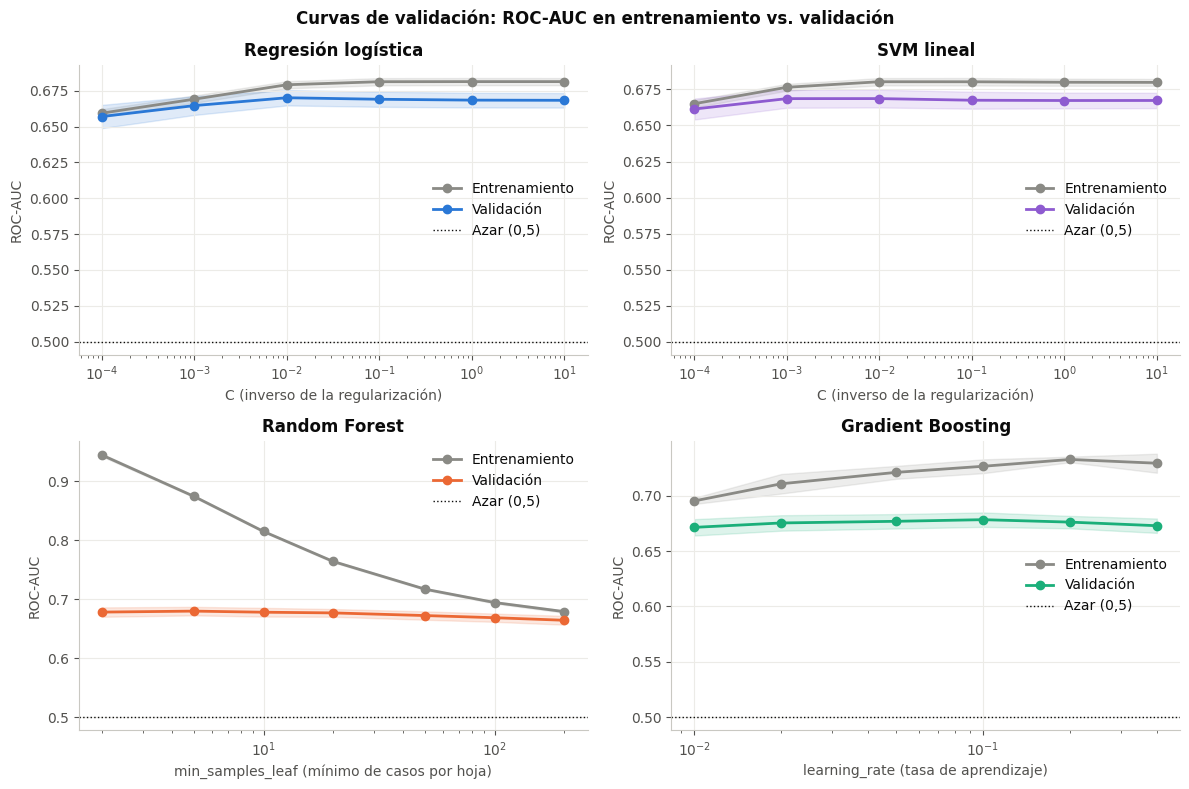

In [ ]:
# --------------------------------------------------------------------------- 2.3 Curvas de validación (un hiperparámetro a la vez, el resto fijo en su mejor valor)
rangos = {
    "Regresión logística": ("modelo__C", [0.0001, 0.001, 0.01, 0.1, 1, 10], "C (inverso de la regularización)"),
    "SVM lineal": ("modelo__estimator__C", [0.0001, 0.001, 0.01, 0.1, 1, 10], "C (inverso de la regularización)"),
    "Random Forest": ("modelo__min_samples_leaf", [2, 5, 10, 20, 50, 100, 200], "min_samples_leaf (mínimo de casos por hoja)"),
    "Gradient Boosting": ("modelo__learning_rate", [0.01, 0.02, 0.05, 0.1, 0.2, 0.4], "learning_rate (tasa de aprendizaje)"),
}
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for eje, (nombre, (param, valores, etiqueta)) in zip(ejes.ravel(), rangos.items()):
    entrenamiento, validacion = validation_curve(clone(buscadores[nombre].best_estimator_), X_bus, y_bus,
                                                 param_name=param, param_range=valores, groups=g_bus,
                                                 cv=cv_busqueda, scoring="roc_auc", n_jobs=-1)
    for curva, etiq, color in [(entrenamiento, "Entrenamiento", GRIS), (validacion, "Validación", COLOR_MODELO[nombre])]:
        eje.plot(valores, curva.mean(axis=1), marker="o", label=etiq, color=color)
        eje.fill_between(valores, curva.mean(axis=1) - curva.std(axis=1), curva.mean(axis=1) + curva.std(axis=1),
                         color=color, alpha=0.15)
    eje.axhline(0.5, color=TINTA, ls=":", lw=1, label="Azar (0,5)")
    eje.set_xscale("log"); eje.set_title(nombre); eje.set_xlabel(etiqueta); eje.set_ylabel("ROC-AUC"); eje.legend()
fig.suptitle("Curvas de validación: ROC-AUC en entrenamiento vs. validación", fontweight="bold")
plt.tight_layout(); plt.show()

Las curvas de validación muestran cómo cambia el ROC-AUC al variar un hiperparámetro, con los demás fijos en su mejor valor. En la regresión logística y el SVM lineal, un valor muy pequeño de C (regularización fuerte) produce subajuste: entrenamiento y validación quedan cerca de 0,66. Desde C ≈ 0,01 (regresión logística) y C ≈ 0,001 (SVM) el desempeño se estabiliza en torno a 0,670 y 0,668 en validación, con una brecha pequeña respecto al entrenamiento (≈ 0,01), por lo que estos modelos no sobreajustan. En el Random Forest, el ROC-AUC de entrenamiento baja de 0,95 a 0,68 al aumentar min_samples_leaf de 2 a 200, mientras que el de validación permanece casi constante (≈ 0,68) y disminuye ligeramente con valores altos; es decir, regularizar más cierra la brecha pero no mejora la capacidad de generalizar, y el modelo funciona mejor con hojas pequeñas. En el Gradient Boosting, aumentar la learning_rate eleva el ROC-AUC de entrenamiento de 0,70 a 0,73 sin mejorar la validación (máximo cercano a 0,678 con learning_rate ≈ 0,1), lo que indica que tasas altas solo aumentan el sobreajuste. En todos los casos las bandas de desviación entre pliegues se solapan, por lo que las diferencias entre valores cercanos del hiperparámetro no son significativas.

Regresión logística: curva de aprendizaje en 40 s | ROC-AUC con todo el entrenamiento: entrenamiento 0.682 vs. validación 0.679
SVM lineal: curva de aprendizaje en 46 s | ROC-AUC con todo el entrenamiento: entrenamiento 0.682 vs. validación 0.679
Random Forest: curva de aprendizaje en 186 s | ROC-AUC con todo el entrenamiento: entrenamiento 0.819 vs. validación 0.690
Gradient Boosting: curva de aprendizaje en 133 s | ROC-AUC con todo el entrenamiento: entrenamiento 0.708 vs. validación 0.691


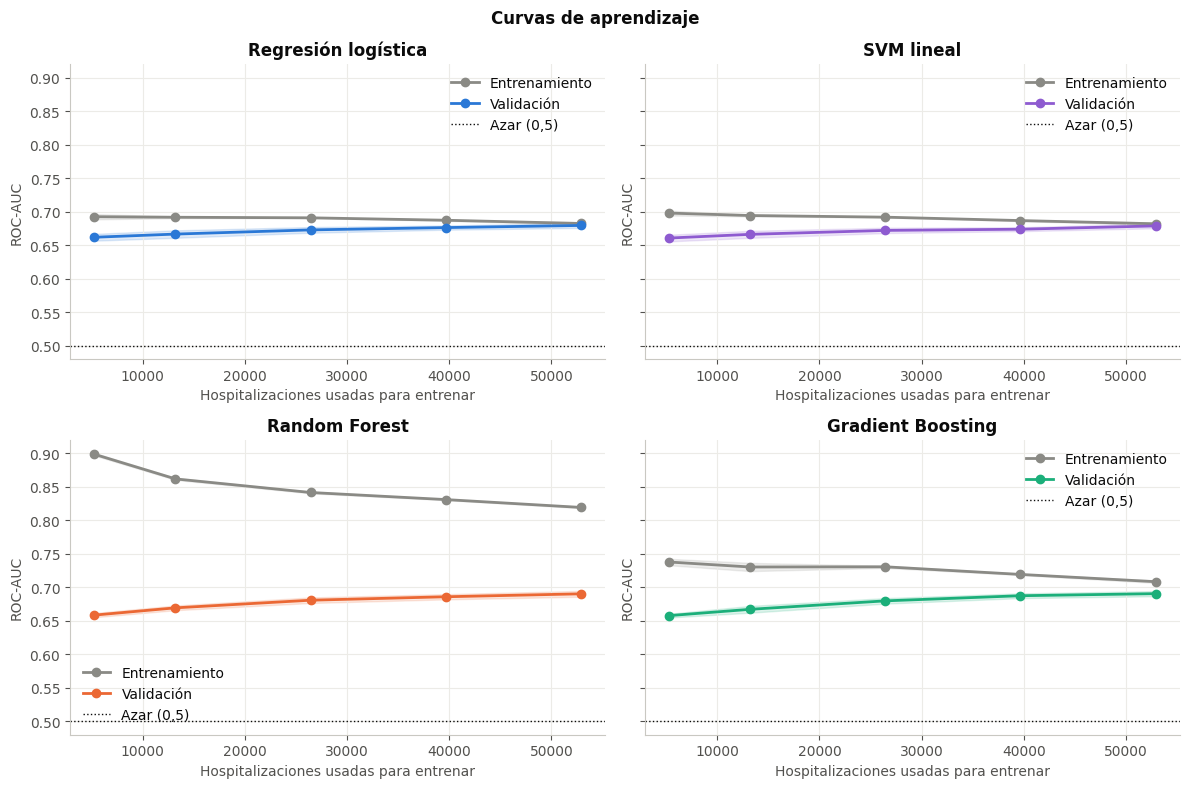

In [ ]:
# --------------------------------------------------------------------------- 2.4 Curvas de aprendizaje (todo el conjunto de entrenamiento, 3 pliegues por paciente)
tamanios = [0.1, 0.25, 0.5, 0.75, 1.0]
fig, ejes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for eje, nombre in zip(ejes.ravel(), buscadores):
    t0 = time.time()
    n_filas, entrenamiento, validacion = learning_curve(clone(buscadores[nombre].best_estimator_), X_train, y_train,
                                                        groups=g_train, cv=cv_busqueda, train_sizes=tamanios,
                                                        scoring="roc_auc", n_jobs=-1, random_state=SEMILLA)
    for curva, etiq, color in [(entrenamiento, "Entrenamiento", GRIS), (validacion, "Validación", COLOR_MODELO[nombre])]:
        eje.plot(n_filas, curva.mean(axis=1), marker="o", label=etiq, color=color)
        eje.fill_between(n_filas, curva.mean(axis=1) - curva.std(axis=1), curva.mean(axis=1) + curva.std(axis=1),
                         color=color, alpha=0.15)
    eje.axhline(0.5, color=TINTA, ls=":", lw=1, label="Azar (0,5)")
    eje.set_title(nombre); eje.set_xlabel("Hospitalizaciones usadas para entrenar"); eje.set_ylabel("ROC-AUC"); eje.legend()
    print(f"{nombre}: curva de aprendizaje en {time.time() - t0:.0f} s | ROC-AUC con todo el entrenamiento: "
          f"entrenamiento {entrenamiento[-1].mean():.3f} vs. validación {validacion[-1].mean():.3f}")
fig.suptitle("Curvas de aprendizaje", fontweight="bold")
plt.tight_layout(); plt.show()

Las curvas de aprendizaje muestran el ROC-AUC en entrenamiento y validación a medida que aumenta la cantidad de datos usados para entrenar (hasta unas 53.000 hospitalizaciones por pliegue). En la regresión logística y el SVM lineal, ambas curvas convergen hacia 0,68 (0,682 en entrenamiento y 0,679 en validación), lo que indica un modelo con sesgo alto: su capacidad está limitada por su forma lineal y agregar más datos no mejoraría el desempeño. En el Random Forest persiste una brecha amplia entre entrenamiento (0,819) y validación (0,690), señal de sobreajuste, aunque la curva de validación sigue creciendo con más datos. El Gradient Boosting presenta una brecha menor (0,708 contra 0,691) y una curva de validación que también sigue subiendo, por lo que es el que mejor equilibra ajuste y generalización. Los dos modelos de árboles superan a los lineales en validación (≈ 0,69 contra 0,68), pero la ventaja es de apenas un punto de ROC-AUC. En conjunto, la capacidad predictiva alcanzable con estas variables es modesta.

Línea base (azar): 5 pliegues en 32 s
Regresión logística: 5 pliegues en 48 s
SVM lineal: 5 pliegues en 49 s
Random Forest: 5 pliegues en 160 s
Gradient Boosting: 5 pliegues en 134 s


,ROC-AUC (val.),PR-AUC (val.),Exactitud (val.),ROC-AUC (entren.)
modelo,,,,
Línea base (azar),0.500 ± 0.000,0.471 ± 0.004,0.529 ± 0.004,0.500 ± 0.000
Regresión logística,0.679 ± 0.008,0.649 ± 0.013,0.631 ± 0.005,0.682 ± 0.002
SVM lineal,0.679 ± 0.009,0.649 ± 0.013,0.631 ± 0.006,0.682 ± 0.002
Random Forest,0.691 ± 0.008,0.659 ± 0.011,0.638 ± 0.006,0.812 ± 0.001
Gradient Boosting,0.691 ± 0.008,0.663 ± 0.013,0.639 ± 0.007,0.707 ± 0.002



Mejor modelo por ROC-AUC en validación cruzada: Gradient Boosting


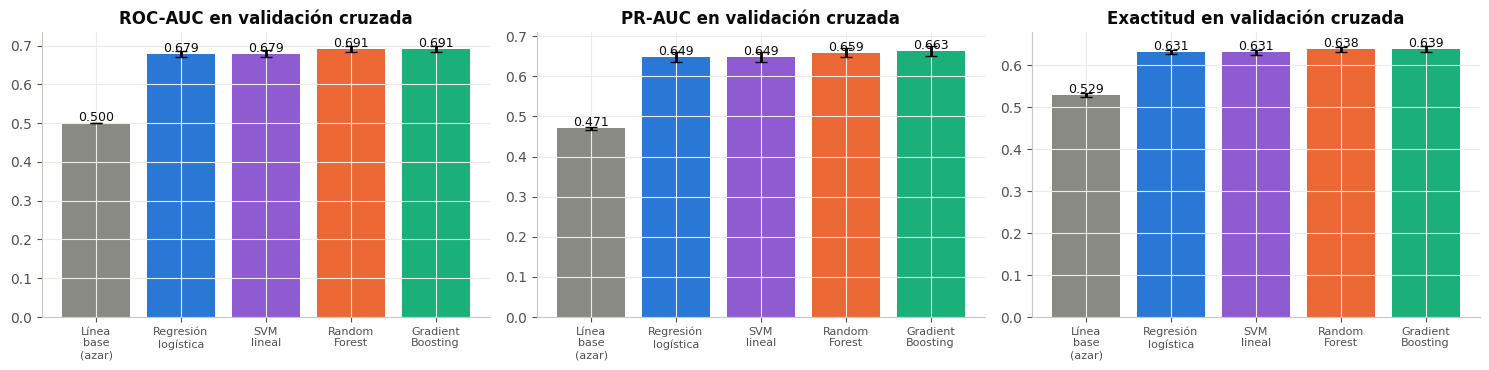

In [ ]:
# --------------------------------------------------------------------------- 2.5 Comparación final con validación cruzada de 5 pliegues (todo el entrenamiento)
candidatos = {"Línea base (azar)": armar(DummyClassifier(strategy="prior"))}
candidatos.update({n: clone(b.best_estimator_) for n, b in buscadores.items()})

filas_cv, oof = [], {}                       # oof: probabilidad "fuera de pliegue" de cada hospitalización de entrenamiento
for nombre, pipe in candidatos.items():
    t0 = time.time()
    oof[nombre] = np.zeros(len(y_train))
    por_pliegue = []
    for tr, va in cv_final.split(X_train, y_train, groups=g_train):
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        p_va, p_tr = m.predict_proba(X_train.iloc[va])[:, 1], m.predict_proba(X_train.iloc[tr])[:, 1]
        oof[nombre][va] = p_va
        por_pliegue.append({**{k + " (val.)": v for k, v in metricas_prob(y_train.iloc[va], p_va).items()},
                            "ROC-AUC (entren.)": roc_auc_score(y_train.iloc[tr], p_tr)})
    r = pd.DataFrame(por_pliegue)
    fila = {"modelo": nombre}
    for col in r.columns:
        fila[col] = f"{r[col].mean():.3f} ± {r[col].std():.3f}"
    fila["_ref"] = r["ROC-AUC (val.)"].mean()
    filas_cv.append(fila)
    print(f"{nombre}: 5 pliegues en {time.time() - t0:.0f} s")

tabla_cv = pd.DataFrame(filas_cv).set_index("modelo")
display(tabla_cv.drop(columns="_ref"))
mejor = tabla_cv.drop(index="Línea base (azar)")["_ref"].idxmax()
print(f"\nMejor modelo por ROC-AUC en validación cruzada: {mejor}")

# Gráfico comparativo (media ± desviación entre pliegues)
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
for eje, metrica in zip(ejes, ["ROC-AUC (val.)", "PR-AUC (val.)", "Exactitud (val.)"]):
    medias = [float(tabla_cv.loc[n, metrica].split(" ± ")[0]) for n in candidatos]
    desvios = [float(tabla_cv.loc[n, metrica].split(" ± ")[1]) for n in candidatos]
    colores = [GRIS] + [COLOR_MODELO[n] for n in candidatos if n in COLOR_MODELO]
    eje.bar(range(len(candidatos)), medias, yerr=desvios, color=colores, capsize=4)
    eje.set_xticks(range(len(candidatos)))
    eje.set_xticklabels([n.replace(" (azar)", "\n(azar)").replace(" ", "\n", 1) for n in candidatos], fontsize=8)
    eje.set_title(metrica.replace(" (val.)", " en validación cruzada"))
    for i, m in enumerate(medias): eje.text(i, m + 0.005, f"{m:.3f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

# Modelos finales: se reentrenan con TODO el entrenamiento (nunca con la partición de prueba)
modelos_finales = {n: clone(b.best_estimator_).fit(X_train, y_train) for n, b in buscadores.items()}

La comparación final se hizo con validación cruzada de 5 pliegues agrupada por paciente sobre todo el conjunto de entrenamiento. Todos los modelos superan a la línea base, que obtiene un ROC-AUC de 0,5 y una exactitud de 0,529 (equivalente a predecir siempre “No”).

La regresión logística y el SVM lineal obtienen resultados prácticamente idénticos (ROC-AUC de 0,679, PR-AUC de 0,649 y exactitud de 0,631). Su brecha entre entrenamiento y validación es mínima, lo que indica que no sobreajustan, pero su capacidad está limitada por ser modelos lineales.

Los modelos de árboles mejoran ligeramente. El Random Forest y el Gradient Boosting alcanzan un ROC-AUC de 0,691, con PR-AUC de 0,659 y 0,663, y exactitud de 0,638 y 0,639, respectivamente. El Random Forest sobreajusta mucho más (ROC-AUC de 0,812 en entrenamiento contra 0,691 en validación) que el Gradient Boosting (0,707 contra 0,691). La diferencia entre ambos modelos de árboles es menor que la desviación entre pliegues (≈ 0,008), por lo que su desempeño es equivalente.

Se seleccionó el Gradient Boosting por obtener el mayor ROC-AUC medio en validación cruzada (0,691, empatado con el Random Forest), el mayor PR-AUC y la mayor exactitud, y por sobreajustar menos. Los modelos se reentrenaron con todo el conjunto de entrenamiento y se evalúan en la sección 3 sobre la partición de prueba.

En conjunto, la capacidad predictiva es moderada: predecir si un paciente será readmitido con las variables disponibles es un problema difícil.

## **3. Evaluación del modelo**
---

En esta sección debe reportar el desempeño del modelo sobre la partición de datos de pruebas (test). Considere que dispone de las siguientes métricas:

- **Clasificación**: accuracy, precision, recall, f1-score, AUC, matriz de confusión, etc.
- **Regresión**: $r^2$, error cuadrático medio, error absoluto medio, etc.
- **Agrupamiento**: coeficiente de silueta, índice de Davies-Bouldin, etc.

Los resultados se deben presentar usando tablas y figuras además del análisis detallado respectivo.

In [ ]:
# --------------------------------------------------------------------------- 3.1 Evaluación sobre la partición de prueba (datos que el modelo nunca vio)
prob_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos_finales.items()}
linea_base = clone(candidatos["Línea base (azar)"]).fit(X_train, y_train)
prob_test_base = linea_base.predict_proba(X_test)[:, 1]

# Umbral alternativo: el que maximiza F1 con las predicciones fuera de pliegue del ENTRENAMIENTO (nunca con la prueba)
umbrales = {}
for nombre in modelos_finales:
    prec, rec, thr = precision_recall_curve(y_train, oof[nombre])
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    umbrales[nombre] = thr[np.argmax(f1)]

def evaluar(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {"Exactitud": accuracy_score(y_real, pred), "Precisión": precision_score(y_real, pred, zero_division=0),
            "Recall": recall_score(y_real, pred), "F1": f1_score(y_real, pred)}

# (a) Métricas que no dependen del umbral
tabla_auc = pd.DataFrame({
    "Línea base (azar)": {"ROC-AUC": roc_auc_score(y_test, prob_test_base), "PR-AUC": average_precision_score(y_test, prob_test_base)},
    **{n: {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)} for n, p in prob_test.items()}}).T
print("Métricas independientes del umbral (partición de prueba):")
display(tabla_auc.round(4))

# (b) Métricas con umbral: 0,5 (el estándar) y el umbral que maximiza F1 en validación cruzada
filas = [{"modelo": "Línea base (azar)", "umbral": "0,50", **evaluar(y_test, prob_test_base, 0.5)}]
for nombre, p in prob_test.items():
    filas.append({"modelo": nombre, "umbral": "0,50", **evaluar(y_test, p, 0.5)})
    filas.append({"modelo": nombre, "umbral": f"{umbrales[nombre]:.2f} (óptimo F1)", **evaluar(y_test, p, umbrales[nombre])})
print("\nMétricas con umbral de decisión (partición de prueba):")
display(pd.DataFrame(filas).set_index(["modelo", "umbral"]).round(4))

Métricas independientes del umbral (partición de prueba):


,ROC-AUC,PR-AUC
Línea base (azar),0.5000,0.4707
Regresión logística,0.6835,0.6555
SVM lineal,0.6827,0.6547
Random Forest,0.6923,0.6664
Gradient Boosting,0.6934,0.6672



Métricas con umbral de decisión (partición de prueba):


Exactitud  Precisión  Recall      F1
modelo              umbral                                                
Línea base (azar)   0,50                 0.5293     0.0000  0.0000  0.0000
Regresión logística 0,50                 0.6298     0.6389  0.4907  0.5551
                    0.34 (óptimo F1)     0.5659     0.5226  0.8986  0.6608
SVM lineal          0,50                 0.6307     0.6401  0.4922  0.5565
                    0.36 (óptimo F1)     0.5660     0.5226  0.8992  0.6611
Random Forest       0,50                 0.6385     0.6426  0.5224  0.5763
                    0.37 (óptimo F1)     0.5807     0.5329  0.8830  0.6647
Gradient Boosting   0,50                 0.6404     0.6406  0.5379  0.5848
                    0.33 (óptimo F1)     0.5765     0.5299  0.8889  0.6640

Los modelos se evaluaron sobre la partición de prueba (20 % de los datos, separada por paciente), que no se usó en el entrenamiento ni en la selección de hiperparámetros. El Gradient Boosting obtuvo el mejor ROC-AUC (0,693), seguido de cerca por el Random Forest (0,692) y, algo más abajo, por la regresión logística (0,683) y el SVM lineal (0,683); todos superan ampliamente a la línea base (0,5). Los valores son muy similares a los de la validación cruzada (0,691 en el Gradient Boosting), lo que indica que el modelo generaliza a pacientes nuevos y que no hubo sobreajuste a la validación. Con el umbral estándar de 0,5, el Gradient Boosting alcanza una exactitud de 0,640 (frente a 0,529 de la línea base), una precisión de 0,641, un recall de 0,538 y un F1 de 0,585: de cada 100 hospitalizaciones clasifica correctamente unas 64, y detecta algo más de la mitad de las readmisiones reales. Al usar el umbral que maximiza el F1 en validación cruzada (≈ 0,33), el recall sube a 0,889, pero la precisión baja a 0,530 y la exactitud a 0,577. Este umbral hace que el modelo marque como readmitidos a casi todos los pacientes, por lo que el aumento del F1 no representa una mejora real de la capacidad predictiva. En conjunto, el desempeño es moderado: el modelo ordena a los pacientes por riesgo mejor que el azar, pero no permite predecir con certeza quién será readmitido.

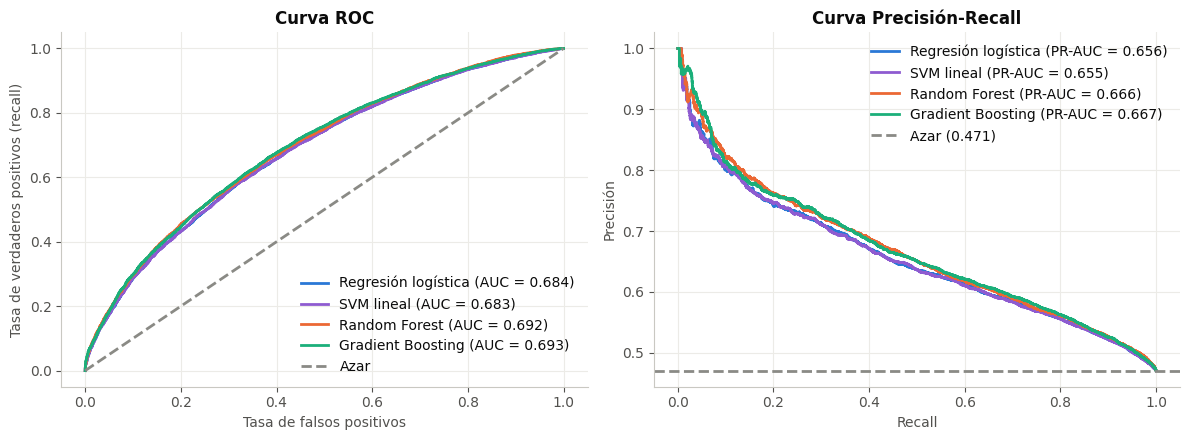

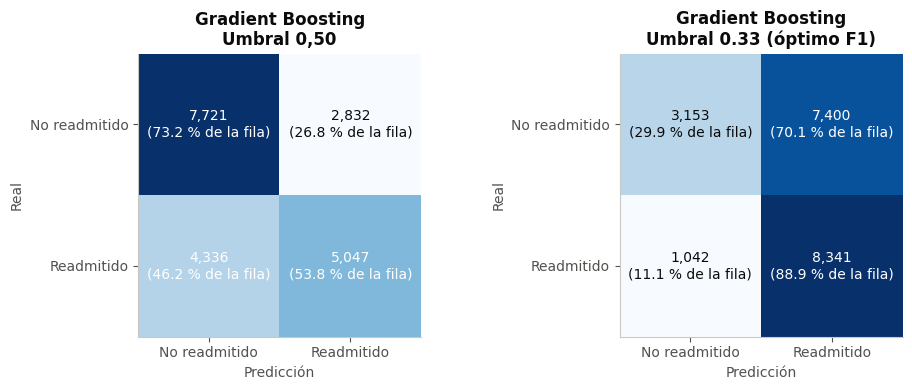

In [ ]:
# --------------------------------------------------------------------------- 3.2 Curvas ROC y Precisión-Recall, y matrices de confusión
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, p in prob_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ejes[0].plot(fpr, tpr, color=COLOR_MODELO[nombre], label=f"{nombre} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ejes[1].plot(rec, prec, color=COLOR_MODELO[nombre], label=f"{nombre} (PR-AUC = {average_precision_score(y_test, p):.3f})")
ejes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", label="Azar")
ejes[0].set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)")
ejes[1].axhline(y_test.mean(), color=GRIS, ls="--", label=f"Azar ({y_test.mean():.3f})")
ejes[1].set(title="Curva Precisión-Recall", xlabel="Recall", ylabel="Precisión")
for eje in ejes: eje.legend(loc="upper right" if eje is ejes[1] else "lower right")
plt.tight_layout(); plt.show()

# Matrices de confusión del mejor modelo con los dos umbrales
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, (umbral, titulo) in zip(ejes, [(0.5, "Umbral 0,50"), (umbrales[mejor], f"Umbral {umbrales[mejor]:.2f} (óptimo F1)")]):
    cm = confusion_matrix(y_test, (prob_test[mejor] >= umbral).astype(int))
    eje.imshow(cm, cmap="Blues"); eje.grid(False)
    for i in range(2):
        for j in range(2):
            eje.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum() * 100:.1f} % de la fila)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else TINTA)
    eje.set_xticks([0, 1]); eje.set_xticklabels(["No readmitido", "Readmitido"])
    eje.set_yticks([0, 1]); eje.set_yticklabels(["No readmitido", "Readmitido"])
    eje.set(title=f"{mejor}\n{titulo}", xlabel="Predicción", ylabel="Real")
plt.tight_layout(); plt.show()

Las curvas ROC y Precisión-Recall de los cuatro modelos son muy parecidas entre sí y se ubican claramente por encima de la línea de azar (ROC-AUC de 0,684, 0,683, 0,692 y 0,693 para la regresión logística, el SVM lineal, el Random Forest y el Gradient Boosting; PR-AUC de 0,656 a 0,667 frente a 0,471 del azar). Los dos modelos de árboles quedan ligeramente por encima de los lineales, pero la diferencia es pequeña. En la curva Precisión-Recall se observa que la precisión es alta (cercana a 0,9) para el grupo de pacientes con mayor probabilidad predicha y disminuye progresivamente hasta la tasa general de readmisión (0,47) al aumentar el recall, lo que indica que el modelo sí concentra las readmisiones en los pacientes que califica como de mayor riesgo. Las matrices de confusión del Gradient Boosting muestran el intercambio entre errores según el umbral. Con 0,50, el modelo clasifica correctamente al 73,2 % de los pacientes no readmitidos y al 53,8 % de los readmitidos, con 2.832 falsos positivos y 4.336 falsos negativos. Con 0,33, el modelo detecta al 88,9 % de los readmitidos, pero clasifica erróneamente como readmitidos al 70,1 % de los no readmitidos (7.400 falsos positivos), por lo que casi todos los pacientes terminan marcados como “Sí” y la exactitud cae a 0,577. Por esta razón se toma el umbral de 0,50 como referencia principal, y el umbral de 0,33 sirve únicamente para mostrar que el recall se puede aumentar a costa de la precisión. El umbral adecuado dependería del costo relativo de no detectar una readmisión frente al de dar seguimiento a un paciente que no la necesitaba.

10 hospitalizaciones de prueba con mayor probabilidad de readmisión según el modelo:


,prob_readmision,prediccion,real,number_inpatient,number_emergency,discharge_disposition_id,time_in_hospital,num_medications,diag_1_grupo
76525,0.945,Sí,Sí,10,4,1,7,21,Diabetes
99053,0.944,Sí,Sí,8,6,1,2,13,Diabetes
38644,0.940,Sí,Sí,8,4,6,6,18,Circulatorio
79202,0.940,Sí,Sí,11,5,1,1,10,Diabetes
75267,0.940,Sí,Sí,9,4,1,2,11,Diabetes
76907,0.939,Sí,Sí,11,4,1,4,23,Otros
74876,0.939,Sí,Sí,9,4,1,2,8,Diabetes
82693,0.938,Sí,Sí,11,5,7,2,15,Otros
79467,0.937,Sí,Sí,12,5,1,1,8,Diabetes
78200,0.936,Sí,Sí,9,4,18,8,32,Circulatorio



Deciles de probabilidad (10 = el 10 % con mayor probabilidad de readmisión según el modelo):


,hospitalizaciones,readmitidos,tasa_real,prob_media,lift
decil,,,,,
10,1994,1547,0.776,0.759,1.648
9,1993,1328,0.666,0.641,1.416
8,1994,1146,0.575,0.575,1.221
7,1993,1072,0.538,0.521,1.143
6,1994,967,0.485,0.478,1.030
5,1993,892,0.448,0.439,0.951
4,1994,786,0.394,0.399,0.838
3,1993,662,0.332,0.355,0.706
2,1994,579,0.290,0.302,0.617


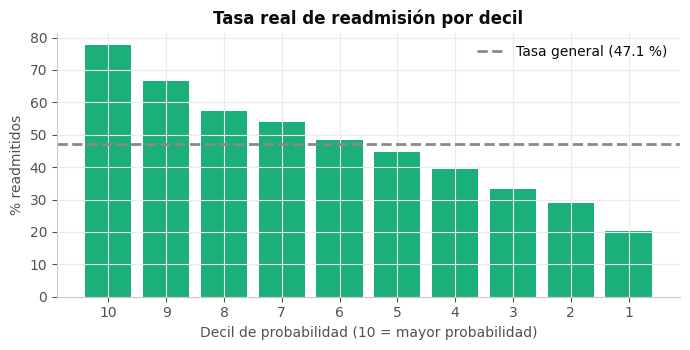

In [ ]:
# --------------------------------------------------------------------------- 3.3 Resultado final: el modelo aplicado a los datos de prueba
# No se usó un modelo pre-entrenado: los modelos se entrenaron desde cero con los datos del proyecto.
resultado = X_test.copy()
resultado["prob_readmision"] = prob_test[mejor]
resultado["prediccion"] = np.where(resultado["prob_readmision"] >= 0.5, "Sí", "No")
resultado["real"] = np.where(y_test.to_numpy() == 1, "Sí", "No")
columnas_ver = ["prob_readmision", "prediccion", "real", "number_inpatient", "number_emergency",
                "discharge_disposition_id", "time_in_hospital", "num_medications", "diag_1_grupo"]
print("10 hospitalizaciones de prueba con mayor probabilidad de readmisión según el modelo:")
display(resultado.sort_values("prob_readmision", ascending=False)[columnas_ver].head(10).round(3))

# Deciles: ¿los pacientes que el modelo marca como de mayor probabilidad realmente reingresan más?
resultado["y"] = y_test.to_numpy()
resultado["decil"] = pd.qcut(resultado["prob_readmision"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
deciles = resultado.groupby("decil").agg(hospitalizaciones=("y", "size"), readmitidos=("y", "sum"),
                                         tasa_real=("y", "mean"), prob_media=("prob_readmision", "mean"))
deciles["lift"] = deciles["tasa_real"] / y_test.mean()
deciles = deciles.sort_index(ascending=False)
print("\nDeciles de probabilidad (10 = el 10 % con mayor probabilidad de readmisión según el modelo):")
display(deciles.round(3))

fig, eje = plt.subplots(figsize=(7, 3.6))
eje.bar(deciles.index.astype(str), deciles["tasa_real"] * 100, color=COLOR_MODELO[mejor])
eje.axhline(y_test.mean() * 100, color=GRIS, ls="--", label=f"Tasa general ({y_test.mean() * 100:.1f} %)")
eje.set(xlabel="Decil de probabilidad (10 = mayor probabilidad)", ylabel="% readmitidos", title="Tasa real de readmisión por decil")
eje.legend(); plt.tight_layout(); plt.show()

Para mostrar el resultado final de aplicar el modelo sobre la partición de prueba se ordenaron las 19.936 hospitalizaciones según la probabilidad de readmisión predicha por el Gradient Boosting y se dividieron en diez grupos de igual tamaño (deciles). No se utilizó un modelo pre-entrenado: los modelos se entrenaron desde cero con los datos del proyecto. La tasa real de readmisión aumenta de forma monótona con el decil de probabilidad, desde 20,3 % en el 10 % de pacientes con menor probabilidad hasta 77,6 % en el 10 % con mayor probabilidad, es decir, unas 3,8 veces más. Frente a la tasa general de readmisión (47,1 %), el decil de mayor probabilidad tiene un lift de 1,65 y el de menor probabilidad de 0,43. Además, la probabilidad media predicha en cada decil es cercana a la frecuencia real observada (por ejemplo, 0,759 frente a 0,776 en el decil 10), lo que sugiere que las probabilidades del modelo están razonablemente calibradas. El 30 % de pacientes con mayor probabilidad concentra el 42,9 % de las readmisiones (4.021 de 9.383). Los diez pacientes con mayor probabilidad predicha (entre 0,936 y 0,945) fueron readmitidos efectivamente y comparten un perfil de muchas hospitalizaciones previas en el último año (8 a 12) y varias visitas a urgencias (4 a 6). En resumen, aunque el modelo no permite predecir con certeza el caso individual, sí permite priorizar: los pacientes con mayor probabilidad predicha reingresan con una frecuencia mucho mayor que los de menor probabilidad.

## **4. Aplicación del modelo**
---

Una vez que haya entrenado y evaluado su modelo, es importante considerar cómo puede ser utilizado en un entorno práctico.

Intente analizar la capacidad del modelo para generalizar nuevos datos que no formaron parte del conjunto de entrenamiento o evaluación.

In [ ]:
# --------------------------------------------------------------------------- 4.1 Generalización: entrenamiento vs. validación cruzada vs. prueba + intervalos de confianza
# Se remuestrean PACIENTES (no filas) para que el intervalo respete que un mismo paciente aporta varias hospitalizaciones
rng = np.random.default_rng(SEMILLA)
pac_test, inversa = np.unique(g_test, return_inverse=True)
yt = y_test.to_numpy()
p_mejor, p_lr = prob_test[mejor], prob_test["Regresión logística"]

def metricas_ponderadas(p, w, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {"ROC-AUC": roc_auc_score(yt, p, sample_weight=w), "PR-AUC": average_precision_score(yt, p, sample_weight=w),
            "Exactitud": accuracy_score(yt, pred, sample_weight=w), "Precisión": precision_score(yt, pred, sample_weight=w, zero_division=0),
            "Recall": recall_score(yt, pred, sample_weight=w)}

boot, dif = [], []
for _ in range(N_BOOTSTRAP):
    veces = np.bincount(rng.integers(0, len(pac_test), len(pac_test)), minlength=len(pac_test))
    w = veces[inversa]
    m = metricas_ponderadas(p_mejor, w)
    boot.append(m)
    dif.append({"ROC-AUC": m["ROC-AUC"] - roc_auc_score(yt, p_lr, sample_weight=w),
                "Exactitud": m["Exactitud"] - accuracy_score(yt, (p_lr >= 0.5).astype(int), sample_weight=w)})
boot, dif = pd.DataFrame(boot), pd.DataFrame(dif)
puntual = metricas_ponderadas(p_mejor, np.ones(len(yt)))

resumen = pd.DataFrame({"Prueba (estimación)": puntual, "IC 95 % inferior": boot.quantile(0.025), "IC 95 % superior": boot.quantile(0.975)})
print(f"{mejor}: métricas en prueba (umbral 0,50) con intervalo de confianza al 95 % ({N_BOOTSTRAP} remuestreos por paciente)")
display(resumen.round(4))
print(f"\nDiferencia {mejor} - Regresión logística (IC 95 %):")
display(pd.DataFrame({"diferencia media": dif.mean(), "IC 95 % inferior": dif.quantile(0.025), "IC 95 % superior": dif.quantile(0.975)}).round(4))

# ¿Se mantiene el desempeño entre entrenamiento, validación cruzada y prueba?
p_entren = modelos_finales[mejor].predict_proba(X_train)[:, 1]
comparacion = pd.DataFrame({
    "Entrenamiento (reajustado)": metricas_prob(y_train, p_entren),
    "Validación cruzada (5 pliegues)": metricas_prob(y_train, oof[mejor]),
    "Prueba (nunca vista)": metricas_prob(y_test, p_mejor)}).T
print("\nPara el mejor modelo:")
display(comparacion.round(4))

Gradient Boosting: métricas en prueba (umbral 0,50) con intervalo de confianza al 95 % (300 remuestreos por paciente)


,Prueba (estimación),IC 95 % inferior,IC 95 % superior
ROC-AUC,0.6934,0.6856,0.7014
PR-AUC,0.6672,0.6515,0.6826
Exactitud,0.6404,0.6341,0.6474
Precisión,0.6406,0.6286,0.6532
Recall,0.5379,0.5261,0.5505



Diferencia Gradient Boosting - Regresión logística (IC 95 %):


,diferencia media,IC 95 % inferior,IC 95 % superior
ROC-AUC,0.0099,0.0075,0.0125
Exactitud,0.0107,0.0067,0.0150



Para el mejor modelo:


,ROC-AUC,PR-AUC,Exactitud
Entrenamiento (reajustado),0.7046,0.6766,0.6486
Validación cruzada (5 pliegues),0.6910,0.6626,0.6392
Prueba (nunca vista),0.6934,0.6672,0.6404


Para estimar la incertidumbre de las métricas se aplicó un remuestreo bootstrap de 300 repeticiones sobre la partición de prueba, remuestreando pacientes y no hospitalizaciones, para respetar que un mismo paciente aporta varios registros. El Gradient Boosting obtuvo en prueba un ROC-AUC de 0,693 (IC 95 %: 0,686 a 0,701), una exactitud de 0,640 (0,634 a 0,647), una precisión de 0,641 (0,629 a 0,653) y un recall de 0,538 (0,526 a 0,551), con el umbral de 0,50. Los intervalos son estrechos, por lo que el desempeño es estable. Respecto a la capacidad de generalización, el ROC-AUC es 0,705 en entrenamiento, 0,691 en validación cruzada y 0,693 en prueba: la brecha entre entrenamiento y prueba es pequeña y el resultado en prueba coincide con el de la validación cruzada, lo que indica que el modelo no sobreajusta y que se puede esperar un desempeño similar con pacientes nuevos del mismo tipo de población. Frente a la regresión logística, el Gradient Boosting mejora el ROC-AUC en 0,010 (IC 95 %: 0,008 a 0,013) y la exactitud en 1,1 puntos porcentuales (0,7 a 1,5); como los intervalos no incluyen el cero, la ventaja es estadísticamente consistente, aunque de magnitud pequeña.

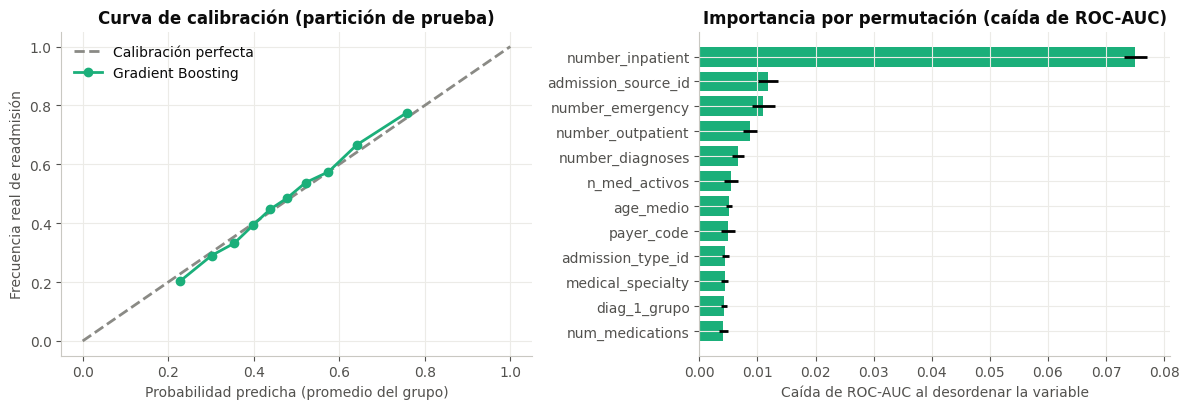

Desempeño del mejor modelo por subgrupo (partición de prueba, umbral 0,50):


hospitalizaciones  % readmitidos  ROC-AUC  \
variable   grupo                                                        
gender     FEMALE                       10699         48.154    0.701   
           MALE                          9237         45.805    0.684   
race       AfricanAmerican               3704         46.760    0.692   
           Caucasian                    14920         47.936    0.691   
           Desconocido                    457         28.228    0.651   
           Hispanic                       427         45.199    0.731   
           Other                          305         43.279    0.662   
grupo_edad <40                           1272         44.811    0.791   
           40-59                         5308         44.706    0.710   
           60-79                         9484         47.775    0.680   
           80+                           3872         49.303    0.656   

                            Exactitud  
variable   grupo                       
gender     FEMALE               0.646  
           MALE                 0.634  
race       AfricanAmerican      0.637  
           Caucasian            0.638  
           Desconocido          0.720  
           Hispanic             0.667  
           Other                0.643  
grupo_edad <40                  0.731  
           40-59                0.656  
           60-79                0.631  
           80+                  0.613

In [ ]:
# --------------------------------------------------------------------------- 4.2 Calibración, importancia de variables y estabilidad por subgrupos
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

# Calibración: ¿la probabilidad que da el modelo equivale a la frecuencia real de readmisión?
frec_real, prob_prom = calibration_curve(y_test, p_mejor, n_bins=10, strategy="quantile")
ejes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", label="Calibración perfecta")
ejes[0].plot(prob_prom, frec_real, marker="o", color=COLOR_MODELO[mejor], label=mejor)
ejes[0].set(title="Curva de calibración (partición de prueba)", xlabel="Probabilidad predicha (promedio del grupo)",
            ylabel="Frecuencia real de readmisión")
ejes[0].legend()

# Importancia por permutación sobre las variables ORIGINALES (el pipeline incluye el preprocesamiento)
muestra = X_test.sample(n=min(10000, len(X_test)), random_state=SEMILLA)
imp = permutation_importance(modelos_finales[mejor], muestra, y_test.loc[muestra.index], scoring="roc_auc",
                             n_repeats=5, random_state=SEMILLA, n_jobs=-1)
orden = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(12)
ejes[1].barh(orden.index, orden.to_numpy(), xerr=pd.Series(imp.importances_std, index=X_test.columns)[orden.index].to_numpy(),
             color=COLOR_MODELO[mejor])
ejes[1].set(title="Importancia por permutación (caída de ROC-AUC)", xlabel="Caída de ROC-AUC al desordenar la variable")
plt.tight_layout(); plt.show()

# Estabilidad por subgrupos: el modelo no debería funcionar mucho peor en algún grupo de pacientes
subgrupos = X_test[["gender", "race"]].copy()
subgrupos["grupo_edad"] = pd.cut(X_test["age_medio"], [0, 40, 60, 80, 100], labels=["<40", "40-59", "60-79", "80+"], right=False)
filas = []
for variable in ["gender", "race", "grupo_edad"]:
    for valor, idx in subgrupos.groupby(variable, observed=True).groups.items():
        pos = X_test.index.get_indexer(idx)
        if len(pos) >= 300 and 0 < yt[pos].sum() < len(pos):
            filas.append({"variable": variable, "grupo": valor, "hospitalizaciones": len(pos), "% readmitidos": yt[pos].mean() * 100,
                          "ROC-AUC": roc_auc_score(yt[pos], p_mejor[pos]),
                          "Exactitud": accuracy_score(yt[pos], (p_mejor[pos] >= 0.5).astype(int))})
print("Desempeño del mejor modelo por subgrupo (partición de prueba, umbral 0,50):")
display(pd.DataFrame(filas).set_index(["variable", "grupo"]).round(3))

La curva de calibración sobre la partición de prueba muestra que las probabilidades del Gradient Boosting coinciden de forma cercana con la frecuencia real de readmisión: por ejemplo, en el grupo con probabilidad media de 0,76 reingresa el 77 % de los pacientes, y solo en el extremo de menor probabilidad se observa una ligera sobreestimación (0,23 predicho frente a 0,20 observado). Por lo tanto, la probabilidad que entrega el modelo puede interpretarse directamente como riesgo de readmisión. La importancia por permutación indica que la variable más influyente es el número de hospitalizaciones previas (number_inpatient), cuya permutación reduce el ROC-AUC en 0,075, muy por encima de las demás. Le siguen, con caídas de 0,004 a 0,012, la fuente de admisión, el número de visitas a urgencias y a consulta externa, el número de diagnósticos, el número de medicamentos activos y la edad. Es decir, el historial de uso del hospital es mucho más informativo que el diagnóstico principal o los medicamentos del episodio actual. El desempeño por subgrupos es estable entre mujeres (ROC-AUC de 0,701) y hombres (0,684) y entre pacientes afroamericanos (0,692) y caucásicos (0,691). La diferencia más marcada se da por edad: el ROC-AUC disminuye de 0,791 en menores de 40 años a 0,710 entre 40 y 59, 0,680 entre 60 y 79 y 0,656 en mayores de 80, lo que indica que el modelo discrimina peor en pacientes de mayor edad, donde la readmisión es más frecuente y menos predecible con estas variables. Los grupos de raza “Desconocido”, “Hispanic” y “Other” tienen menos de 500 hospitalizaciones, por lo que sus métricas son inestables y no permiten conclusiones.

In [ ]:
# --------------------------------------------------------------------------- 4.3 Uso práctico: priorizar pacientes y guardar el modelo
filas = []
orden_riesgo = np.argsort(-p_mejor, kind="stable")
for porcentaje in [10, 20, 30, 50]:
    k = int(np.ceil(len(yt) * porcentaje / 100))
    top = orden_riesgo[:k]
    filas.append({"% de altas con seguimiento": porcentaje, "pacientes a contactar": k, "readmisiones capturadas": int(yt[top].sum()),
                  "% de readmisiones capturadas": yt[top].sum() / yt.sum() * 100, "% que realmente reingresa (precisión)": yt[top].mean() * 100,
                  "veces mejor que el azar (lift)": yt[top].mean() / yt.mean()})
print("Si el hospital solo puede hacer seguimiento a una fracción de las altas (priorizando por probabilidad):")
display(pd.DataFrame(filas).set_index("% de altas con seguimiento").round(2))

# Guardar el modelo completo (preprocesamiento + modelo) y usarlo con un registro nuevo
joblib.dump({"modelo": modelos_finales[mejor], "umbral": 0.5, "columnas": list(X_train.columns)}, "modelo_readmision.joblib")
paquete = joblib.load("modelo_readmision.joblib")
nuevo = X_test.iloc[[0]]                                   # en producción: una fila con las mismas 33 variables
prob = paquete["modelo"].predict_proba(nuevo[paquete["columnas"]])[0, 1]
print(f"\nPaciente nuevo (ejemplo): probabilidad de readmisión = {prob:.1%} -> "
      f"{'Sí' if prob >= paquete['umbral'] else 'No'} (umbral = {paquete['umbral']:.2f}); real = {'Sí' if y_test.iloc[0] == 1 else 'No'}")

Si el hospital solo puede hacer seguimiento a una fracción de las altas (priorizando por probabilidad):


,pacientes a contactar,readmisiones capturadas,% de readmisiones capturadas,% que realmente reingresa (precisión),veces mejor que el azar (lift)
% de altas con seguimiento,,,,,
10,1994,1547,16.49,77.58,1.65
20,3988,2876,30.65,72.12,1.53
30,5981,4021,42.85,67.23,1.43
50,9968,6060,64.58,60.79,1.29



Paciente nuevo (ejemplo): probabilidad de readmisión = 30.9% -> No (umbral = 0.50); real = No


Para ilustrar el uso práctico del modelo se simuló un escenario en el que el hospital solo puede dar seguimiento a una fracción de las altas, priorizando a los pacientes con mayor probabilidad de readmisión. Con el 10 % de las altas (1.994 pacientes), el 77,6 % reingresa realmente, es decir, 1,65 veces la tasa general de readmisión (47,1 %), y se capturan 1.547 de las 9.383 readmisiones (16,5 %). Al ampliar el seguimiento al 20 %, 30 % y 50 % de las altas se capturan el 30,7 %, 42,9 % y 64,6 % de las readmisiones, con una precisión que disminuye a 72,1 %, 67,2 % y 60,8 %. Existe, por tanto, un intercambio entre cobertura y precisión, y la fracción adecuada dependería del costo del seguimiento y de la capacidad del hospital. Finalmente, el modelo completo (preprocesamiento y Gradient Boosting) se guardó en un archivo para poder aplicarlo a pacientes nuevos; en un ejemplo con un paciente de la partición de prueba, el modelo estimó una probabilidad de readmisión de 30,9 % y lo clasificó como “No”, coincidiendo con el valor real.

El modelo seleccionado, un Gradient Boosting, alcanza un ROC-AUC de 0,693 y una exactitud de 0,640 sobre pacientes nuevos, con intervalos de confianza estrechos y sin sobreajuste, y supera de forma consistente, aunque modesta, a la regresión logística. Sus probabilidades están bien calibradas, y la variable más importante es el número de hospitalizaciones previas. El modelo sirve para priorizar pacientes por riesgo, pero no para predecir con certeza el caso individual: la capacidad predictiva con las variables disponibles es moderada. Entre las limitaciones están que los datos provienen de 130 hospitales de Estados Unidos entre 1999 y 2008, por lo que el modelo debe validarse antes de aplicarlo a otra población, que su desempeño es menor en pacientes de mayor edad, y que la variable de respuesta agrupa readmisiones antes y después de 30 días, por lo que no mide el indicador estándar de calidad hospitalaria (readmisión a 30 días). Un paciente nuevo debe pasar por la misma preparación de datos de la fase anterior antes de entrar al modelo.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*